# 03 · Programmatic DSP geo-experiments: two vendors, two designs, one triangulated readout

**Business question.** Two programmatic display vendors (DSPs) both report cheap quote starts (QS). Vendor-reported
conversions are view-through-heavy, so how many quotes would have happened anyway? For each vendor we design a
geo **holdout**: ads are paused in a set of zips, and the volume we lose estimates the channel's incremental contribution.

* **Vendor A** serves zip-level targets. The design is a *contiguous treatment patch* against a *Mahalanobis-matched
  twin patch*, kept outside a spillover buffer.
* **Vendor B** buys on an inclusion list and recently switched reporting. The design is a *geo-weighted K-means
  cluster* against a *synthetic control* built from the other clusters, with the cluster picked by a tournament.

Everything runs on the synthetic world in `incrlab.simulate`, where the true incremental effect is known. Each estimate
is scored against the truth. The analysis code lives in `src/incrlab/dsp/`, and this notebook narrates one run of
`python -m incrlab.dsp`.

In [1]:
import os, sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
from incrlab.dsp import pipeline as DP
FIG = ROOT / "reports/figures/dsp"
show = lambda name, w=900: display(Image(filename=str(FIG / f"{name}.png"), width=w))

## 0. Run the whole program
A single call runs both designs, realizes both holdouts with `simulate.run_scenario` on the selected zips, runs every
readout method, and writes the figures, `reports/results/dsp.json` and `reports/readouts/dsp.md`. The design steps only
see weeks up to their design date (`tests/test_dsp.py` checks this by blanking all later data).

In [2]:
run = DP.run(figures=True)
A, B, R, P = run.A, run.B, run.R, run.params
print({k: round(v, 1) for k, v in run.timings.items()}, "| figures:", len(run.figures))

{'load': 0.3, 'design_a': 13.6, 'design_b': 18.8, 'readout': 31.1, 'figures': 51.3} | figures: 29


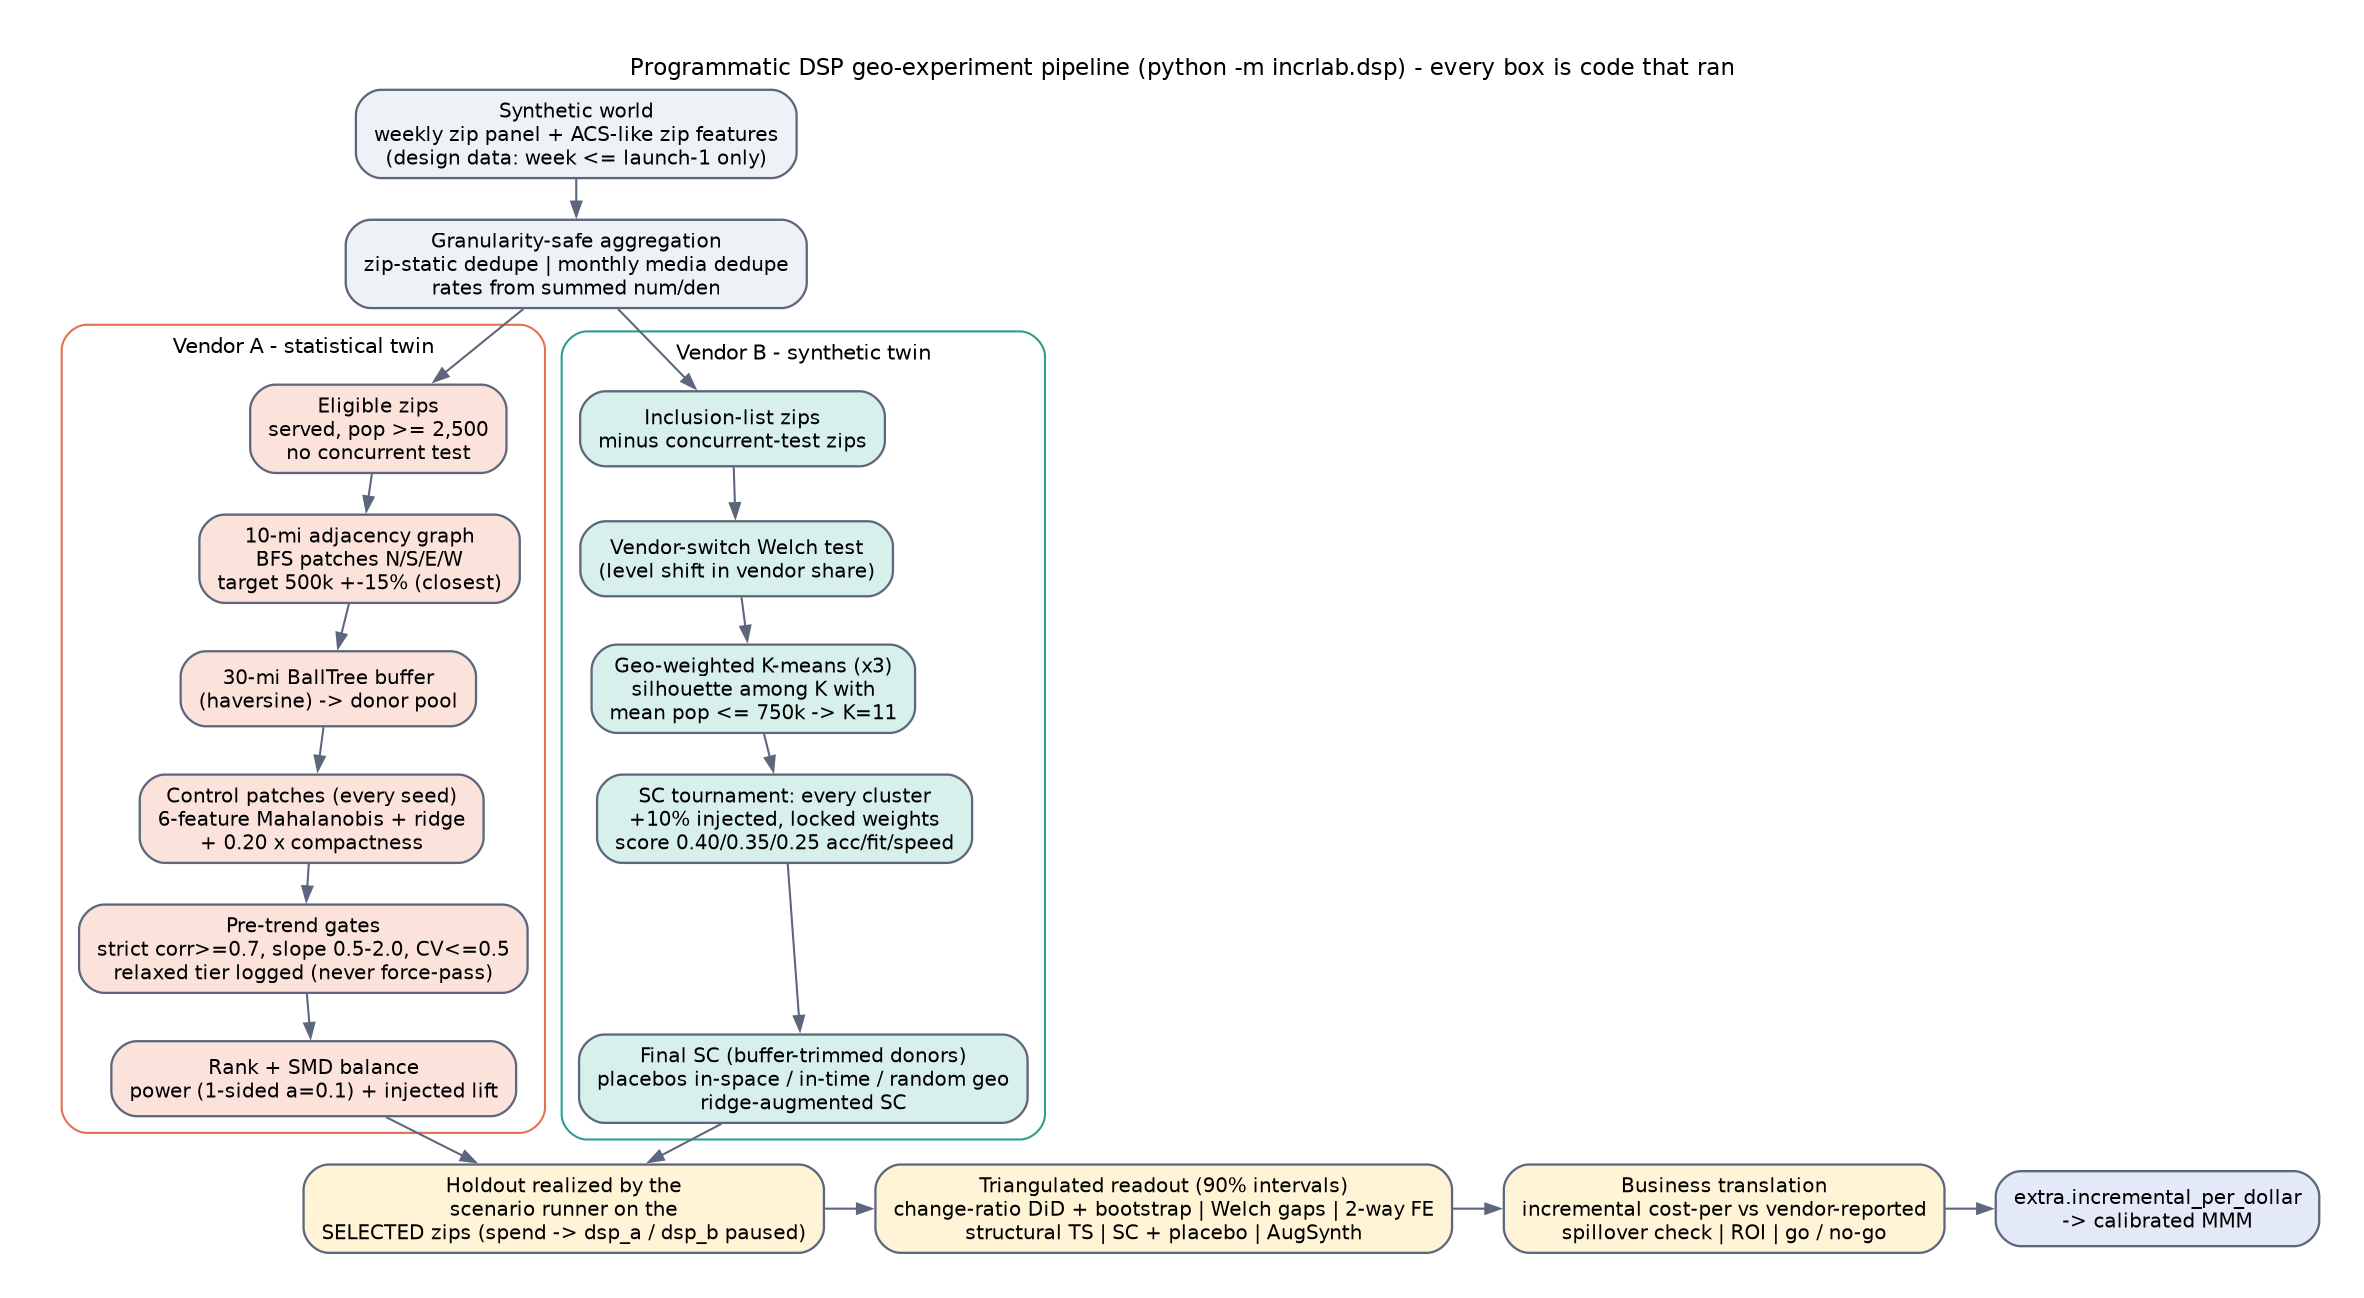

In [3]:
show('01_pipeline_flowchart', 1000)

## 1. Vendor A: contiguous treatment patches
The eligible universe is vendor-served zips above a minimum population, minus zips in a concurrent test. In the
largest counties a 10-mile adjacency graph (BallTree with haversine distance, networkx) is grown by breadth-first
search from each extreme zip. The patch stops at the population **closest to the target**. The original rule stopped at
the lower bound and systematically under-sized the patch; the figure shows both.

In [4]:
print(f"buffer = {A.params.buffer_miles} mi, pop target = {A.params.pop_target:,.0f} ± {A.params.pop_tolerance:.0%}")
print("excluded:", {k: len(v) for k, v in A.excluded.items()})
A.patches.head(8)

buffer = 30.0 mi, pop target = 1,000,000 ± 15%
excluded: {'not_served': 150, 'below_pop_floor': 43, 'concurrent_test': 0}


,patch_id,county_id,county,direction,seed,zips,n_zips,pop,in_window,pop_gap_pct,pop_if_stop_at_lower,spread_mi
0,NV-C11:North,NV-C11,Ironwood County,North,NV0416,"[NV0416, NV0392, NV0399, NV0406, NV0407, NV040...",21,998063.0,True,-0.001937,882719.0,4.278338
1,NV-C11:South,NV-C11,Ironwood County,South,NV0304,"[NV0304, NV0305, NV0307, NV0316, NV0313, NV031...",35,1076134.0,True,0.076134,877709.0,4.842174
2,NV-C11:East,NV-C11,Ironwood County,East,NV0335,"[NV0335, NV0325, NV0334, NV0336, NV0338, NV034...",36,979785.0,True,-0.020215,862233.0,4.116577
3,NV-C11:West,NV-C11,Ironwood County,West,NV0328,"[NV0328, NV0309, NV0314, NV0320, NV0326, NV033...",33,1031910.0,True,0.031910,870683.0,5.011922


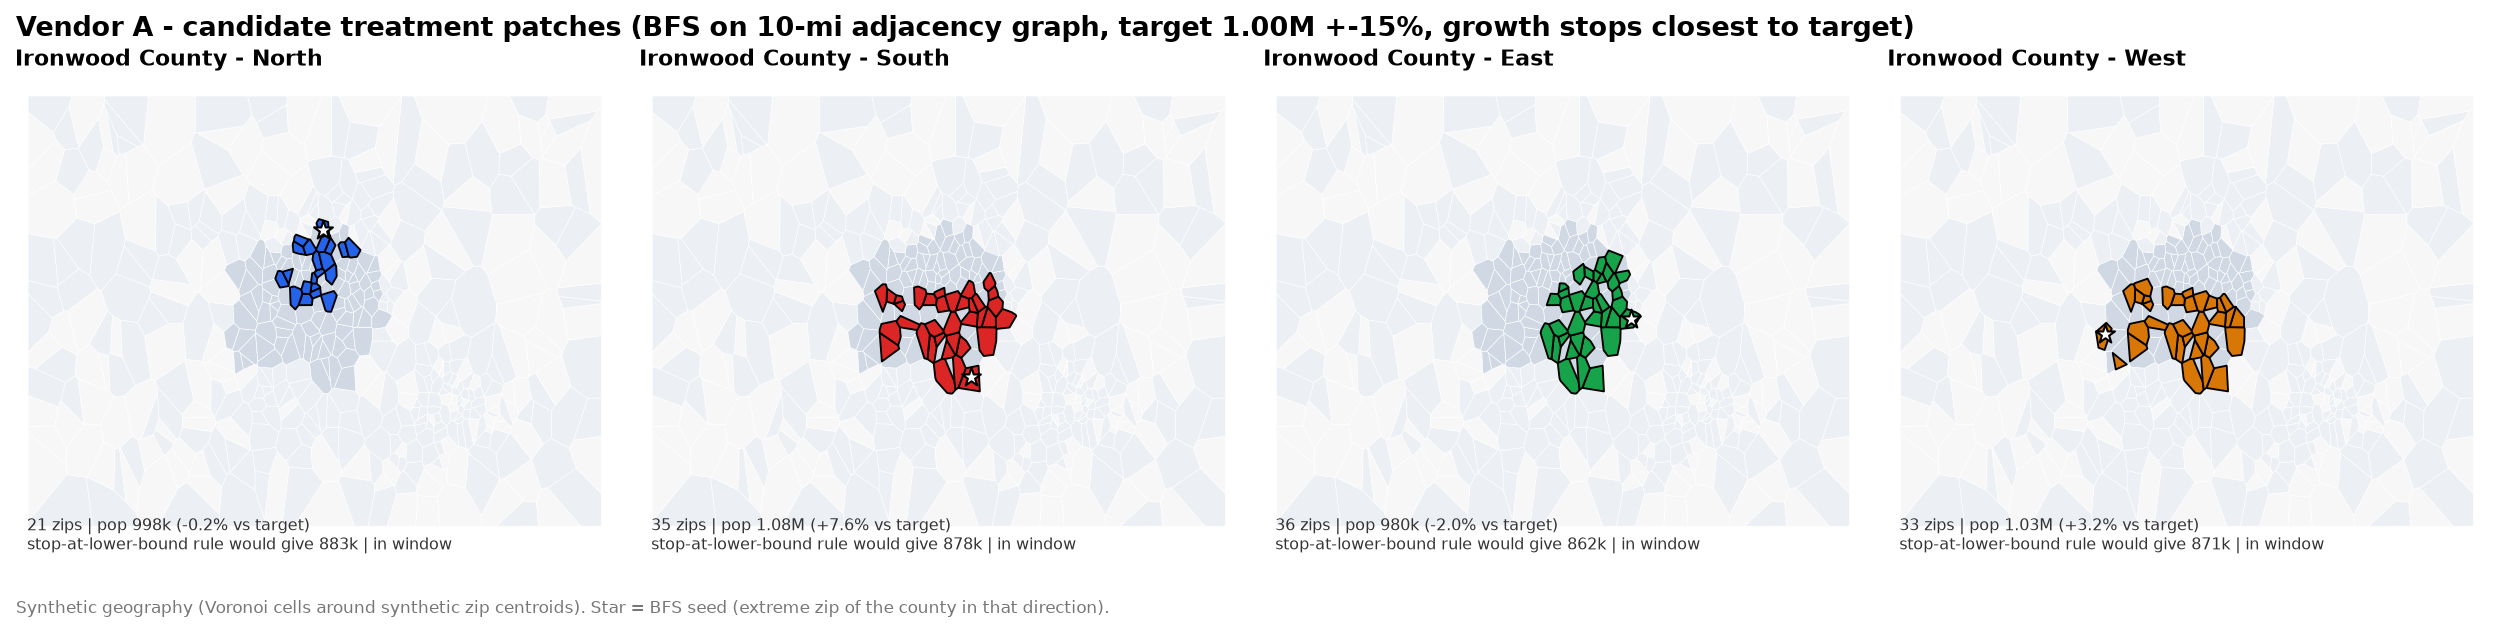

In [5]:
show('02_a_treatment_patches')

### Spillover buffer and donor pool
Donor zips must sit more than `buffer_miles` from every treatment zip; this is a BallTree `count_only` query. The same
parameter draws the dashed line on every map, so the chart and the code cannot disagree. The original notebooks said
"100 mi" in the charts and used 30 mi in code.

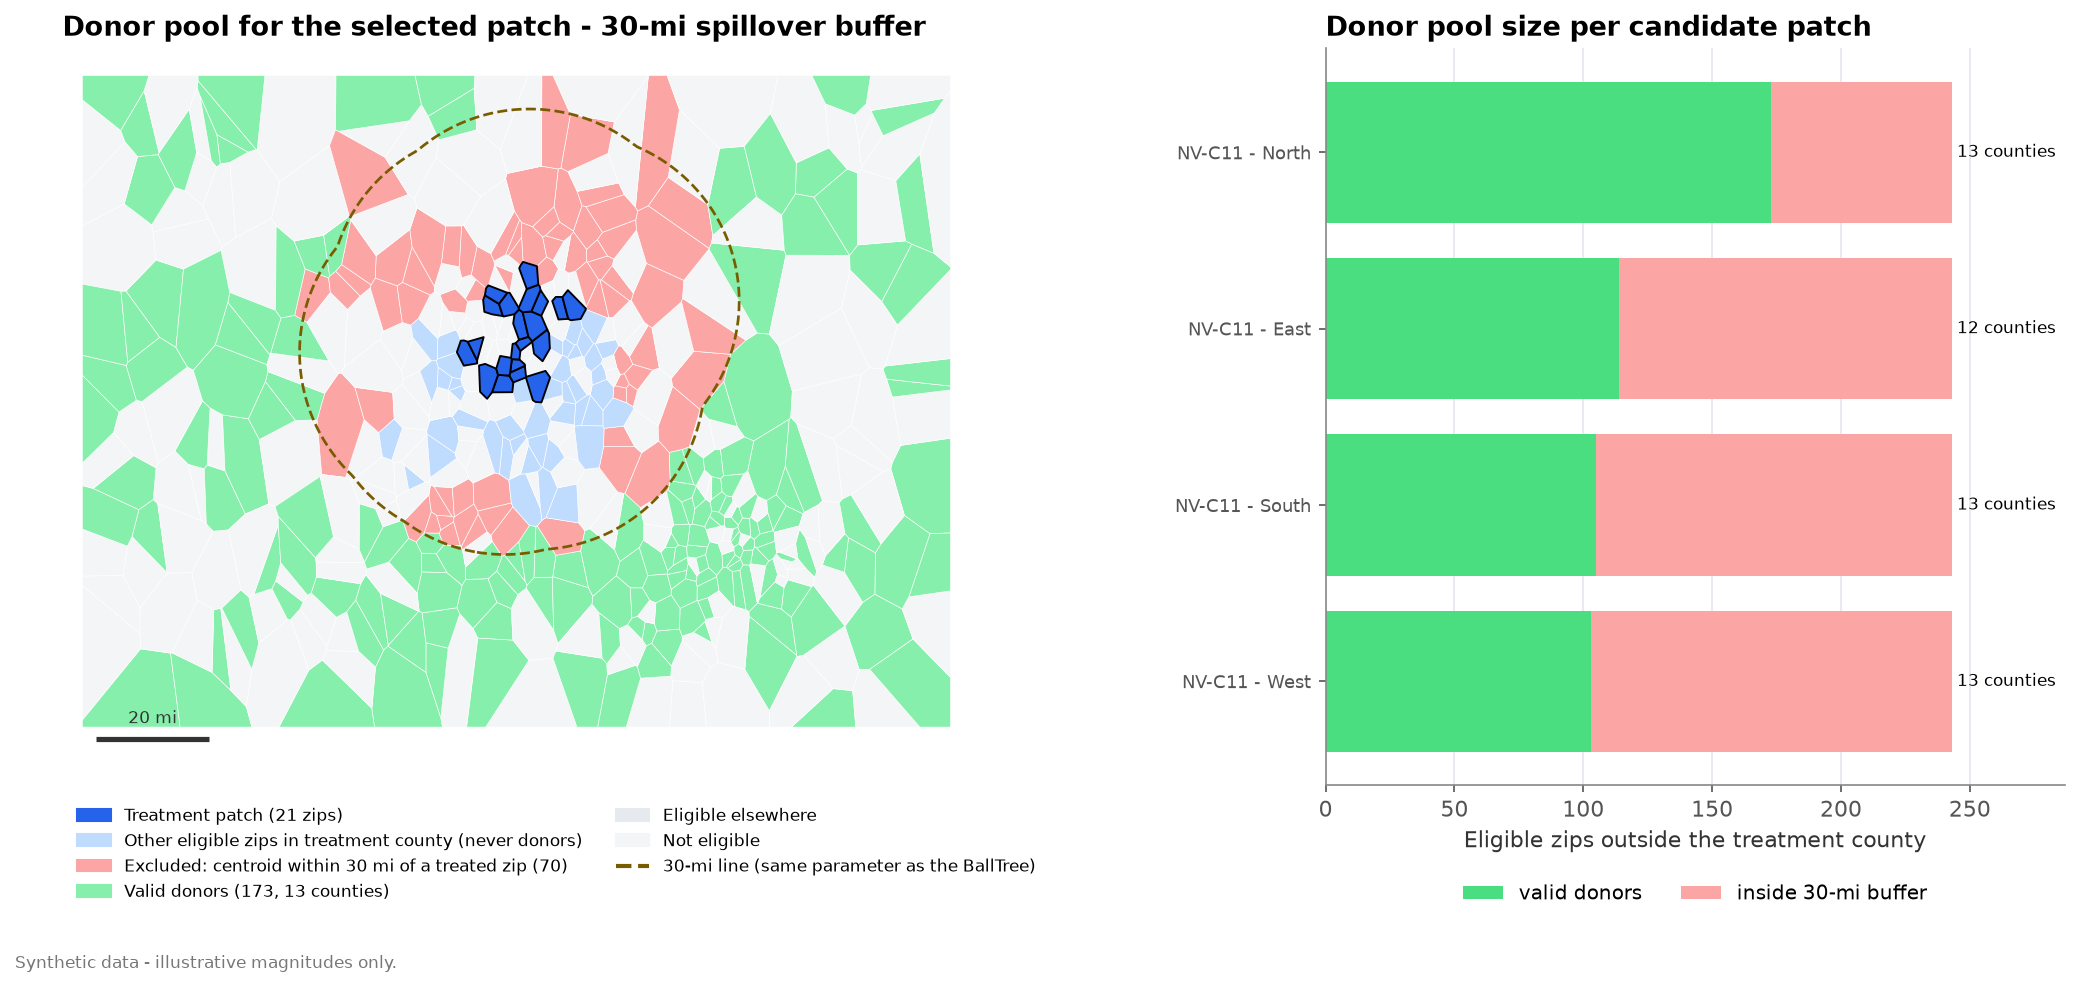

In [6]:
show('03_a_donor_pool_buffer')

## 2. Vendor A: matching the control patch
Every unique BFS patch in the donor pool is scored by a 6-feature Mahalanobis distance (standardised, ridge-regularised
correlation) plus a compactness penalty. Features are population-weighted, and rates are recomputed from sums.
The correlation between features shows why Mahalanobis matters here: income and education are strongly collinear.

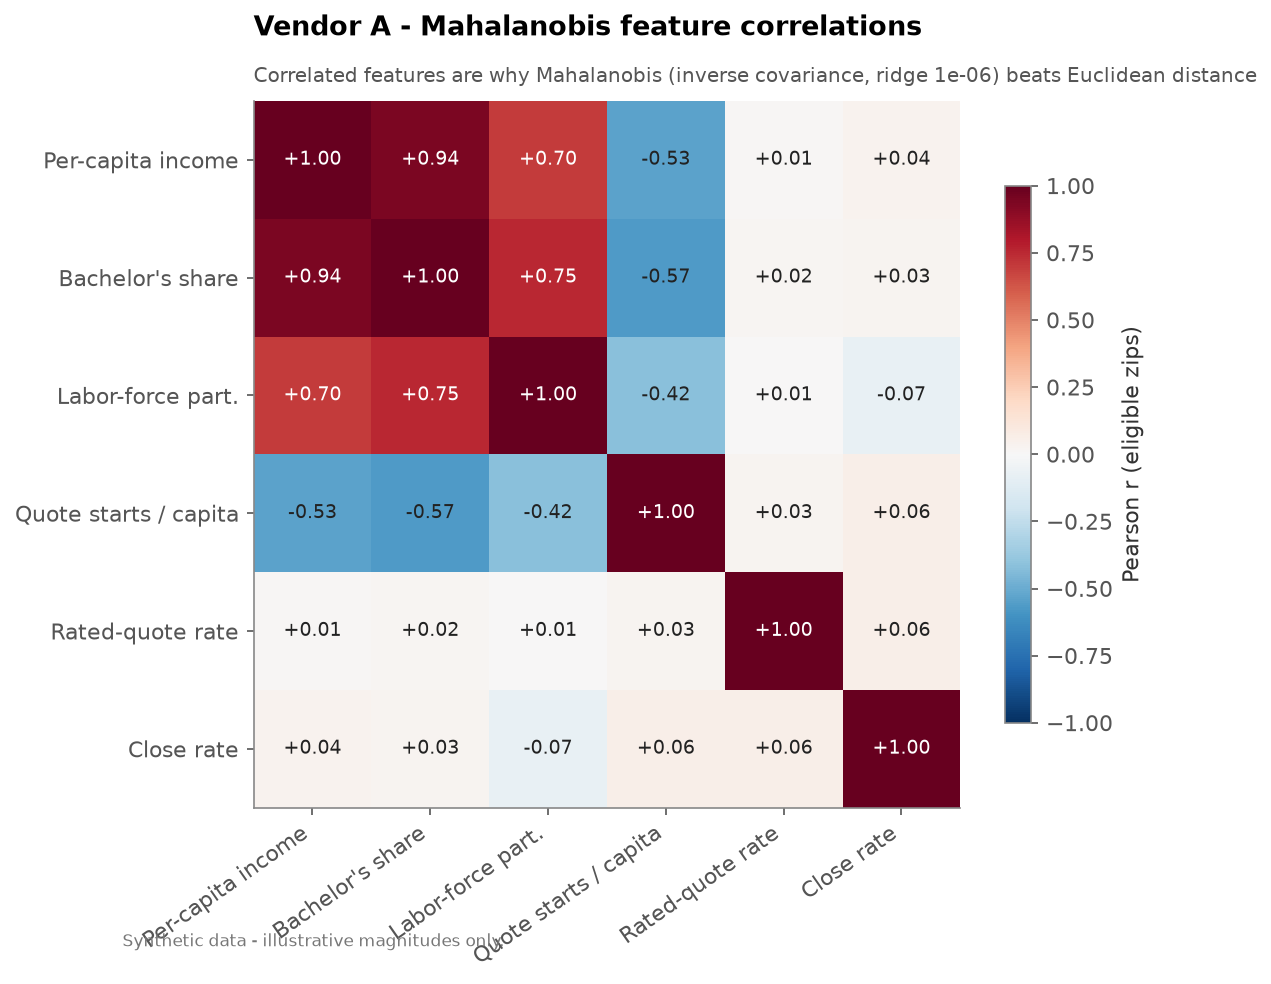

In [7]:
show('04_a_feature_correlation', 700)

The top candidates then go through the **pre-trend gates**: week-over-week correlation, slope ratio and CV. They run
in a strict tier and a relaxed tier, and both are logged. Nothing is force-passed. The original flipped a failing pair
to `pass=True`.

In [8]:
cols = [c for c in ["t_label", "c_label", "maha", "composite", "wow_corr", "slope_ratio", "tier", "fail_reasons",
                    "weeks_to_detect", "placebo_drift", "rank"] if c in A.candidates.columns]
A.candidates[cols].head(10).round(3)

,maha,composite,wow_corr,slope_ratio,tier,placebo_drift,rank
0,1.694,1.781,0.836,1.985,strict,0.065,1
1,1.695,1.784,0.839,1.923,strict,0.066,2
2,1.702,1.782,0.804,2.389,relaxed,0.064,3
3,1.706,1.790,0.825,2.034,relaxed,0.062,4
4,1.808,1.873,0.693,0.931,relaxed,0.005,5
5,1.826,1.913,0.545,1.075,fail,0.040,6
6,1.934,2.008,0.569,0.996,fail,0.049,7
7,1.946,2.015,0.615,1.095,fail,0.059,8


In [9]:
print('\n'.join(A.validation_log[-6:]))

sizing decision (POWERED): 1000k pop - smallest holdout whose strict-gate pair detects 20% on sales at 80% power (MDE 19.7%)
eligible zips: 307 of 500 (served, pop >= 2,500, not in another test)
treatment patches: 4 from counties ['NV-C11']; in window: 4
scored 70 unique control patches; kept top 5 per (treatment patch, control county) -> 8 candidates
validation: 2/8 pass strict gates (0.7, 0.5, 2.0, 0.5); 3 more pass relaxed gates (0.65, 0.4, 2.5, 0.6)
winner: NV-C11:North vs Kingsmere County | maha=1.69 wow_corr=0.84 tier=strict


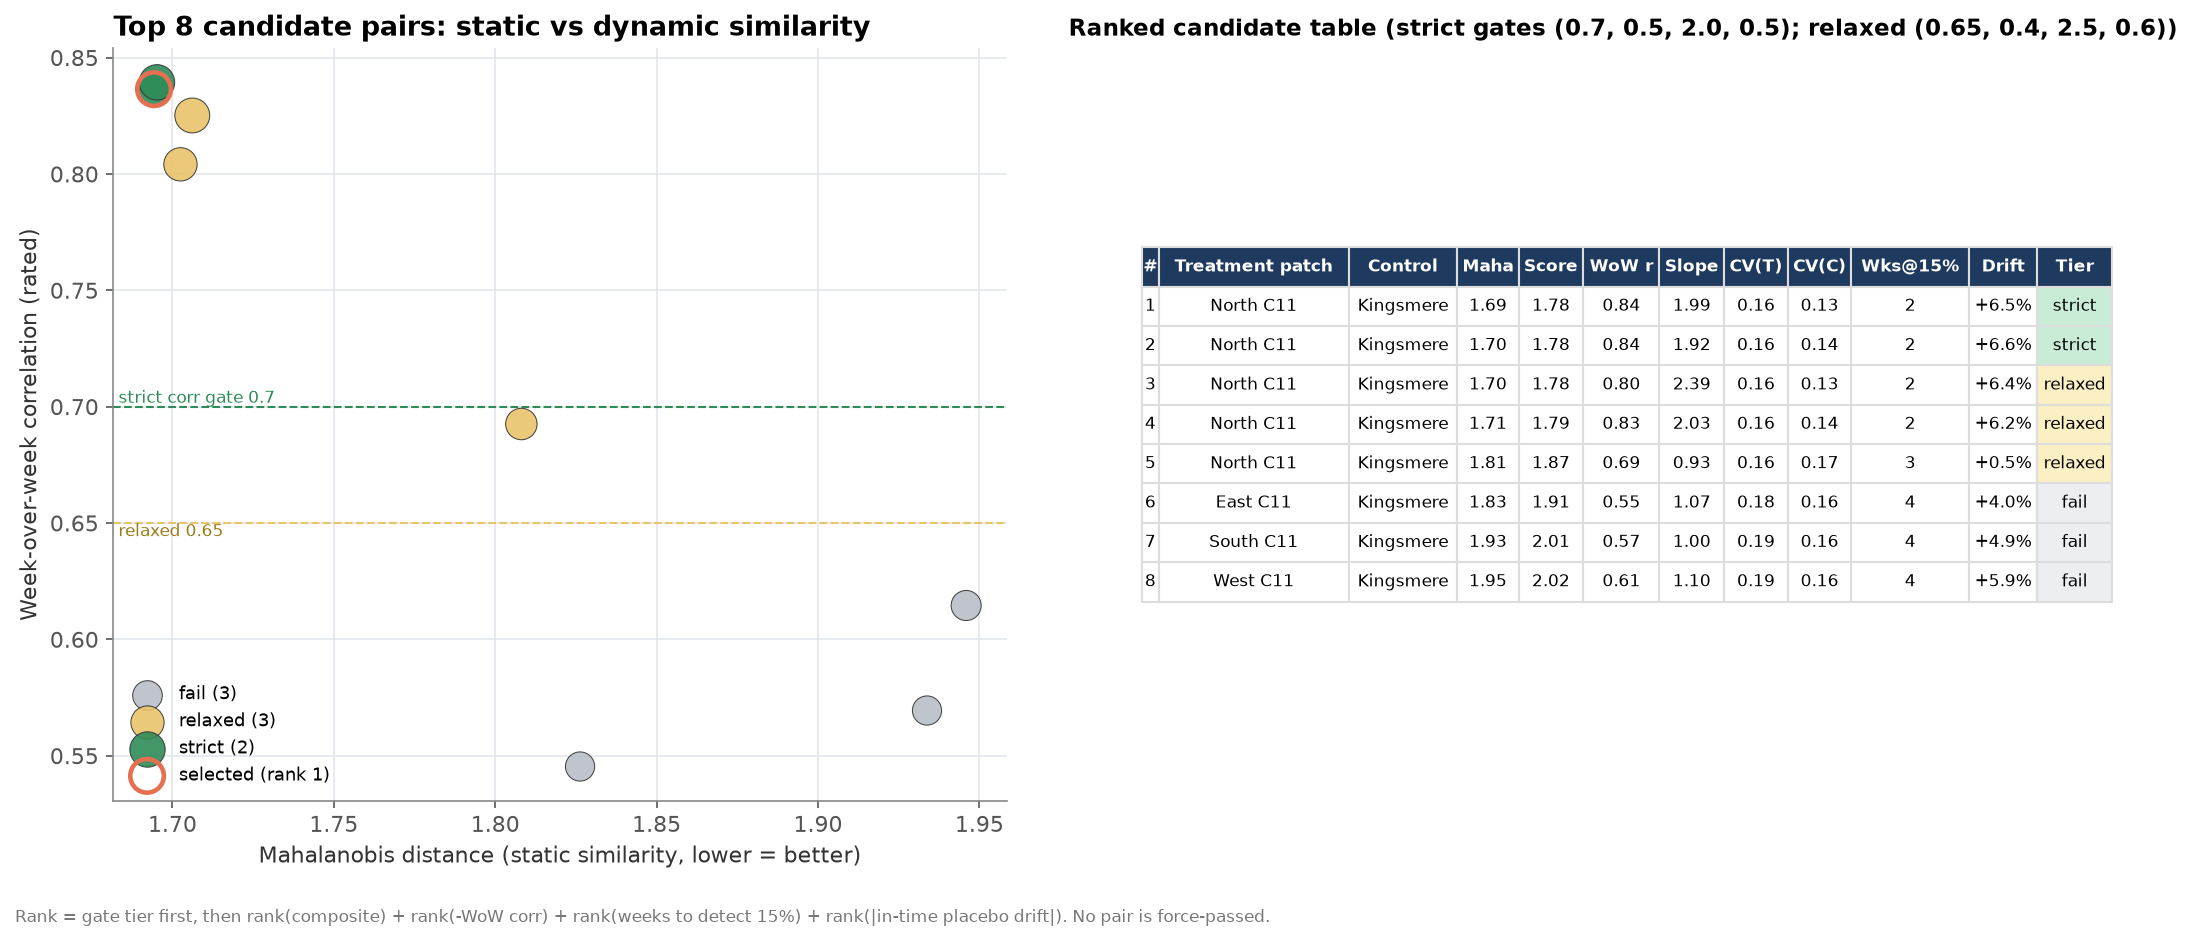

In [10]:
show('05_a_candidate_ranking', 1000)

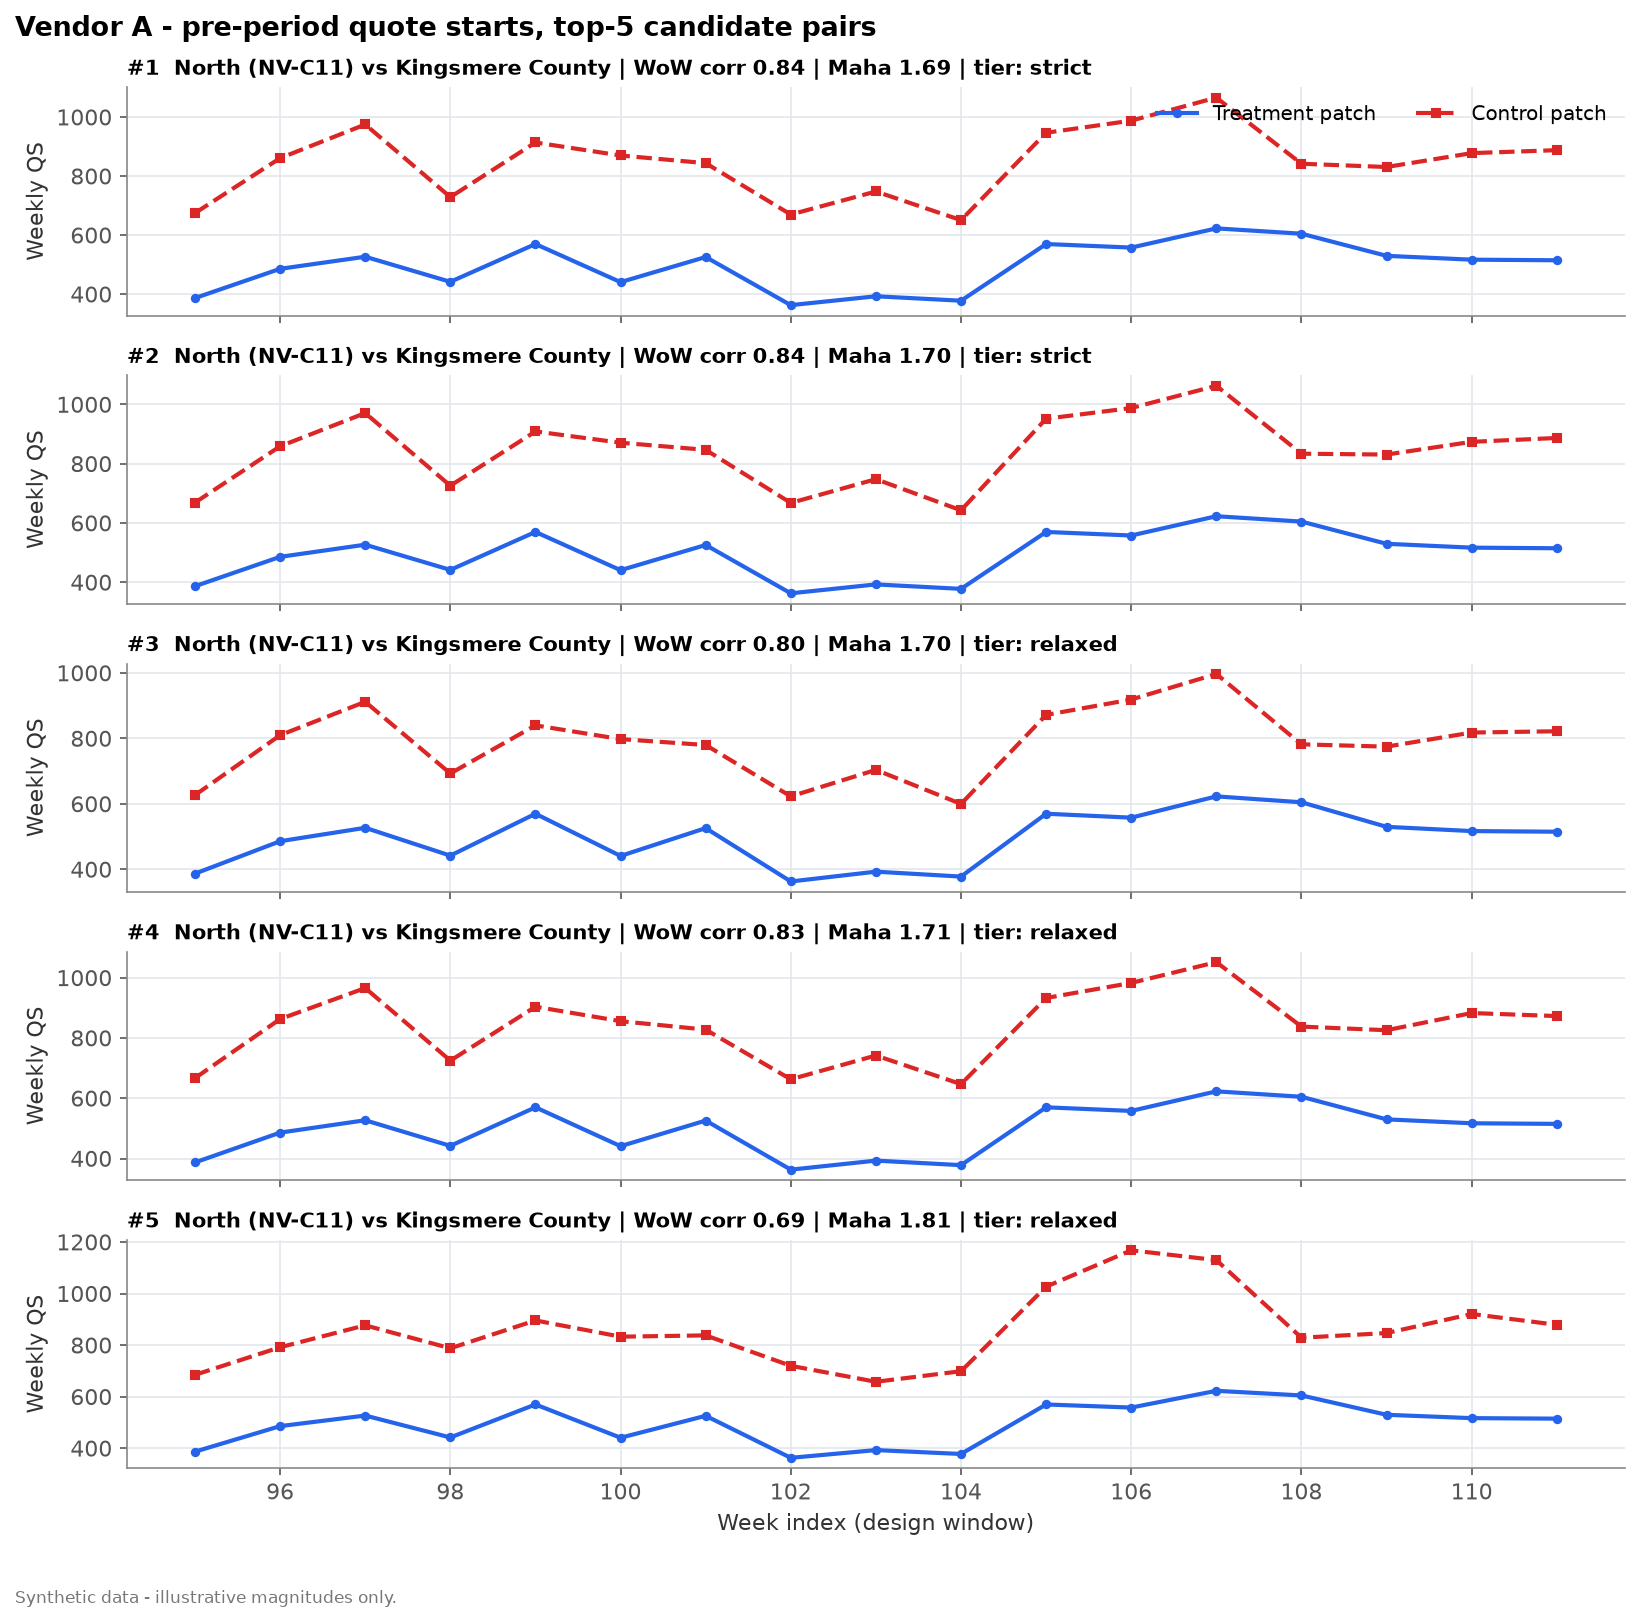

In [11]:
show('06_a_top5_pair_overlays', 1000)

**Balance.** The SMD table compares treatment and twin on every feature, population-weighted. Change-ratio DiD
differences out *level* gaps, so imbalance matters only through differential trends, which the pre-trend gates
and the in-time placebo check directly. It is reported, not tuned away.

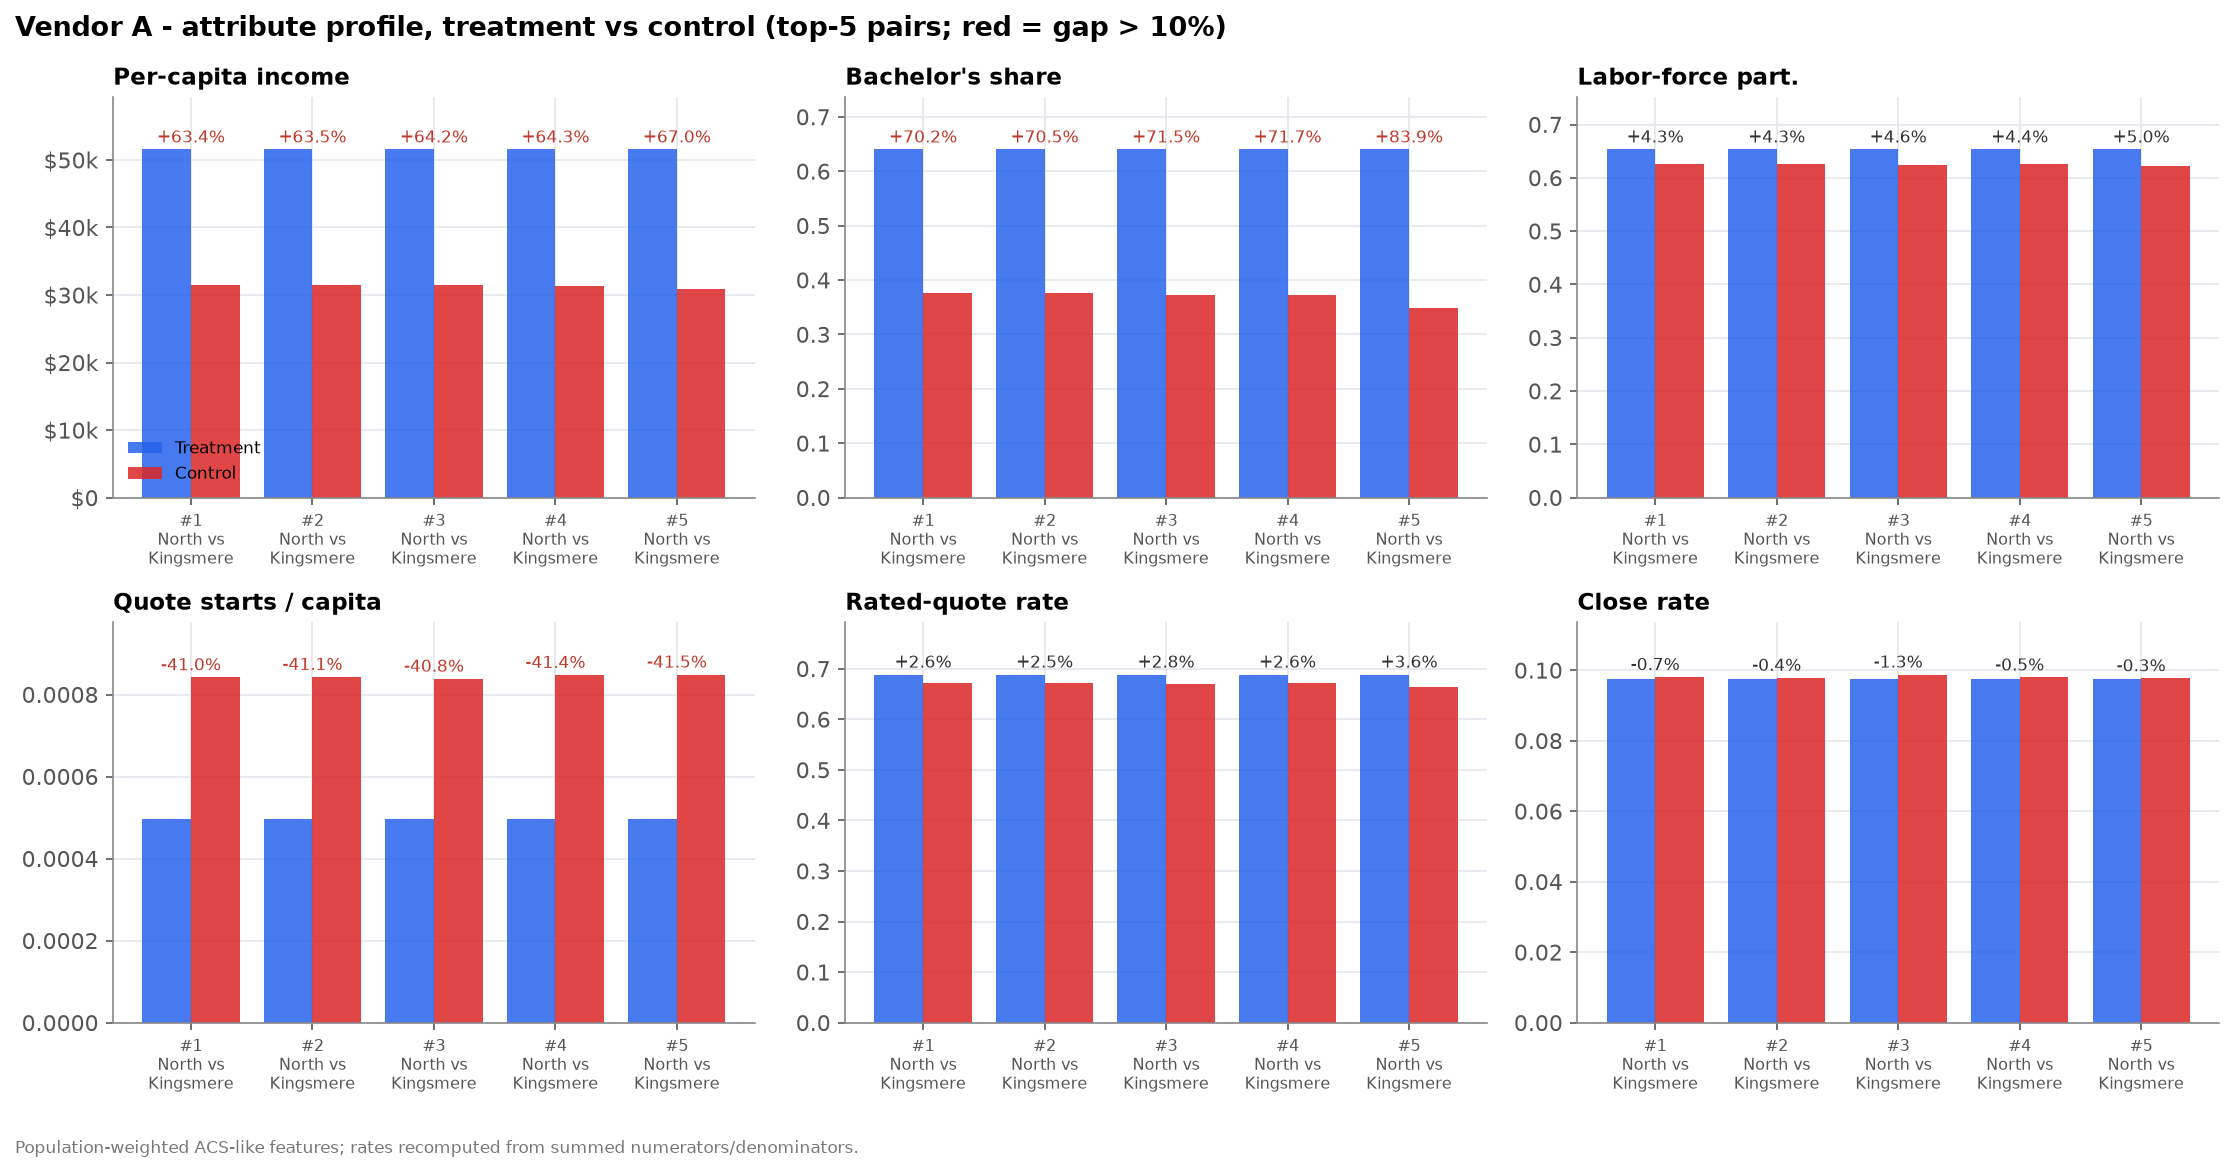

In [12]:
show('07_a_attribute_profile')

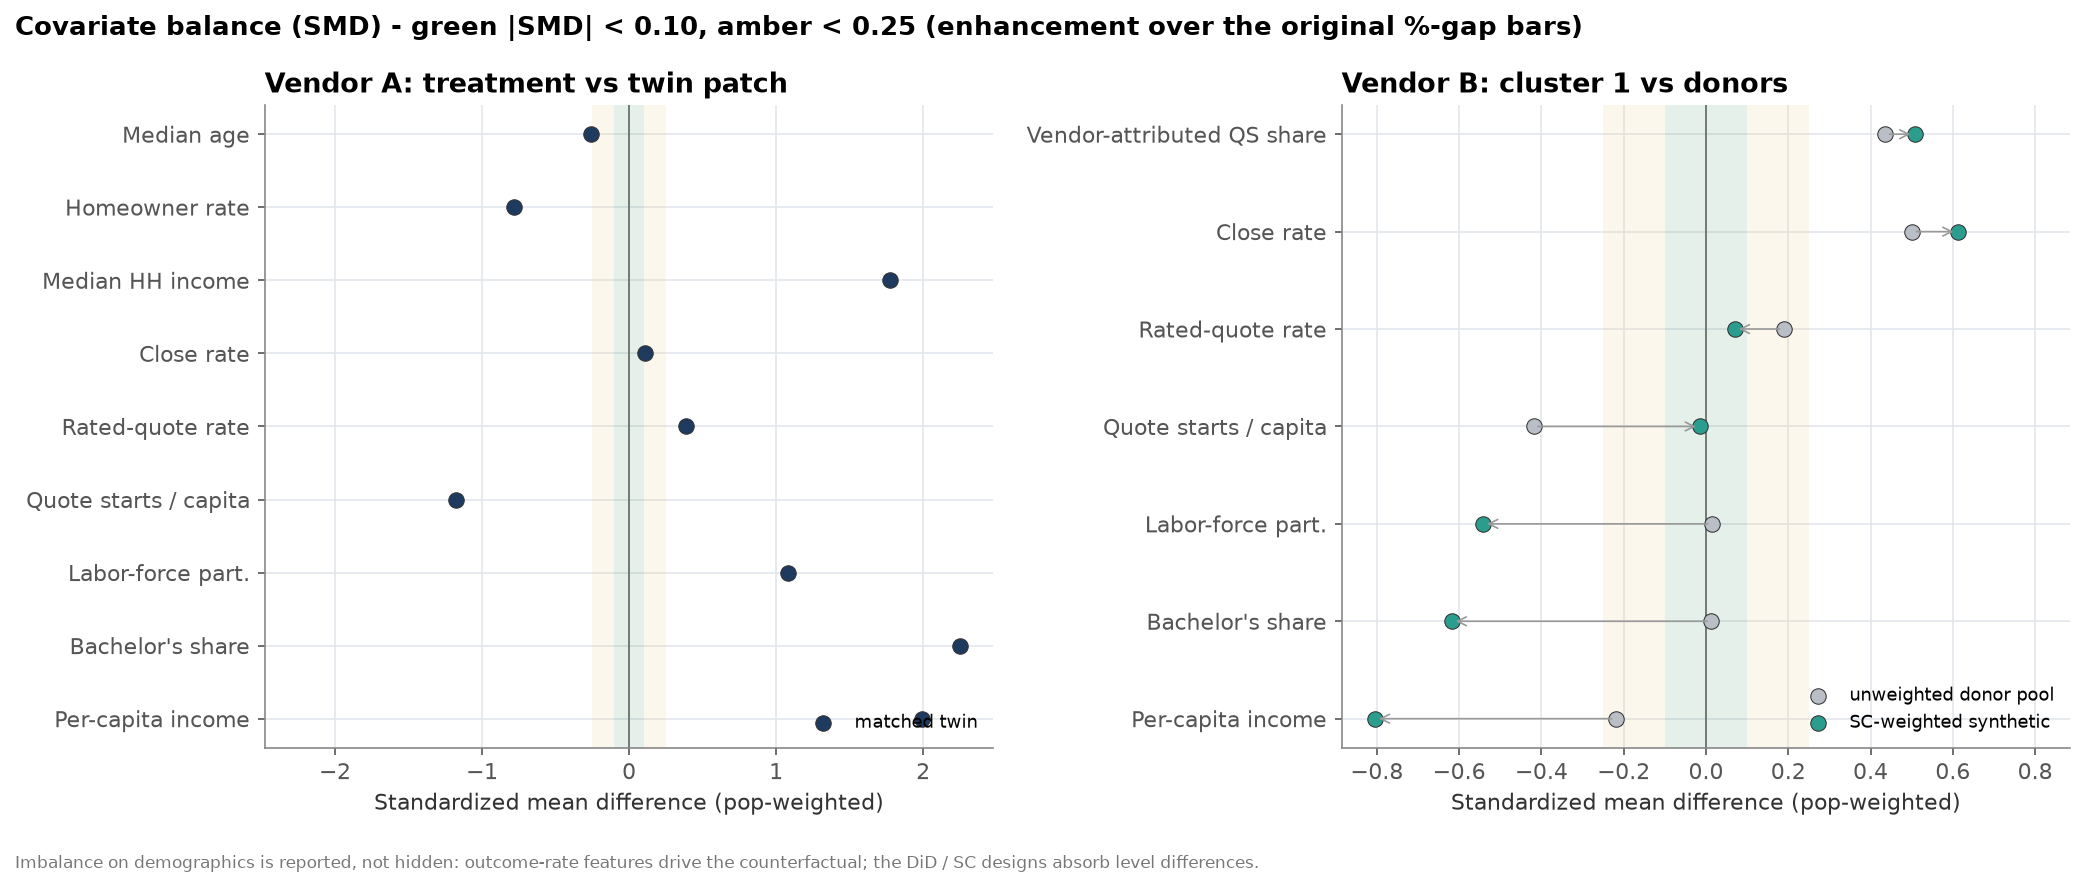

In [13]:
show('11_balance_smd')

In [14]:
A.smd.round(3)

,feature,label,treatment_mean,control_mean,pct_diff,smd,abs_smd,flag
0,per_capita_income,Per-capita income,51561.808,31558.619,0.634,1.990,1.990,imbalanced (>=0.25)
1,pct_bachelors,Bachelor's share,0.640,0.376,0.702,2.253,2.253,imbalanced (>=0.25)
2,lfpr,Labor-force part.,0.653,0.626,0.043,1.080,1.080,imbalanced (>=0.25)
3,qs_per_capita,Quote starts / capita,0.000,0.001,-0.410,-1.180,1.180,imbalanced (>=0.25)
4,rated_rate,Rated-quote rate,0.689,0.674,0.022,0.384,0.384,imbalanced (>=0.25)
5,close_rate,Close rate,0.101,0.098,0.034,0.107,0.107,caution (<0.25)
6,median_hh_income,Median HH income,102108.149,73471.192,0.390,1.772,1.772,imbalanced (>=0.25)
7,homeowner_rate,Homeowner rate,0.443,0.526,-0.158,-0.779,0.779,imbalanced (>=0.25)
8,median_age,Median age,37.800,38.357,-0.015,-0.259,0.259,imbalanced (>=0.25)


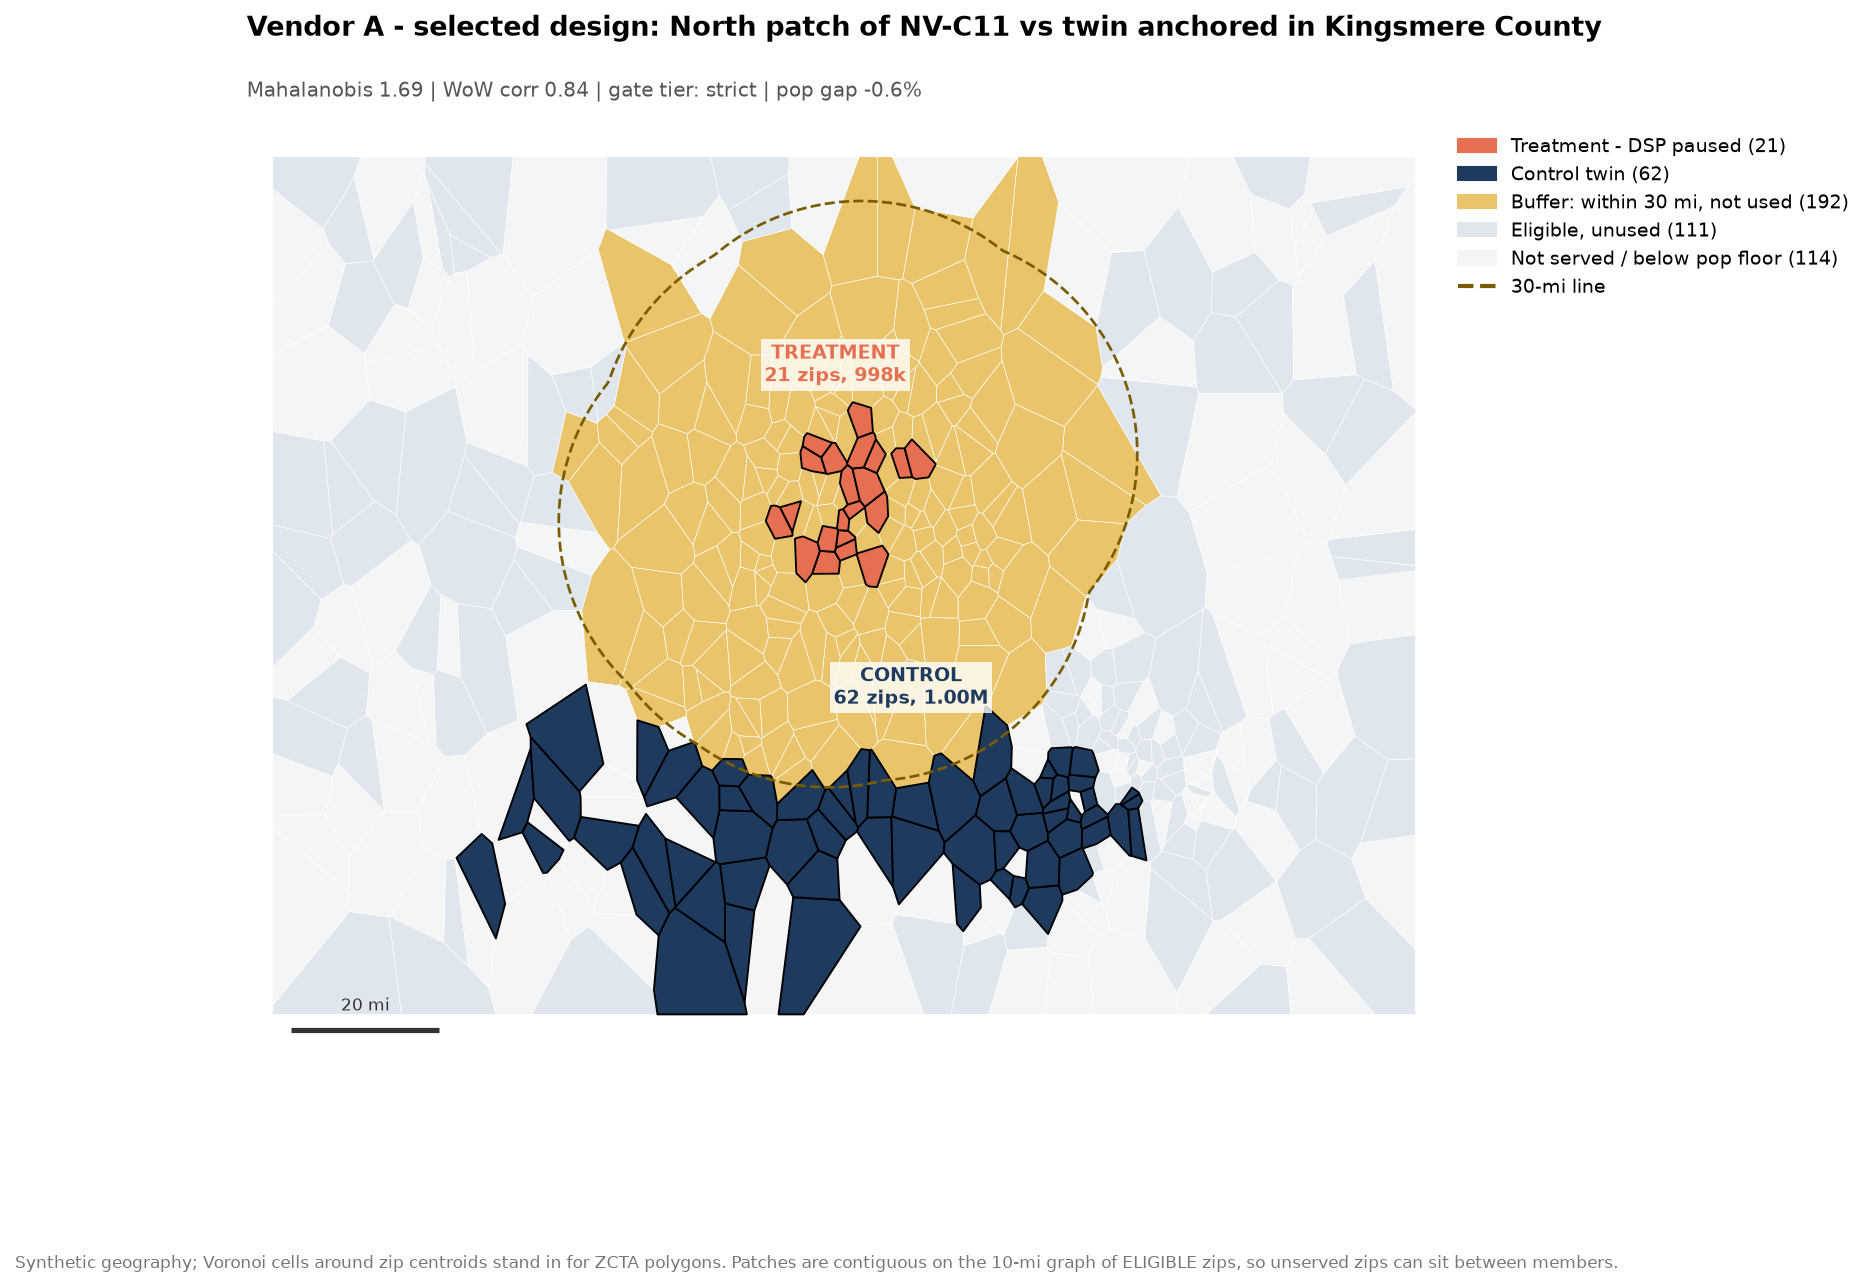

In [15]:
show('10_a_selected_design_map')

## 3. Power drives the design: sizing the holdout on SALES

One convention is used everywhere: one-sided α = 0.10, 80% power. Sigma is the standard deviation of the weekly
relative treatment-control gap, and the SE is inflated for AR(1) autocorrelation.

**Pre-registered rule.** The decision metric is sales (bound policies), not quote starts. So before launch the design
step walks a holdout-size ladder (0.5M → 1.25M population), runs the *whole* matched-pair design at each size, and keeps
the **smallest holdout whose strict-gate pair can detect a 20% sales contribution at 80% power** over the test window.
Only design-window data are used. If no size qualifies, the most powerful strict design is used and flagged
UNDER-POWERED; a relaxed-tier pair is never used silently.

This is the fix for the first version of this test: at 0.5M population and 6 weeks the sales MDE was ~30% and the best
pair only passed the *relaxed* gates. That design read a strong vendor as noise. The window is now 12 weeks
(`config.py`), and the ladder picks the size.

In [16]:
sz = A.sizing.copy()
print(A.sizing_decision['verdict'], '-', A.sizing_decision['rationale'])
sz[[c for c in sz.columns if c != 'status']].round(3)

POWERED - smallest holdout whose strict-gate pair detects 20% on sales at 80% power (MDE 19.7%)


,pop_target,tier,t_pop,n_strict,patch_id,c_county,mde_qs,mde_rated,mde_sales,meets_target
0,500000,relaxed,495382.0,0,NV-C04:East,Lanternfield County,0.128,0.155,0.217,False
1,750000,strict,781577.0,6,NV-C11:North,Kingsmere County,0.099,0.085,0.219,False
2,1000000,strict,998063.0,2,NV-C11:North,Kingsmere County,0.073,0.071,0.197,True
3,1250000,strict,1236800.0,5,NV-C11:North,Kingsmere County,0.067,0.063,0.178,True


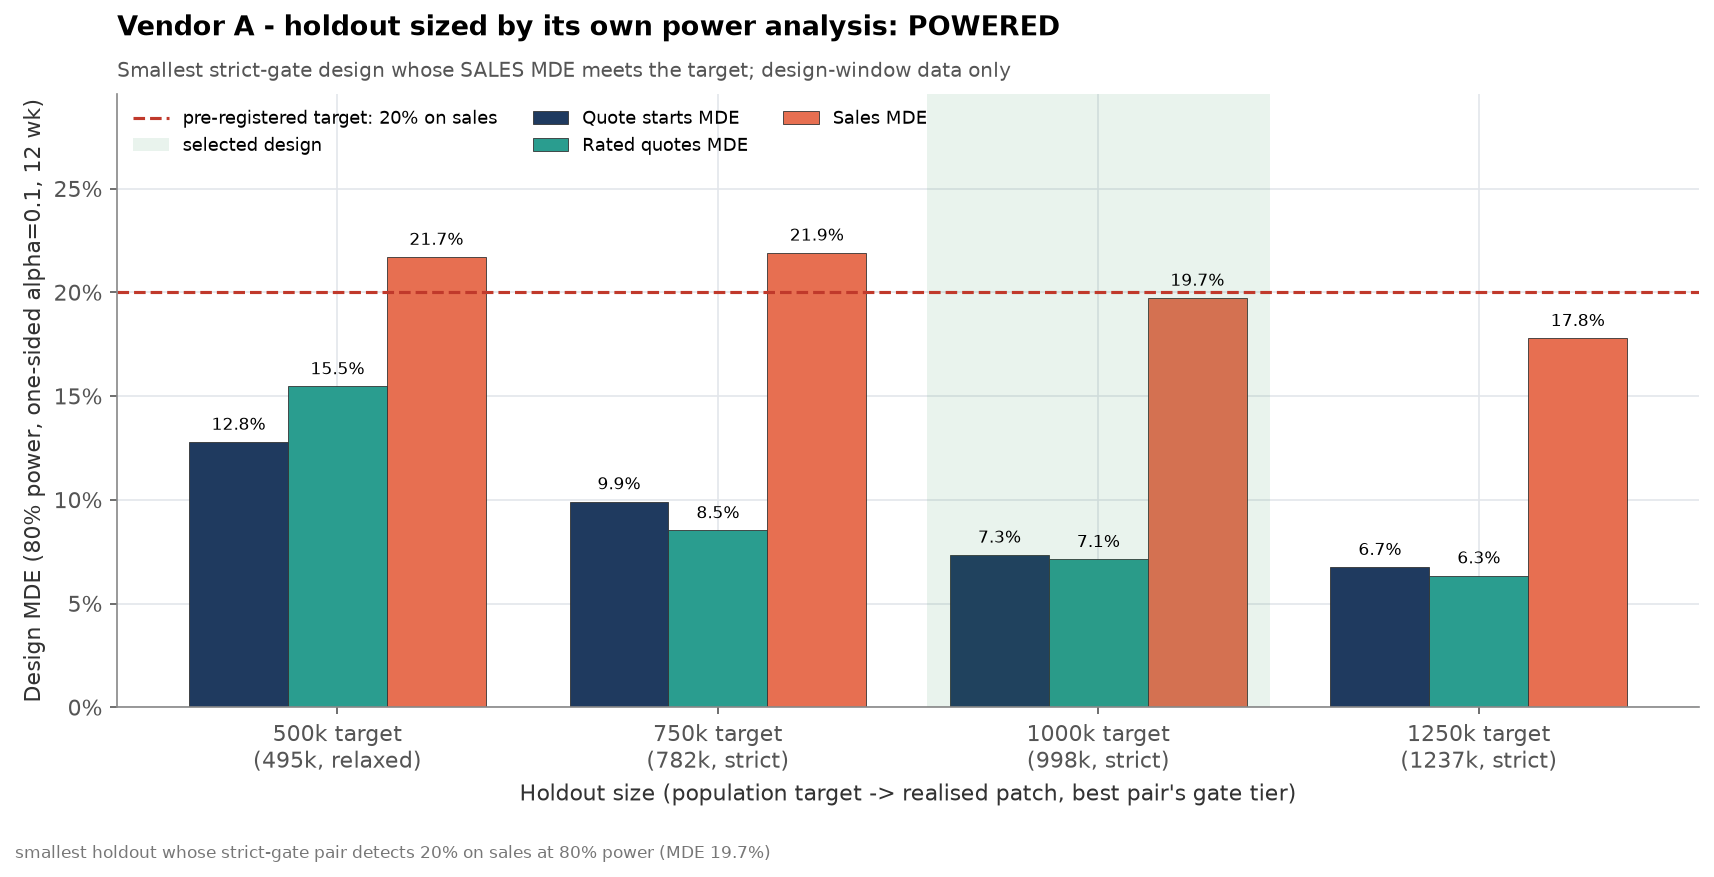

In [17]:
show('08b_a_power_sizing_ladder', 1000)

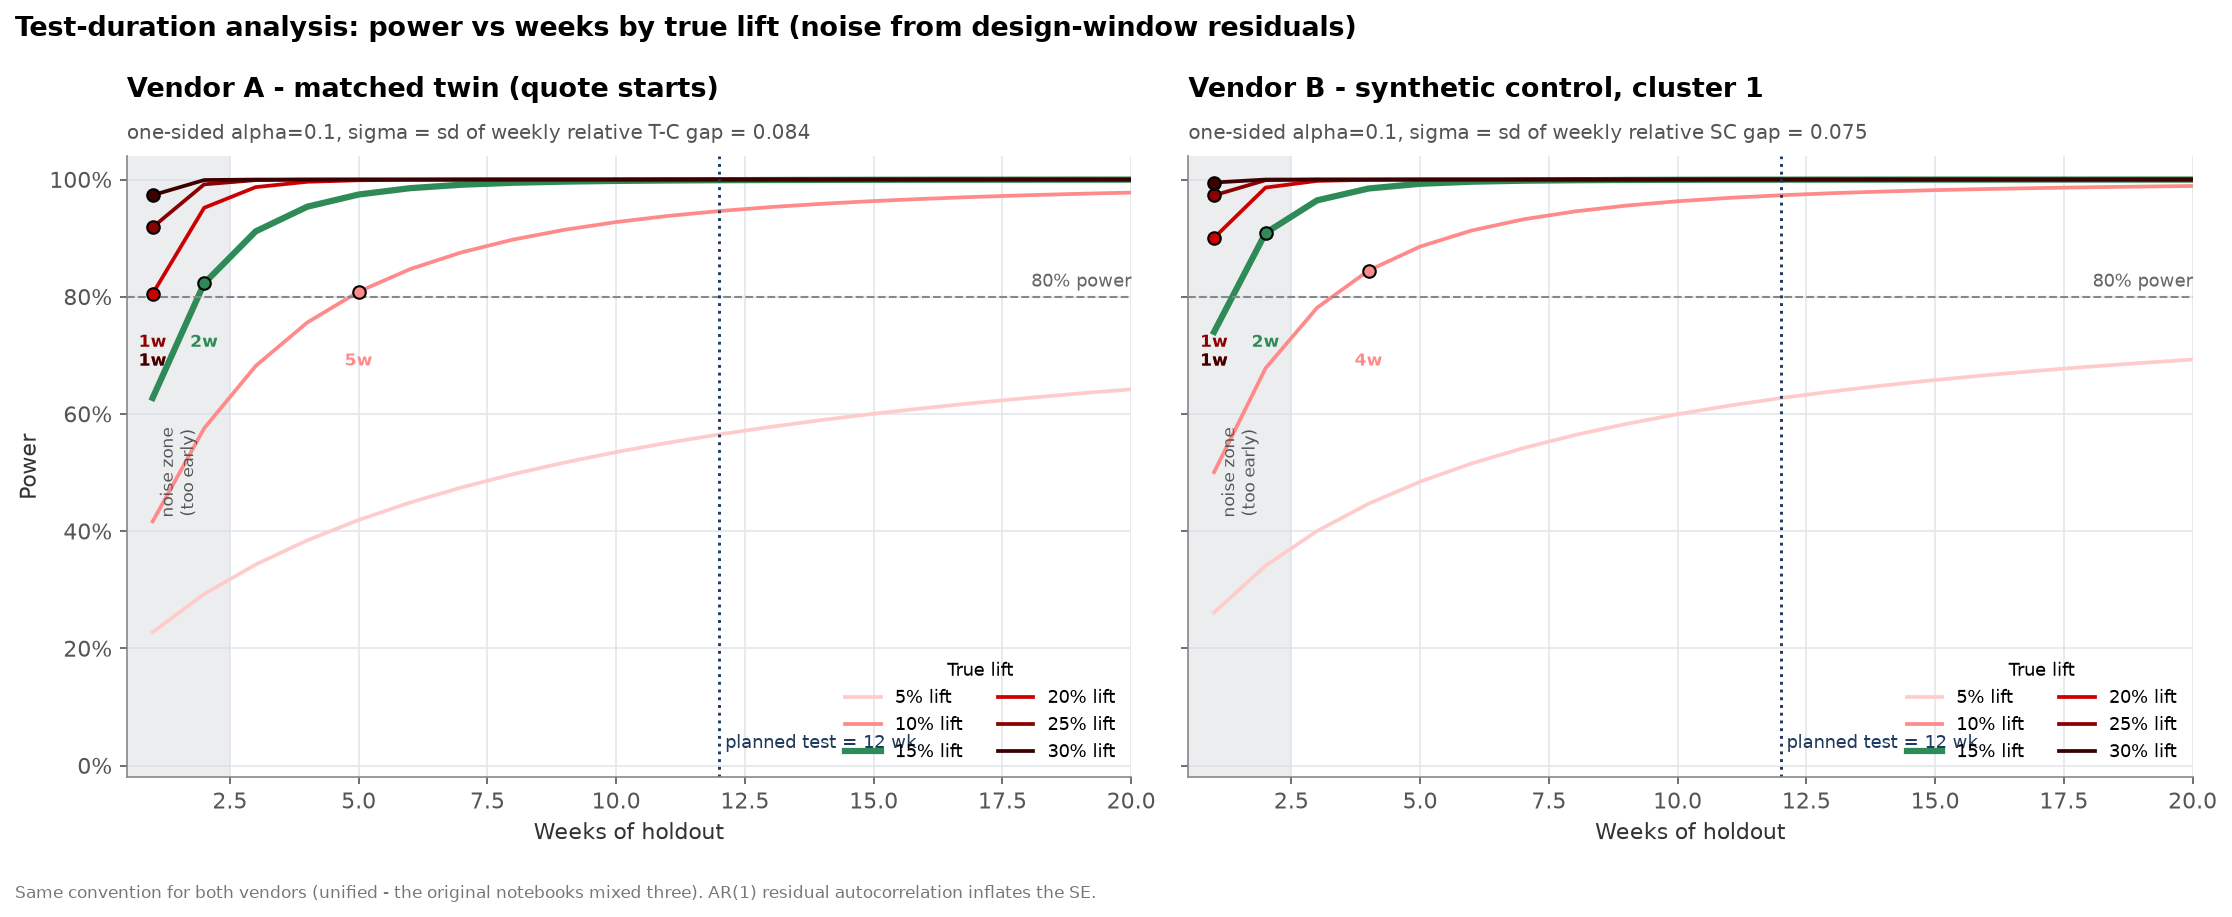

In [18]:
show('08_power_curves', 1000)

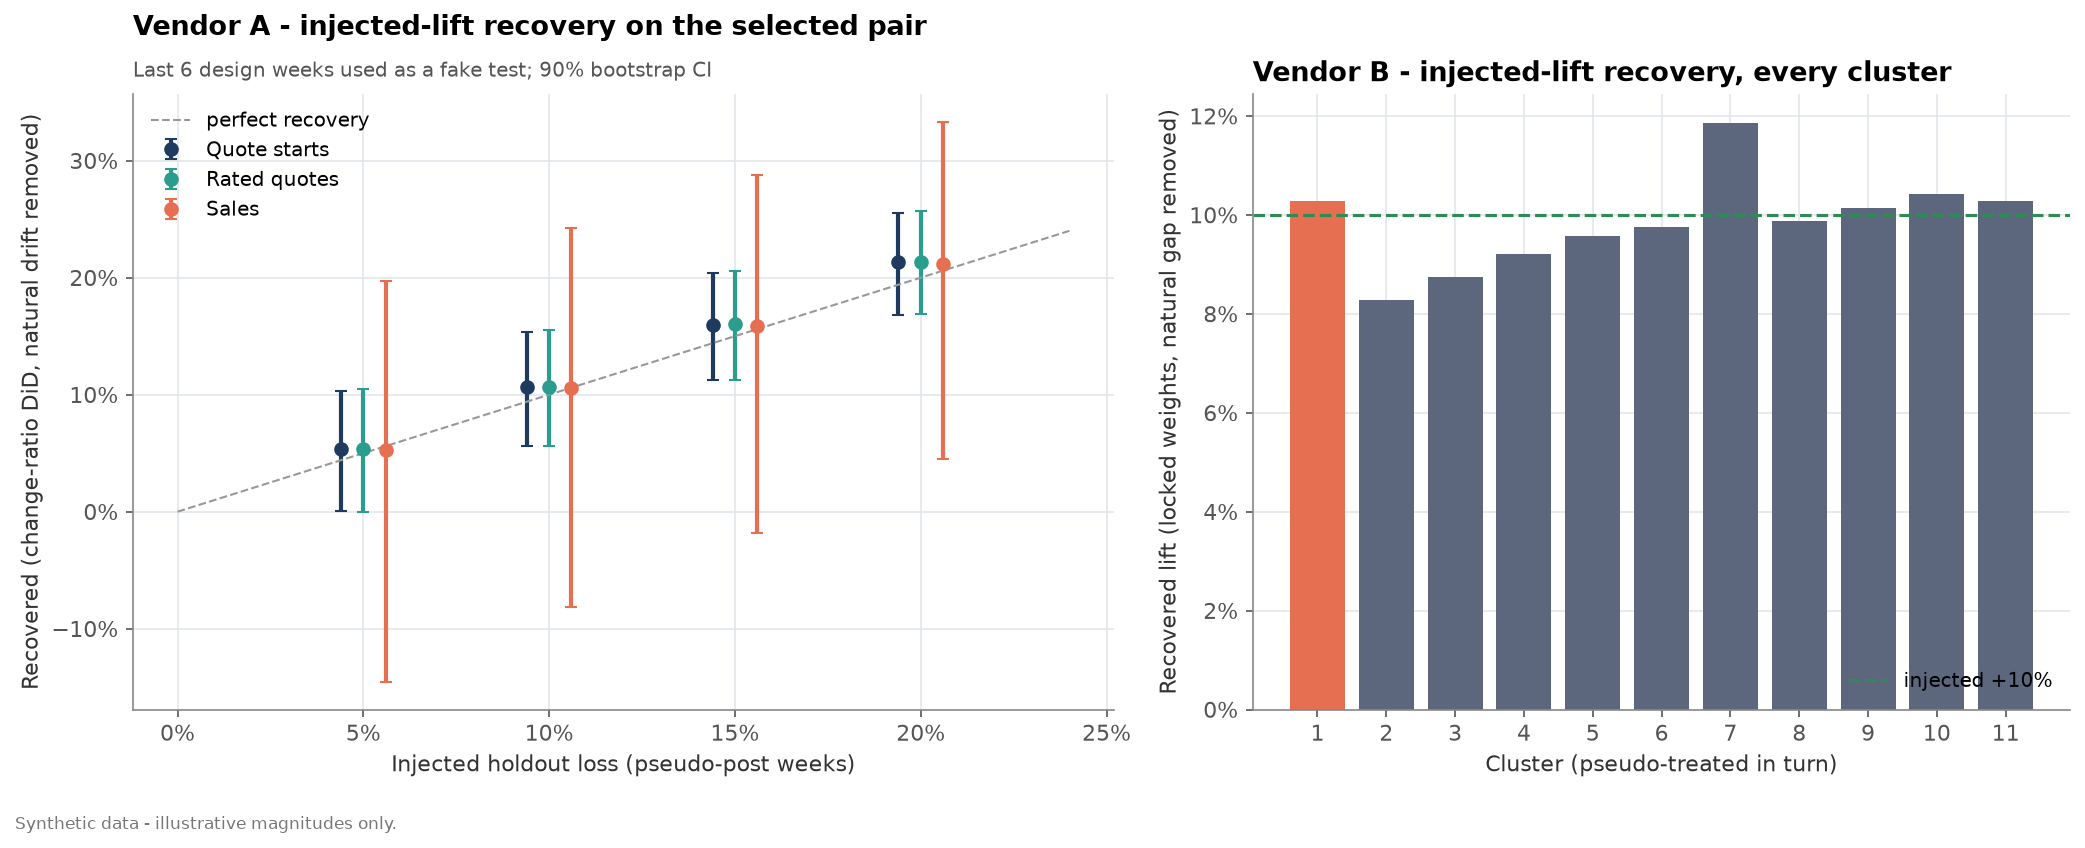

In [19]:
show('09_injected_lift_recovery', 1000)

In [20]:
A.injected.round(3)

,metric,injected,detected_raw,natural_bias,detected,error,ci_low,ci_high
0,qs,0.05,-0.012,-0.065,0.053,0.003,0.000,0.103
1,qs,0.10,0.041,-0.065,0.107,0.007,0.056,0.154
2,qs,0.15,0.095,-0.065,0.160,0.010,0.112,0.204
3,qs,0.20,0.148,-0.065,0.213,0.013,0.168,0.255
4,rated,0.05,-0.014,-0.068,0.053,0.003,0.000,0.105
5,rated,0.10,0.039,-0.068,0.107,0.007,0.056,0.155
6,rated,0.15,0.093,-0.068,0.160,0.010,0.112,0.206
7,rated,0.20,0.146,-0.068,0.214,0.014,0.169,0.257
8,sales,0.05,-0.005,-0.058,0.053,0.003,-0.145,0.197
9,sales,0.10,0.048,-0.058,0.106,0.006,-0.082,0.243


## 4. Vendor B: vendor-switch structural break
Vendor B changed its reporting mid-history. A Welch test on the weekly vendor-attributed QS share, before vs after the
switch (excluding reporting-dip weeks), decides whether pre-switch vendor-share predictors are usable. The original
test returned NaN when a group was empty; this one returns an explicit "cannot test" decision.

In [21]:
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in B.switch.items() if not isinstance(v, (list, dict, pd.DataFrame, pd.Series))}

{'switch_week': 96,
 'n_before': 6,
 'n_after': 14,
 't': -2.9821,
 'p_value': 0.0081,
 'mean_before': 0.3982,
 'mean_after': 0.2801,
 'shift_pct': -0.2966,
 'significant': True,
 'decision': 'level shift detected -> vendor-share predictors use post-switch weeks only; SC dependent = quote starts per capita (unaffected by vendor reporting)'}

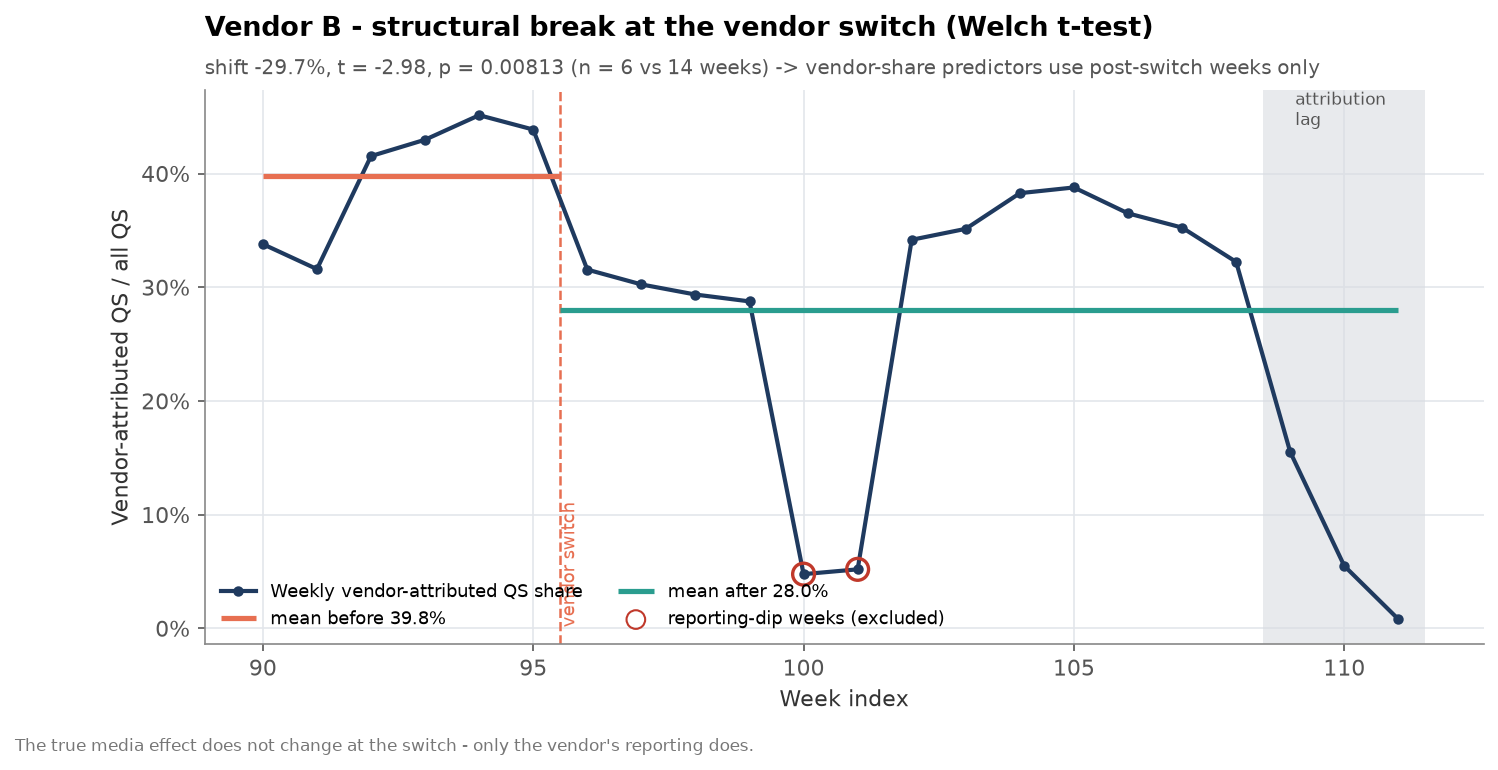

In [22]:
show('12_b_vendor_switch')

## 5. Vendor B: geo-weighted K-means, with K chosen rather than hard-coded
The original computed silhouettes, saw K=3 win, and then hard-coded K=10. Here K is a documented rule: the best
silhouette among K whose mean cluster population fits the business granularity. Both K values are recorded.

{'k_best_silhouette': 3, 'k': 11}


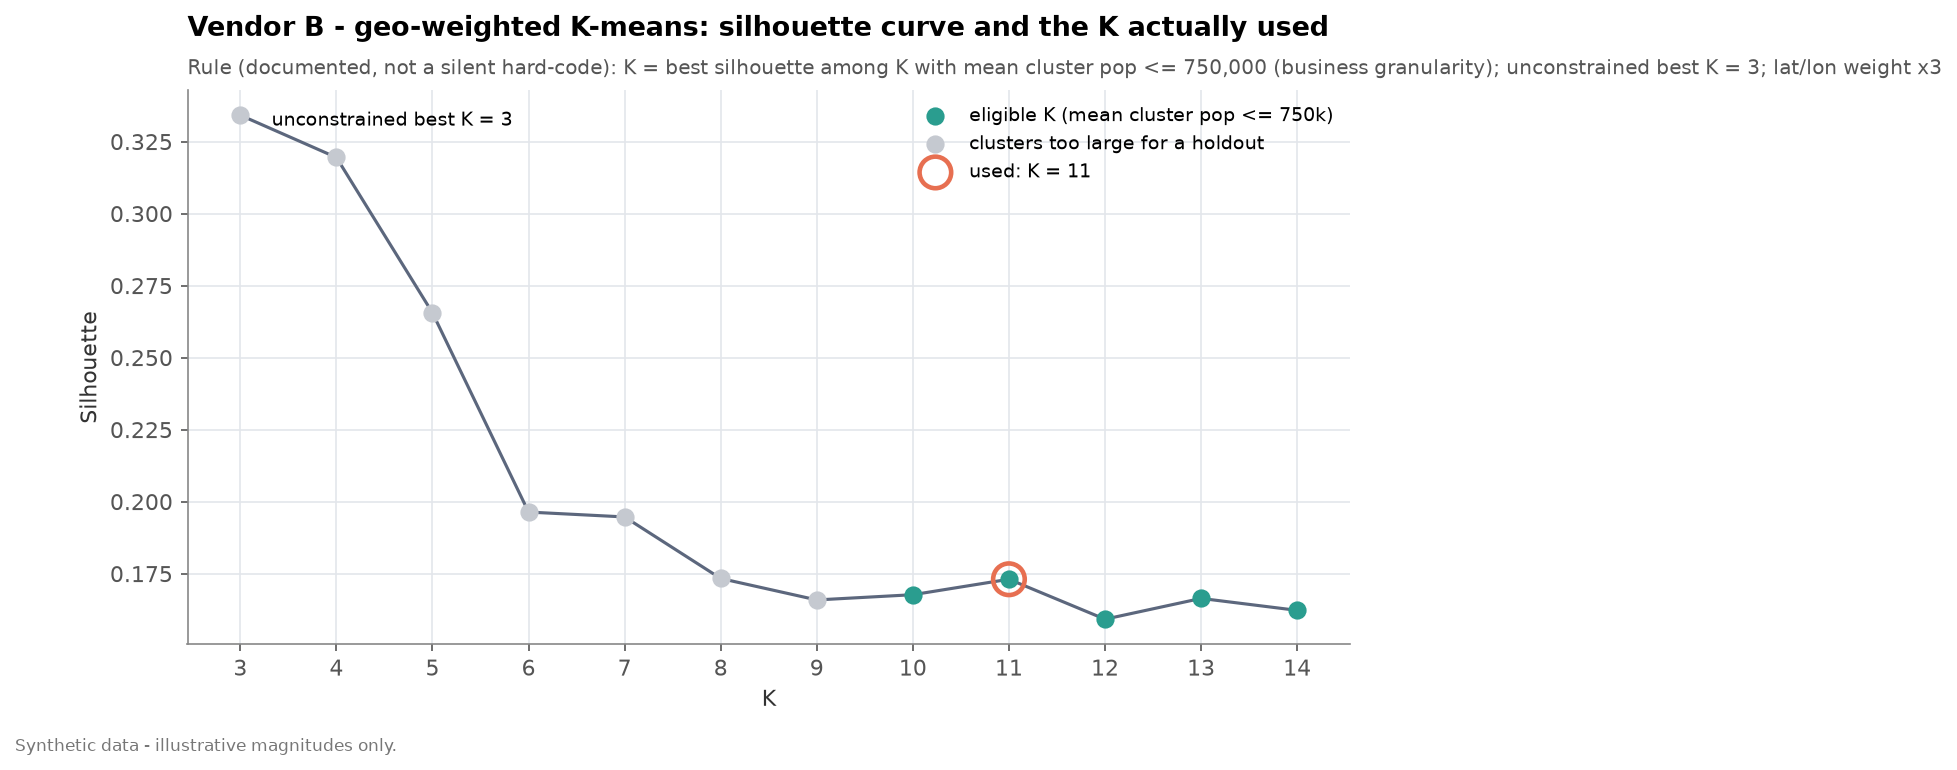

In [23]:
print({k: v for k, v in B.kmeans.items() if k in ("k", "k_best_silhouette", "k_rule", "geo_weight")})
show('13_b_silhouette', 800)

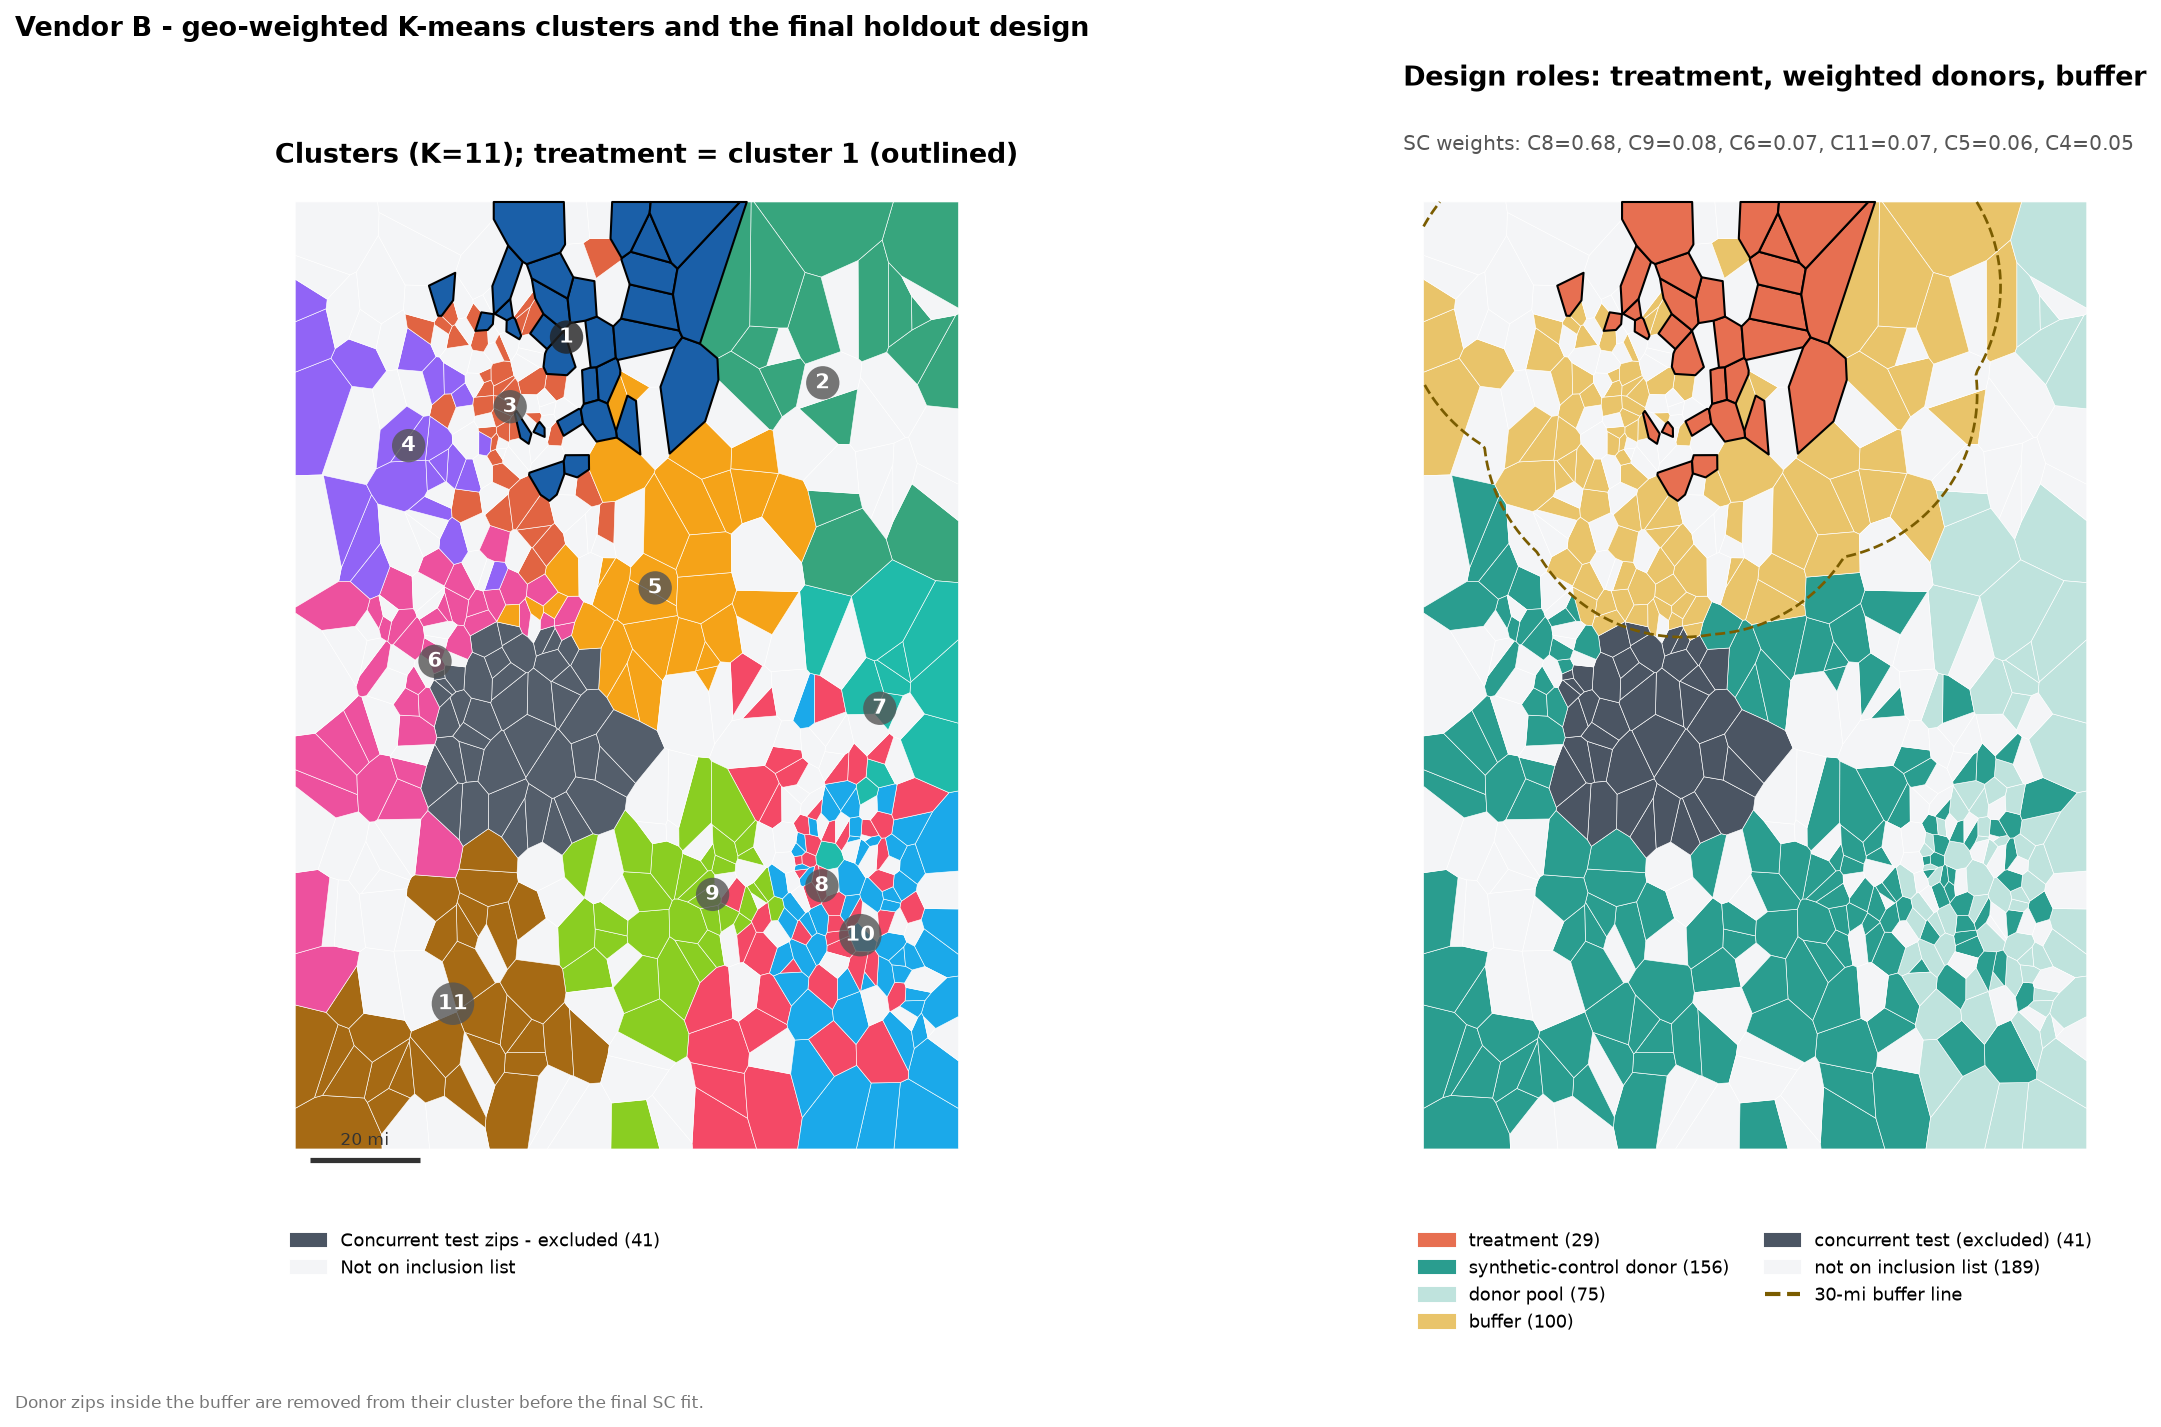

In [24]:
show('14_b_cluster_map')

## 6. Vendor B: synthetic-control tournament
Each cluster takes a turn as the treatment. SC weights are fit and **locked** on the fit window, +10% is injected into
the pseudo-post weeks, and the natural bias is subtracted. The scorecard combines accuracy (|detected − 10%|), fit
(relative RMSE) and speed (weeks to 80% power), subject to explicit feasibility rules. The treatment cluster is
chosen by this score; an analyst override would need a written rationale.

In [25]:
print(B.selection_note)
B.tournament.round(3).head(12)

highest composite score among feasible clusters (score rank 3 of 11)


,cluster,status,n_zips,pop,detected,natural_gap,abs_error,pre_mspe,rel_rmse,noise_sd,...,weeks_to_80,n_donors,top_weights,feasible,infeasible_reason,q_accuracy,q_fit,q_speed,score,score_rank
7,8,ok,53,1276028.0,0.099,-0.013,0.001,0.002,0.080,0.086,...,5,5,"C3:0.61, C6:0.22, C10:0.09, C4:0.07",False,pop outside bounds,0.909,0.636,0.727,0.768,1
9,10,ok,55,1288346.0,0.104,0.043,0.004,0.001,0.028,0.029,...,1,6,"C5:0.41, C4:0.23, C3:0.12, C2:0.12",False,pop outside bounds; largest-volume cluster (bu...,0.364,0.909,0.909,0.691,2
0,1,ok,29,456009.0,0.103,0.028,0.003,0.001,0.043,0.048,...,11,6,"C3:0.58, C5:0.14, C2:0.12, C4:0.07",True,,0.636,0.818,0.364,0.632,3
3,4,ok,23,289292.0,0.092,-0.079,0.008,0.002,0.068,0.073,...,4,7,"C3:0.46, C10:0.21, C9:0.16, C8:0.09",False,pop outside bounds,0.273,0.727,0.818,0.568,4
10,11,ok,30,282035.0,0.103,0.028,0.003,0.005,0.087,0.088,...,6,4,"C6:0.48, C5:0.34, C7:0.15, C1:0.03",False,pop outside bounds,0.545,0.545,0.591,0.557,5
8,9,ok,33,667365.0,0.101,0.013,0.001,0.016,0.113,0.117,...,14,3,"C5:0.60, C7:0.38, C2:0.02",True,,0.818,0.273,0.273,0.491,6
5,6,ok,39,774732.0,0.098,-0.023,0.002,0.003,0.090,0.092,...,16,4,"C8:0.38, C3:0.31, C11:0.17, C2:0.14",True,,0.727,0.364,0.182,0.464,7
4,5,ok,30,539377.0,0.096,-0.043,0.004,0.009,0.090,0.093,...,7,4,"C9:0.39, C10:0.31, C7:0.21, C11:0.09",True,,0.455,0.455,0.455,0.455,8
2,3,ok,39,1031686.0,0.087,-0.125,0.013,0.009,0.209,0.092,...,6,1,C8:1.00,False,pop outside bounds,0.182,0.000,0.591,0.220,9
1,2,ok,17,176171.0,0.083,-0.172,0.017,0.011,0.137,0.144,...,65,4,"C6:0.37, C1:0.33, C9:0.21, C7:0.09",False,pop outside bounds; weeks-to-power > 20,0.091,0.182,0.091,0.123,10


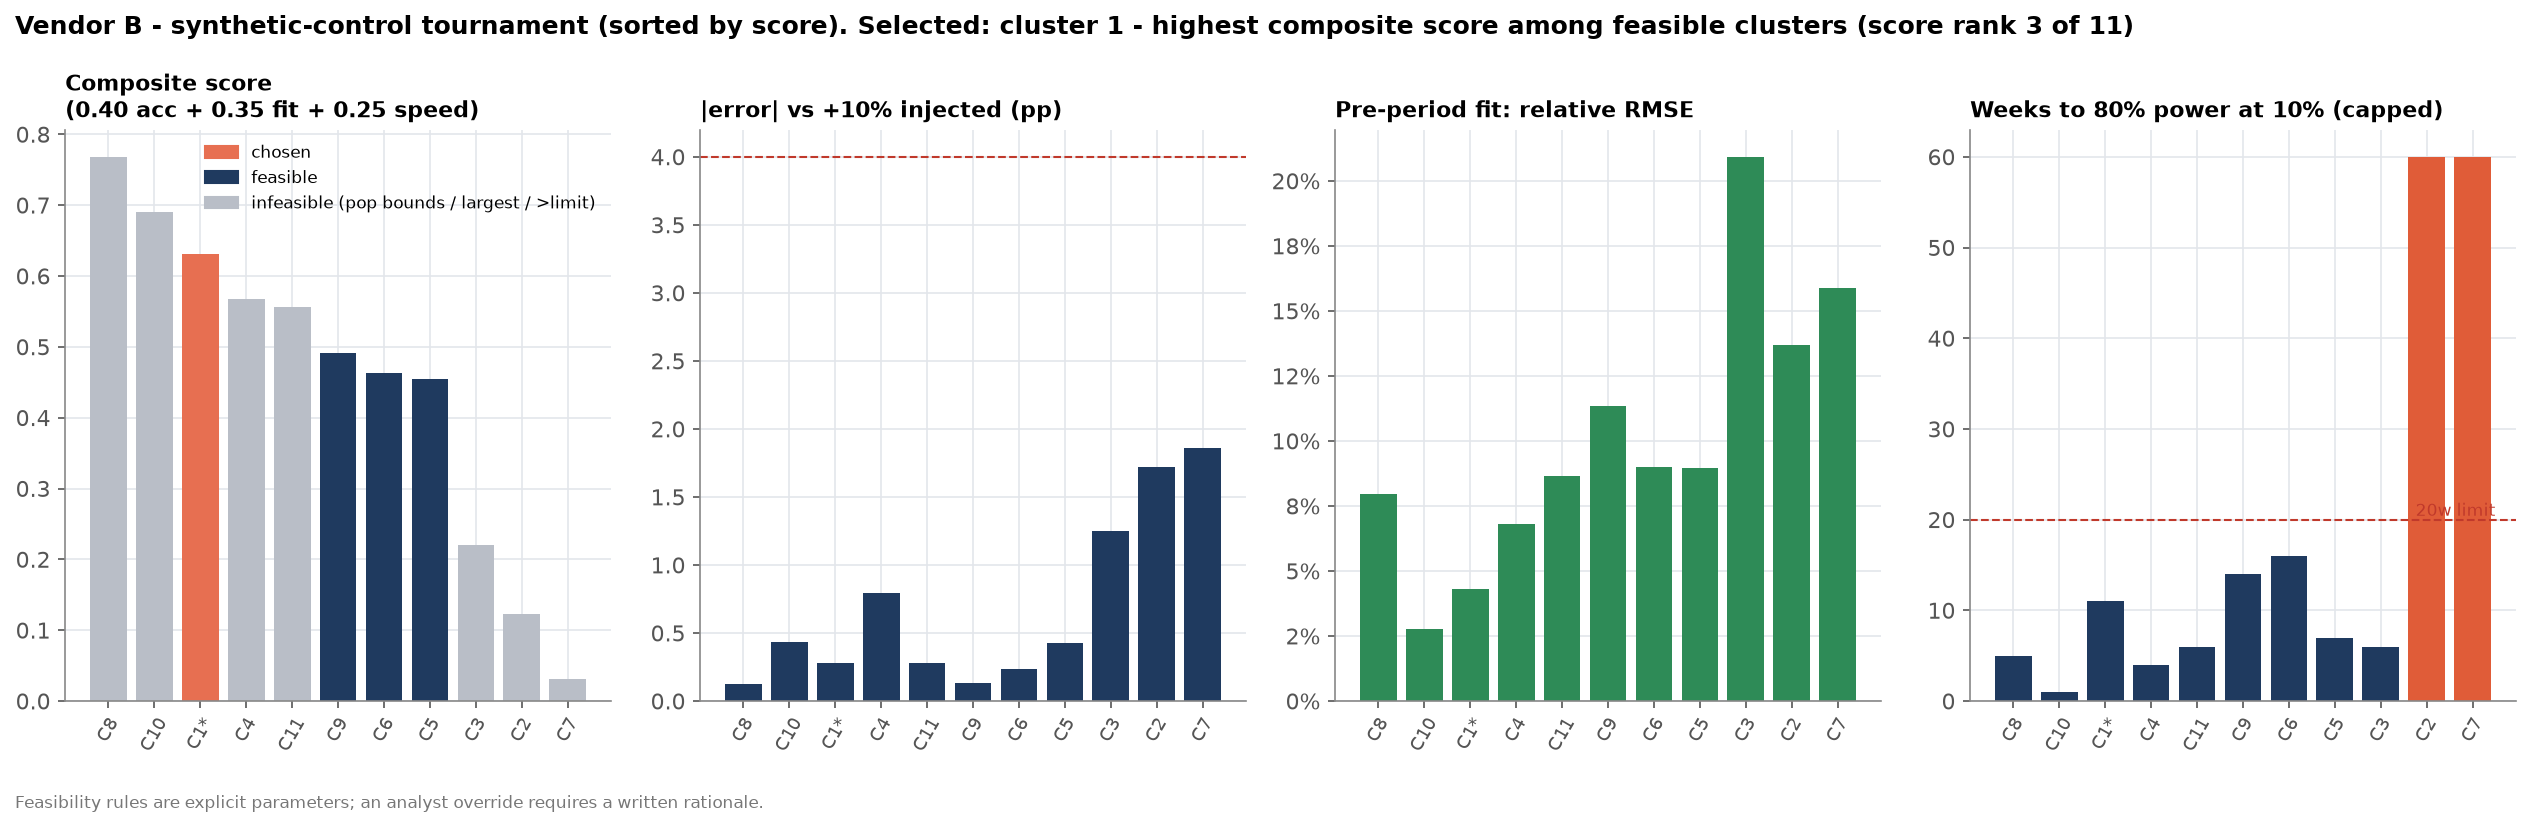

In [26]:
show('15_b_tournament_scorecard', 1000)

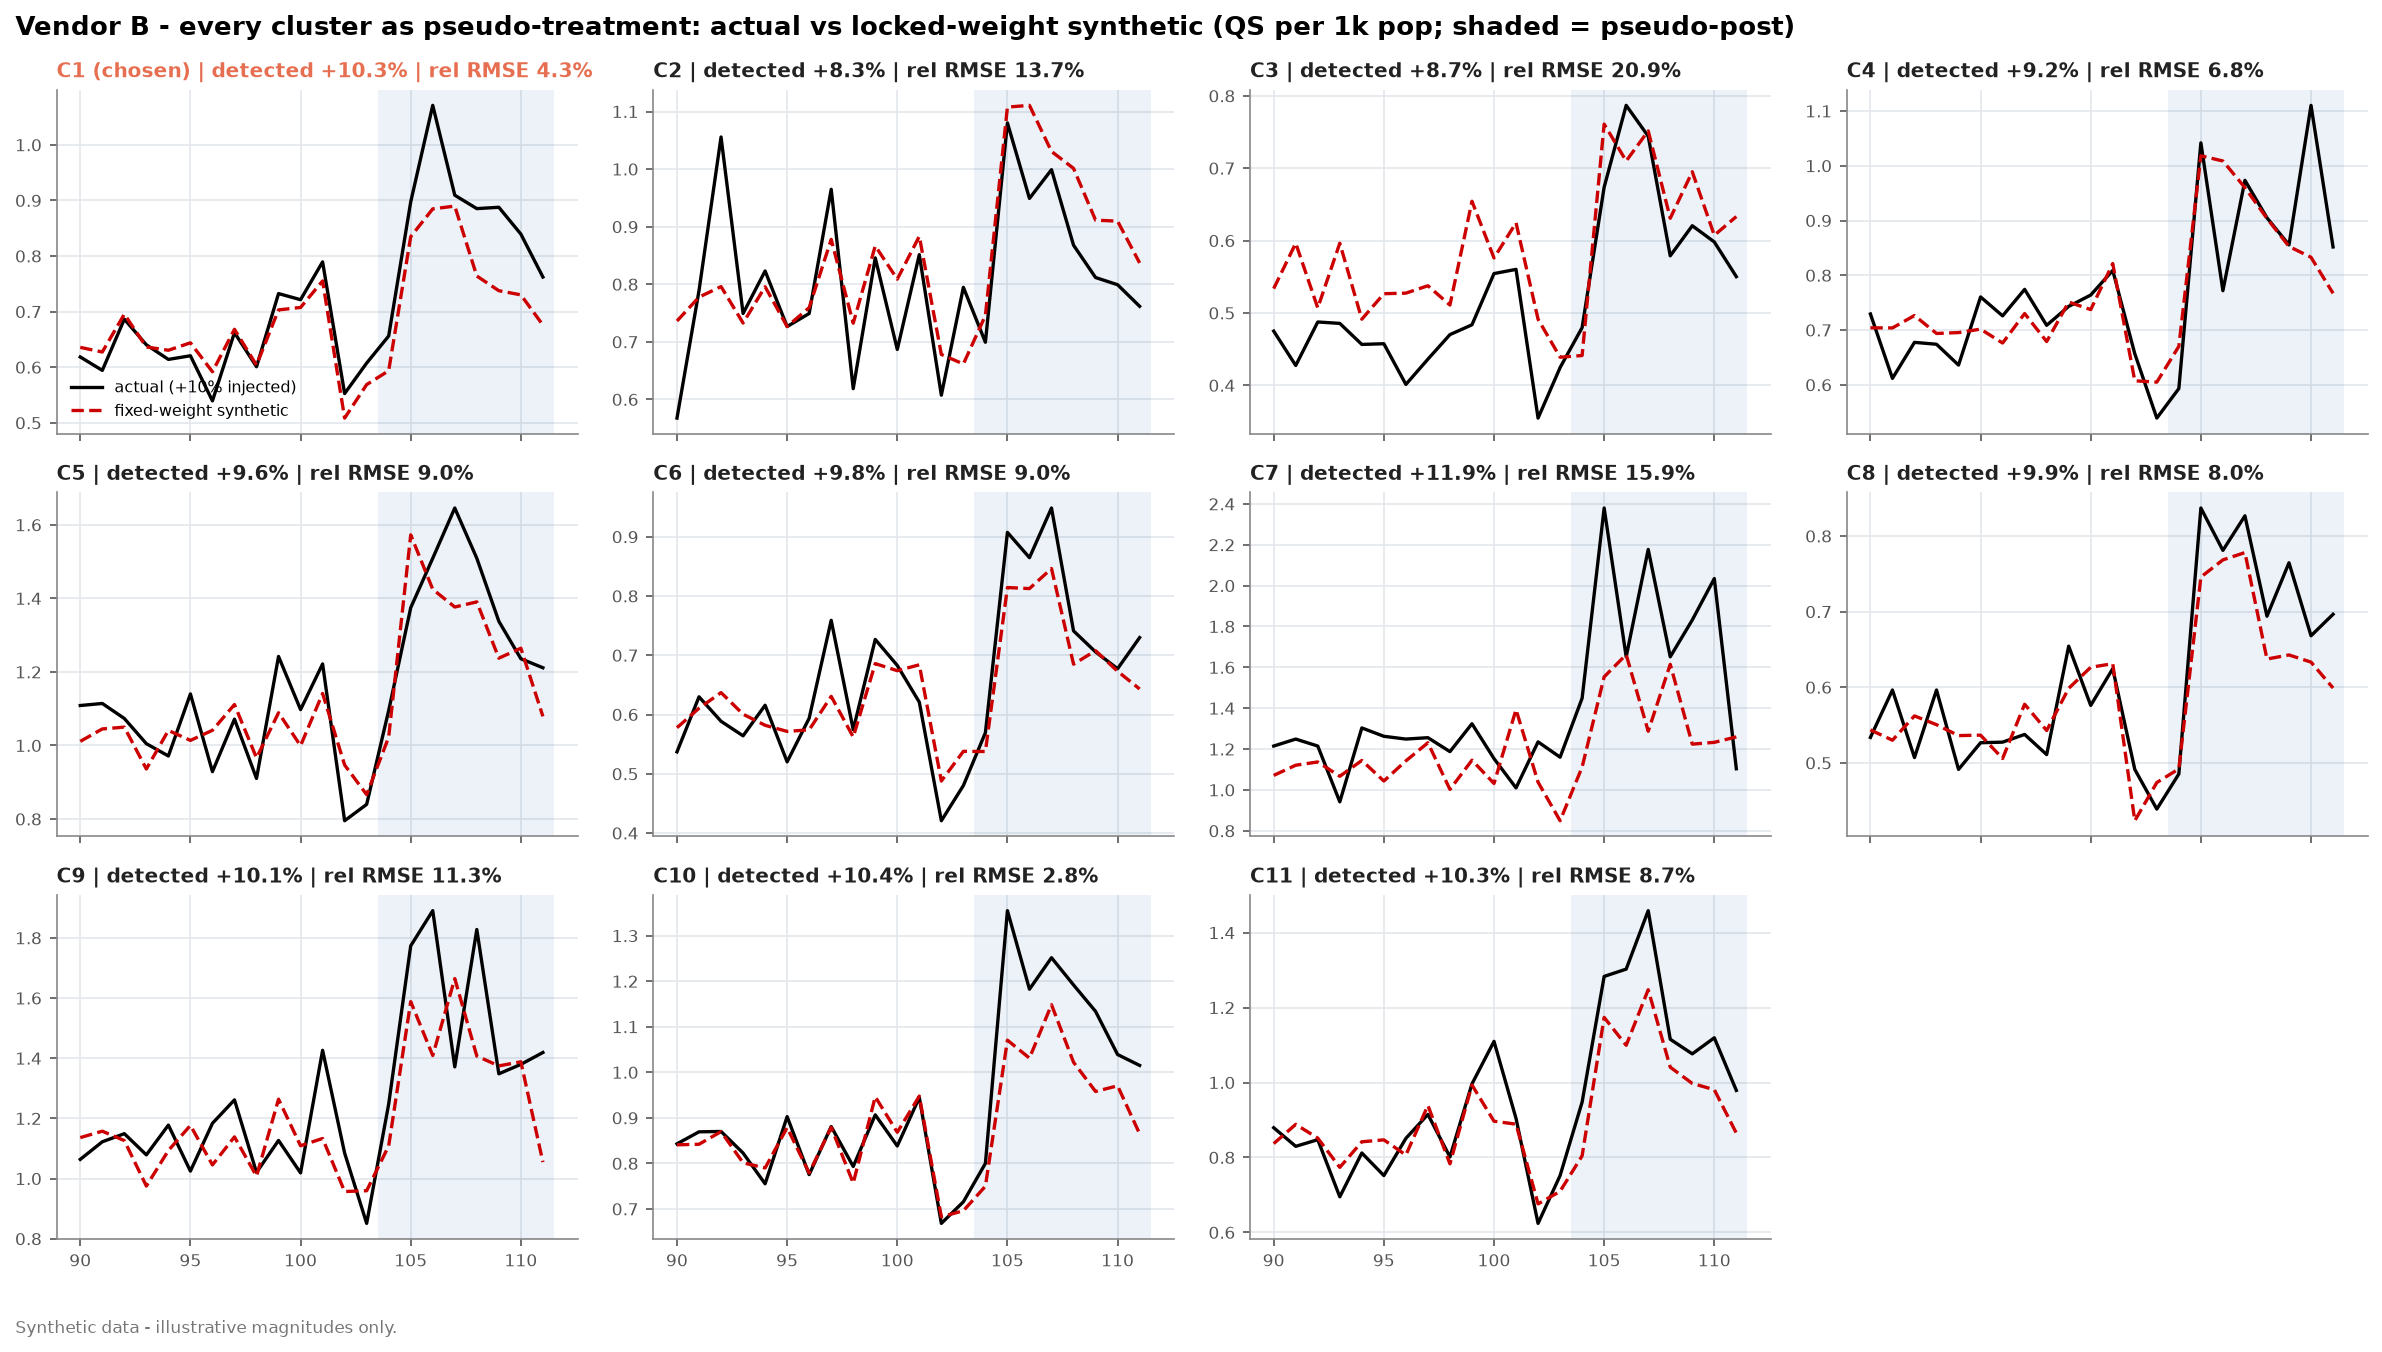

In [27]:
show('16_b_tournament_fits', 1000)

### Final synthetic control, placebos, ridge augmentation
Donor clusters are rebuilt without the buffer zips. Inference uses in-space placebos (one per cluster, so p ≥ 1/K),
in-time placebos, and ~100 random contiguous-geography placebos. The original was stuck with a 9-donor floor
(p ≥ 0.11). A ridge-augmented SC (AugSynth-style) corrects any remaining pre-period imbalance.

weights: {'C4': 0.047, 'C5': 0.056, 'C6': 0.07, 'C8': 0.679, 'C9': 0.081, 'C11': 0.067}
injected check: {'injected': 0.1, 'detected': 0.1046, 'detected_raw': 0.1505, 'natural_gap': 0.0459, 'error': 0.0046, 'abs_error': 0.0046, 'pre_rmspe': 0.0415, 'rel_rmse': 0.0646, 'max_weight': 0.6719, 'effective_n': 2.0837}
aug: {'lambda': 100.0, 'pre_imbalance_rmse': 0.0489}


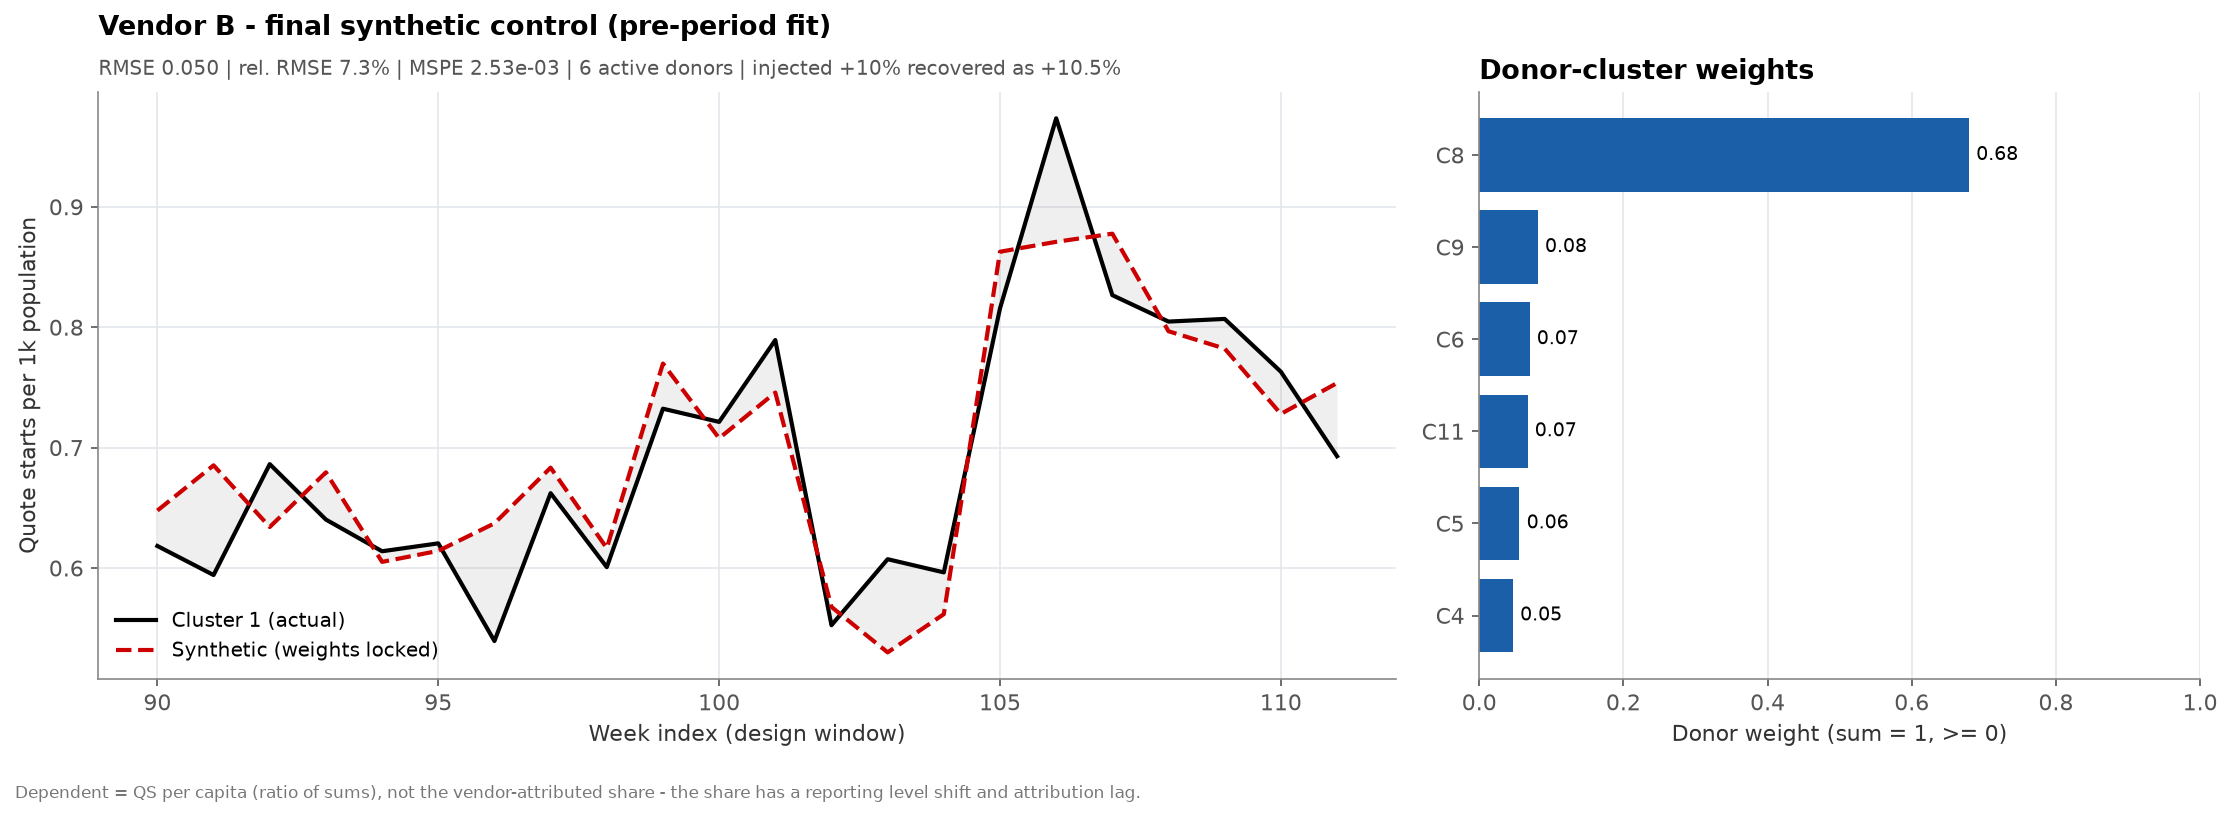

In [28]:
print("weights:", B.weights.round(3).to_dict())
print("injected check:", {k: round(v, 4) for k, v in B.injected_final.items() if isinstance(v, float)})
print("aug:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in B.aug.items() if not hasattr(v, '__len__') or isinstance(v, str)})
show('17_b_final_synthetic_control')

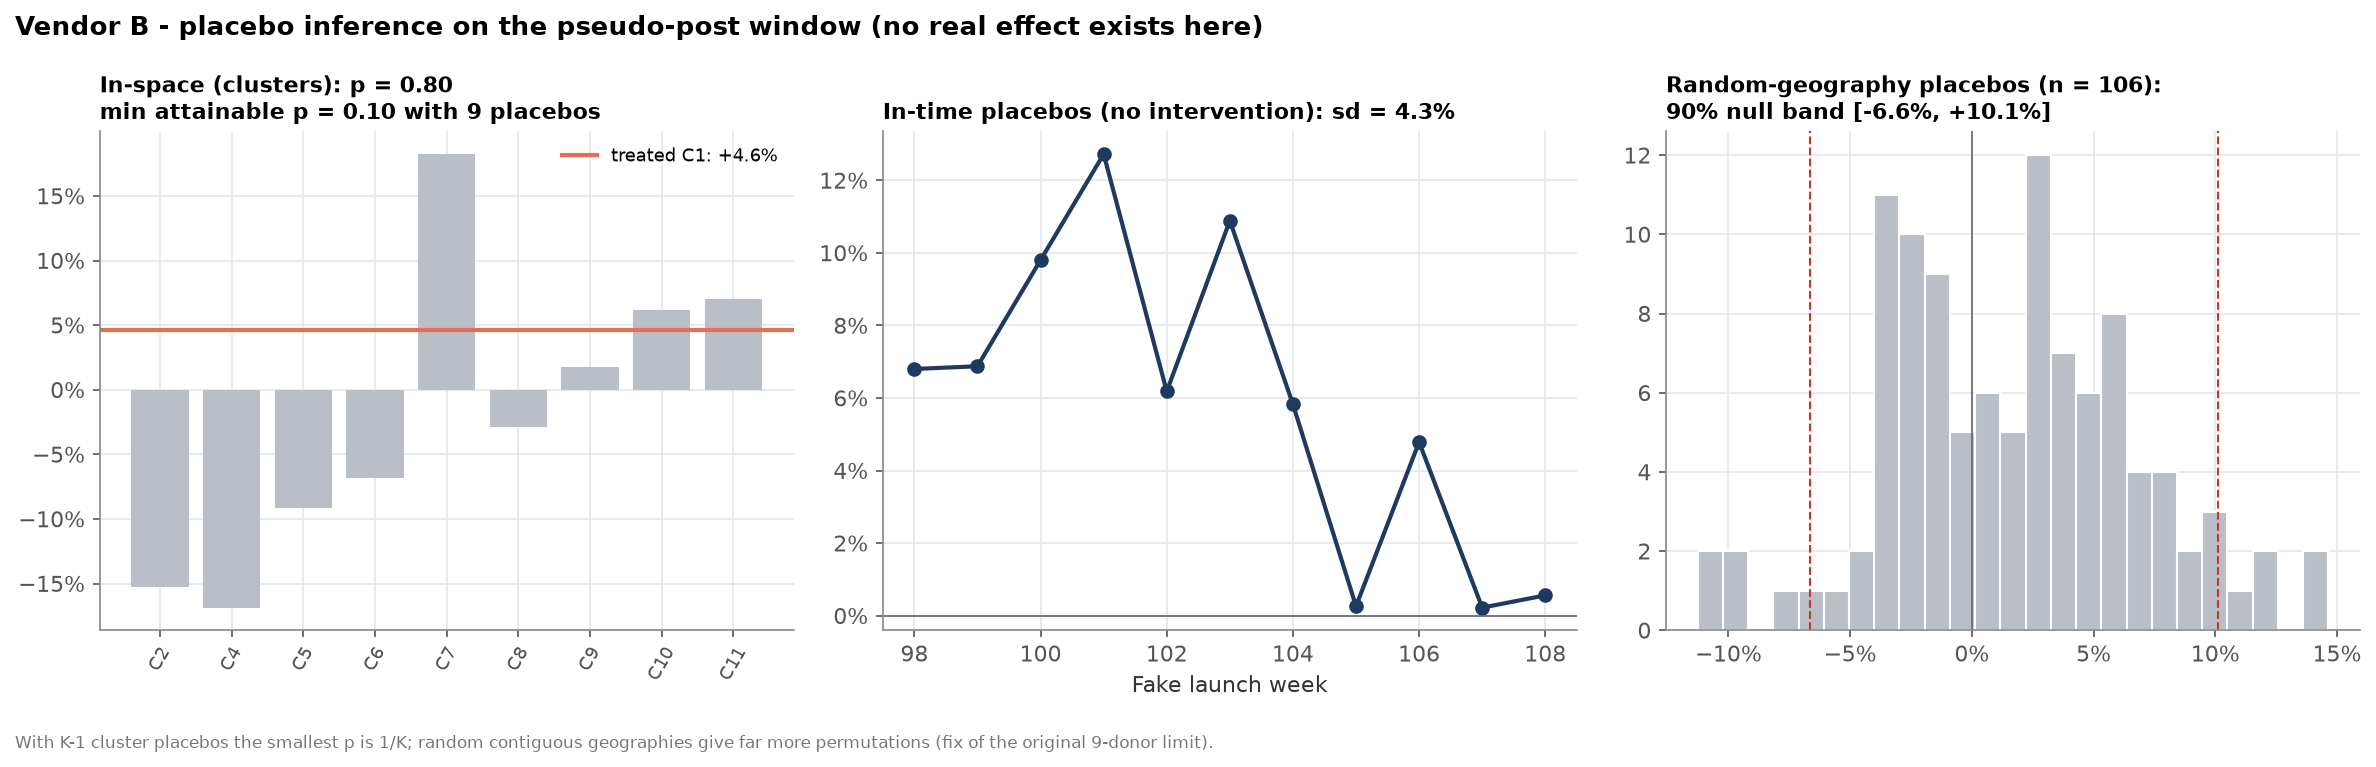

In [29]:
show('18_b_placebo_inference', 1000)

## 7. Launch: realize both holdouts
`simulate.run_scenario` pauses each vendor (to the leakage level of BAU spend) **in exactly the zips the designs
selected**. The true effect follows from the world's adstock + Hill response, and the analyst sees only the observed
funnel. All estimates are *contributions*: positive means volume lost when the ads were paused.

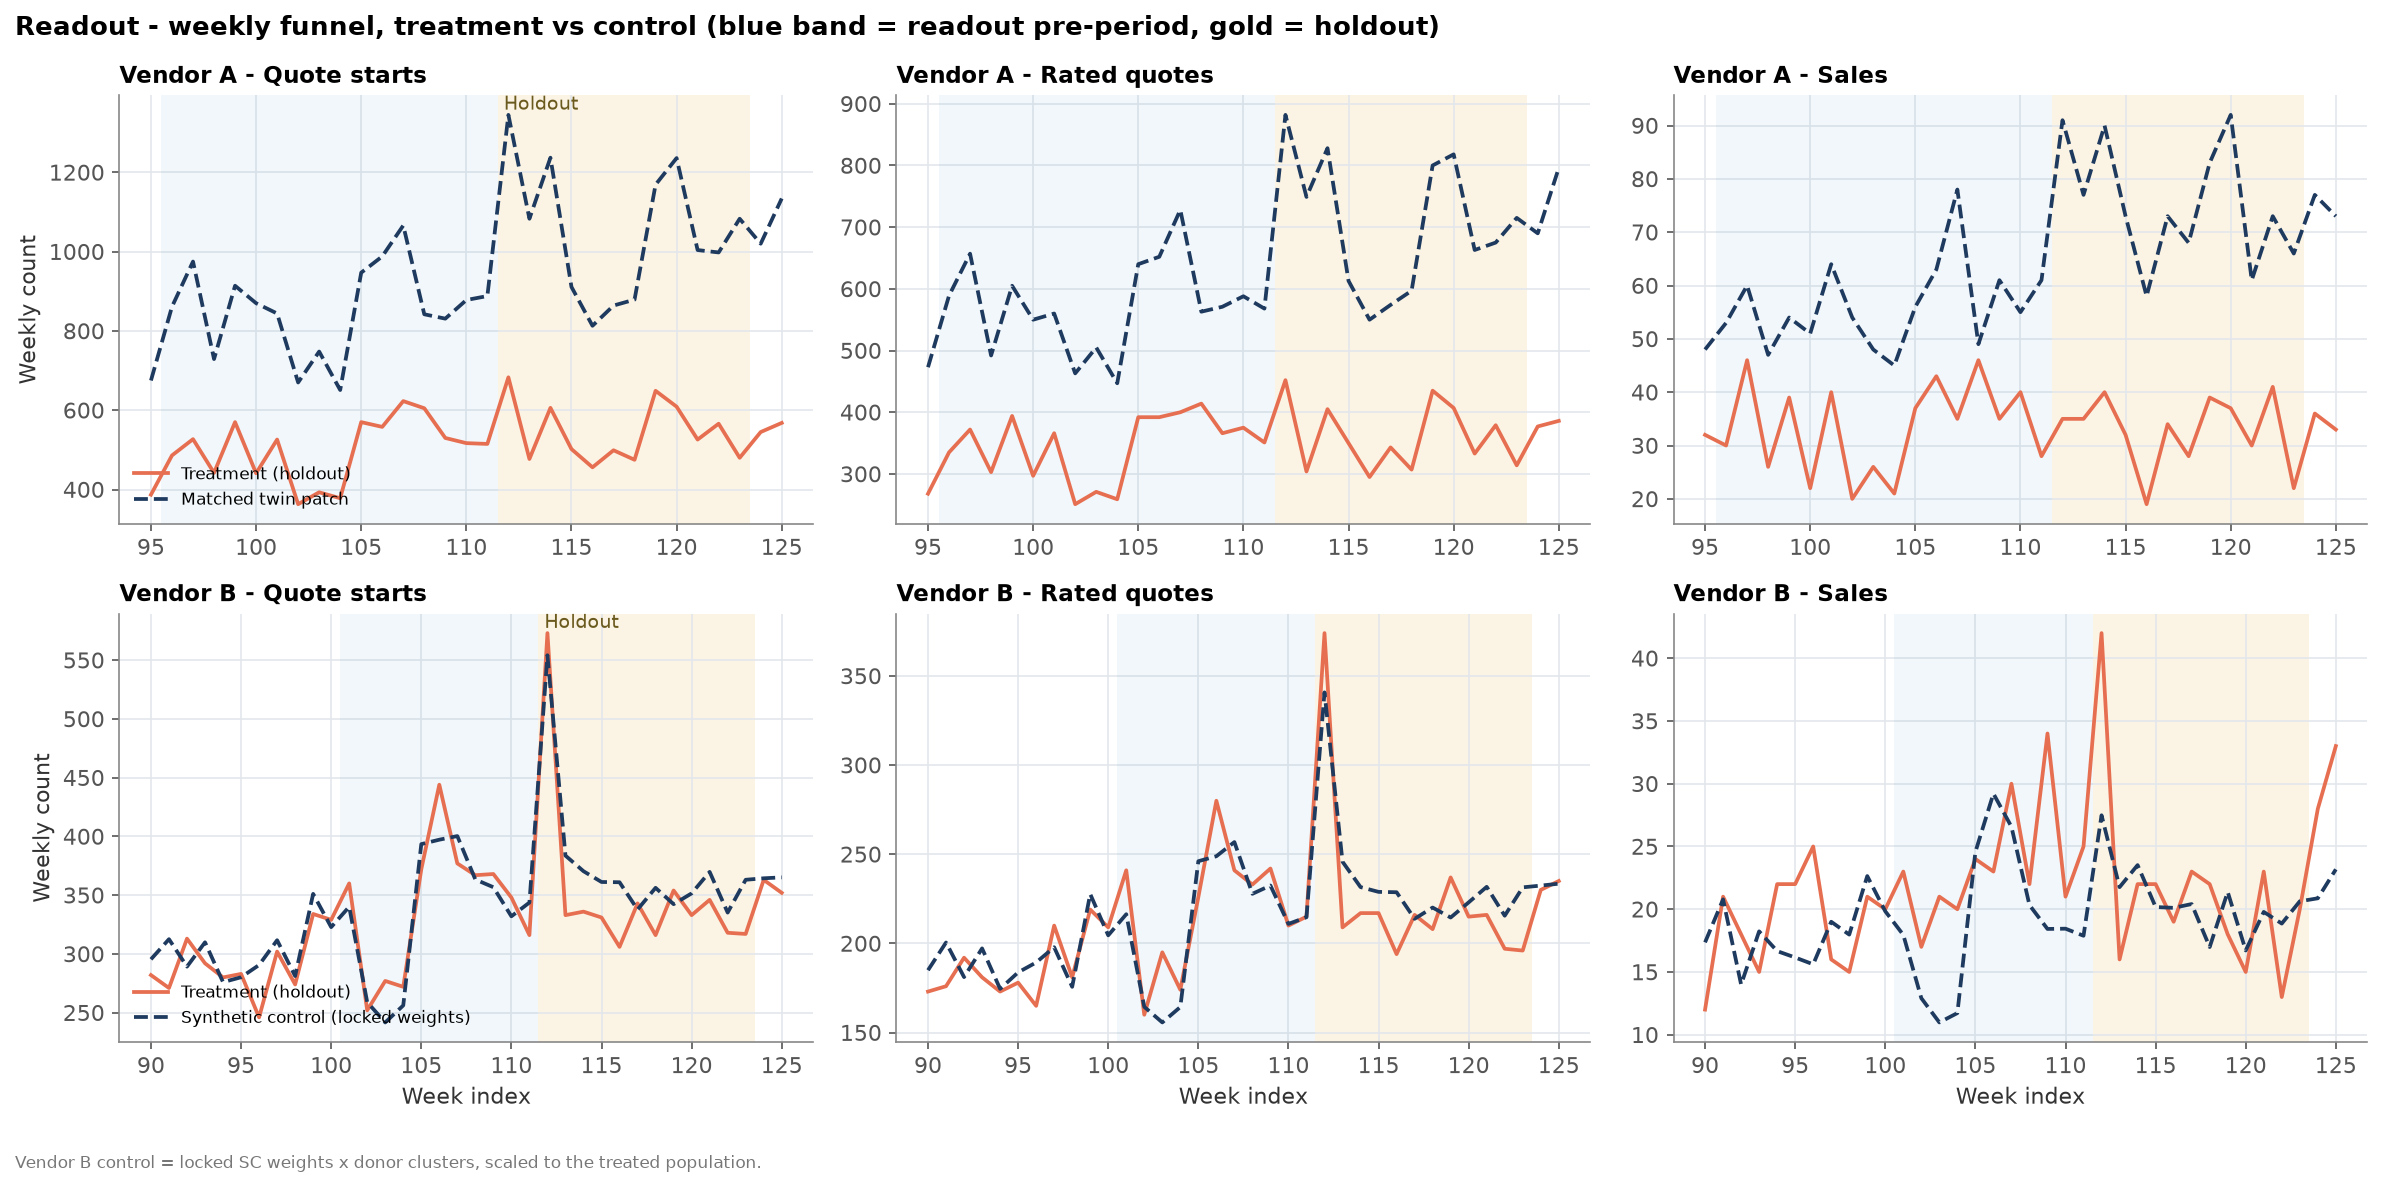

In [30]:
show('19_readout_weekly_funnel', 1000)

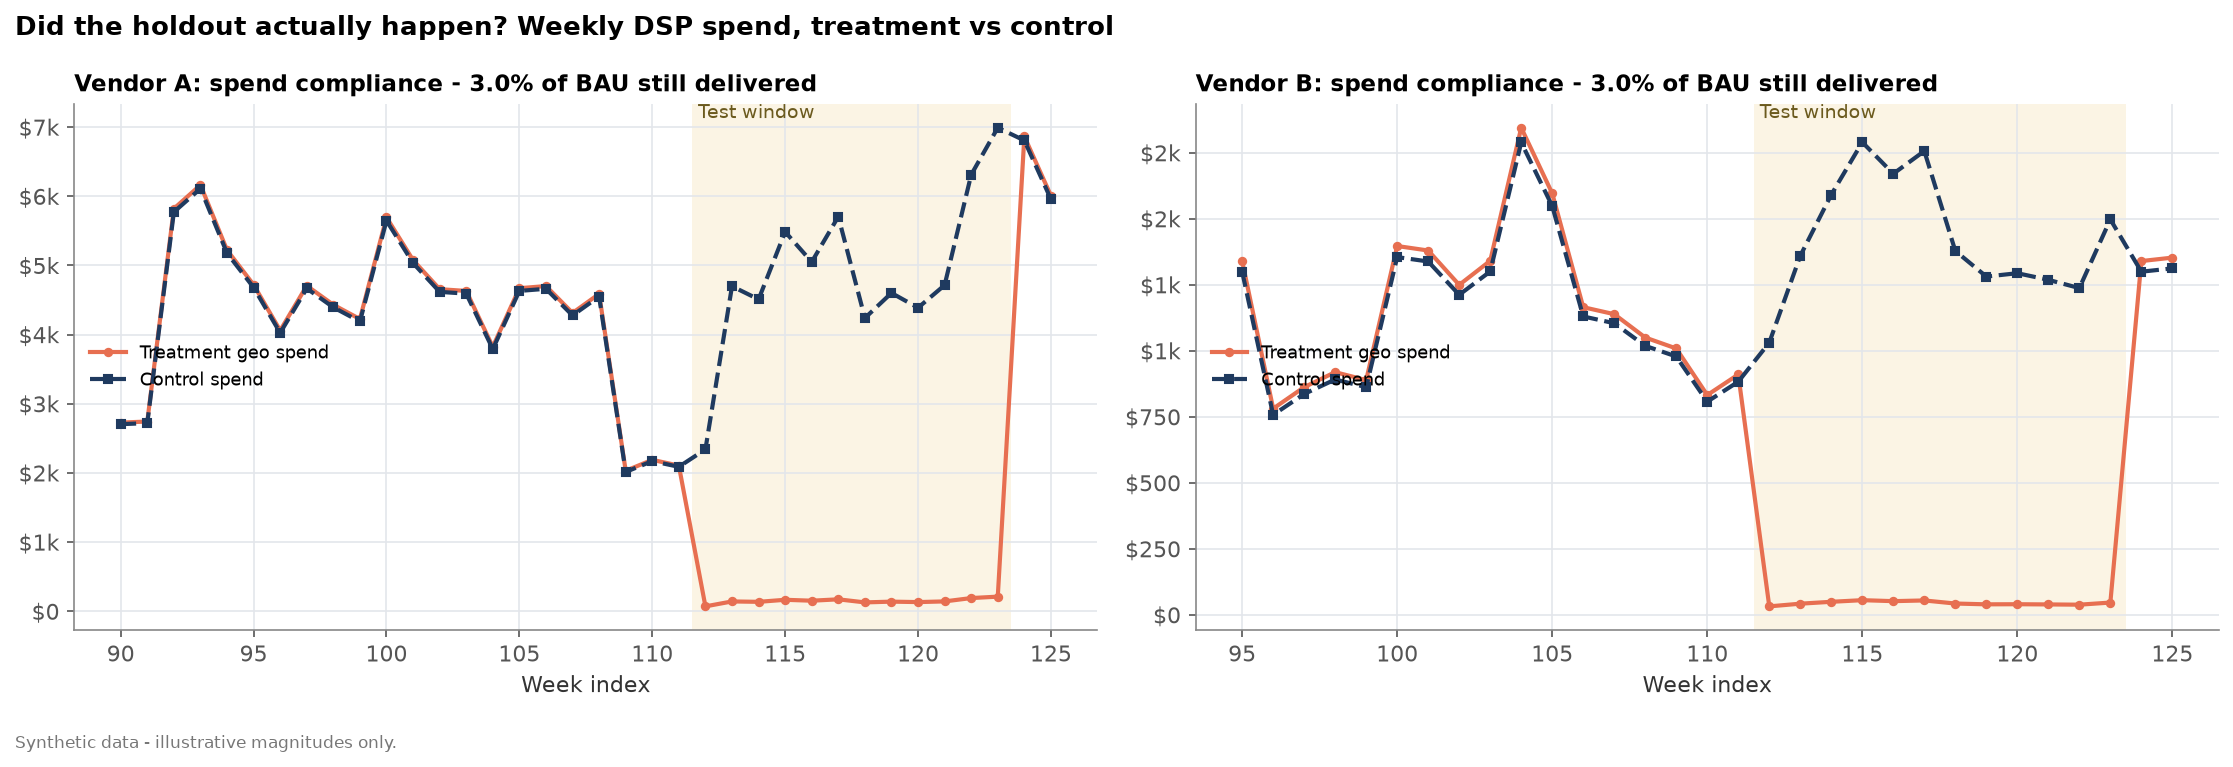

In [31]:
show('26_readout_spend_compliance', 900)

## 8. Readout: change-ratio DiD (headline) and triangulation
The headline is the change-ratio DiD with a week bootstrap. Around it are Welch on weekly gaps, a two-way fixed-effects
regression, a structural time-series (CausalImpact-style) model, synthetic control with placebo p-values, and, for
Vendor B, the ridge-augmented SC. **Significant means only that the 90% interval excludes 0.** The original
CausalImpact p-value contradicted its own CI.

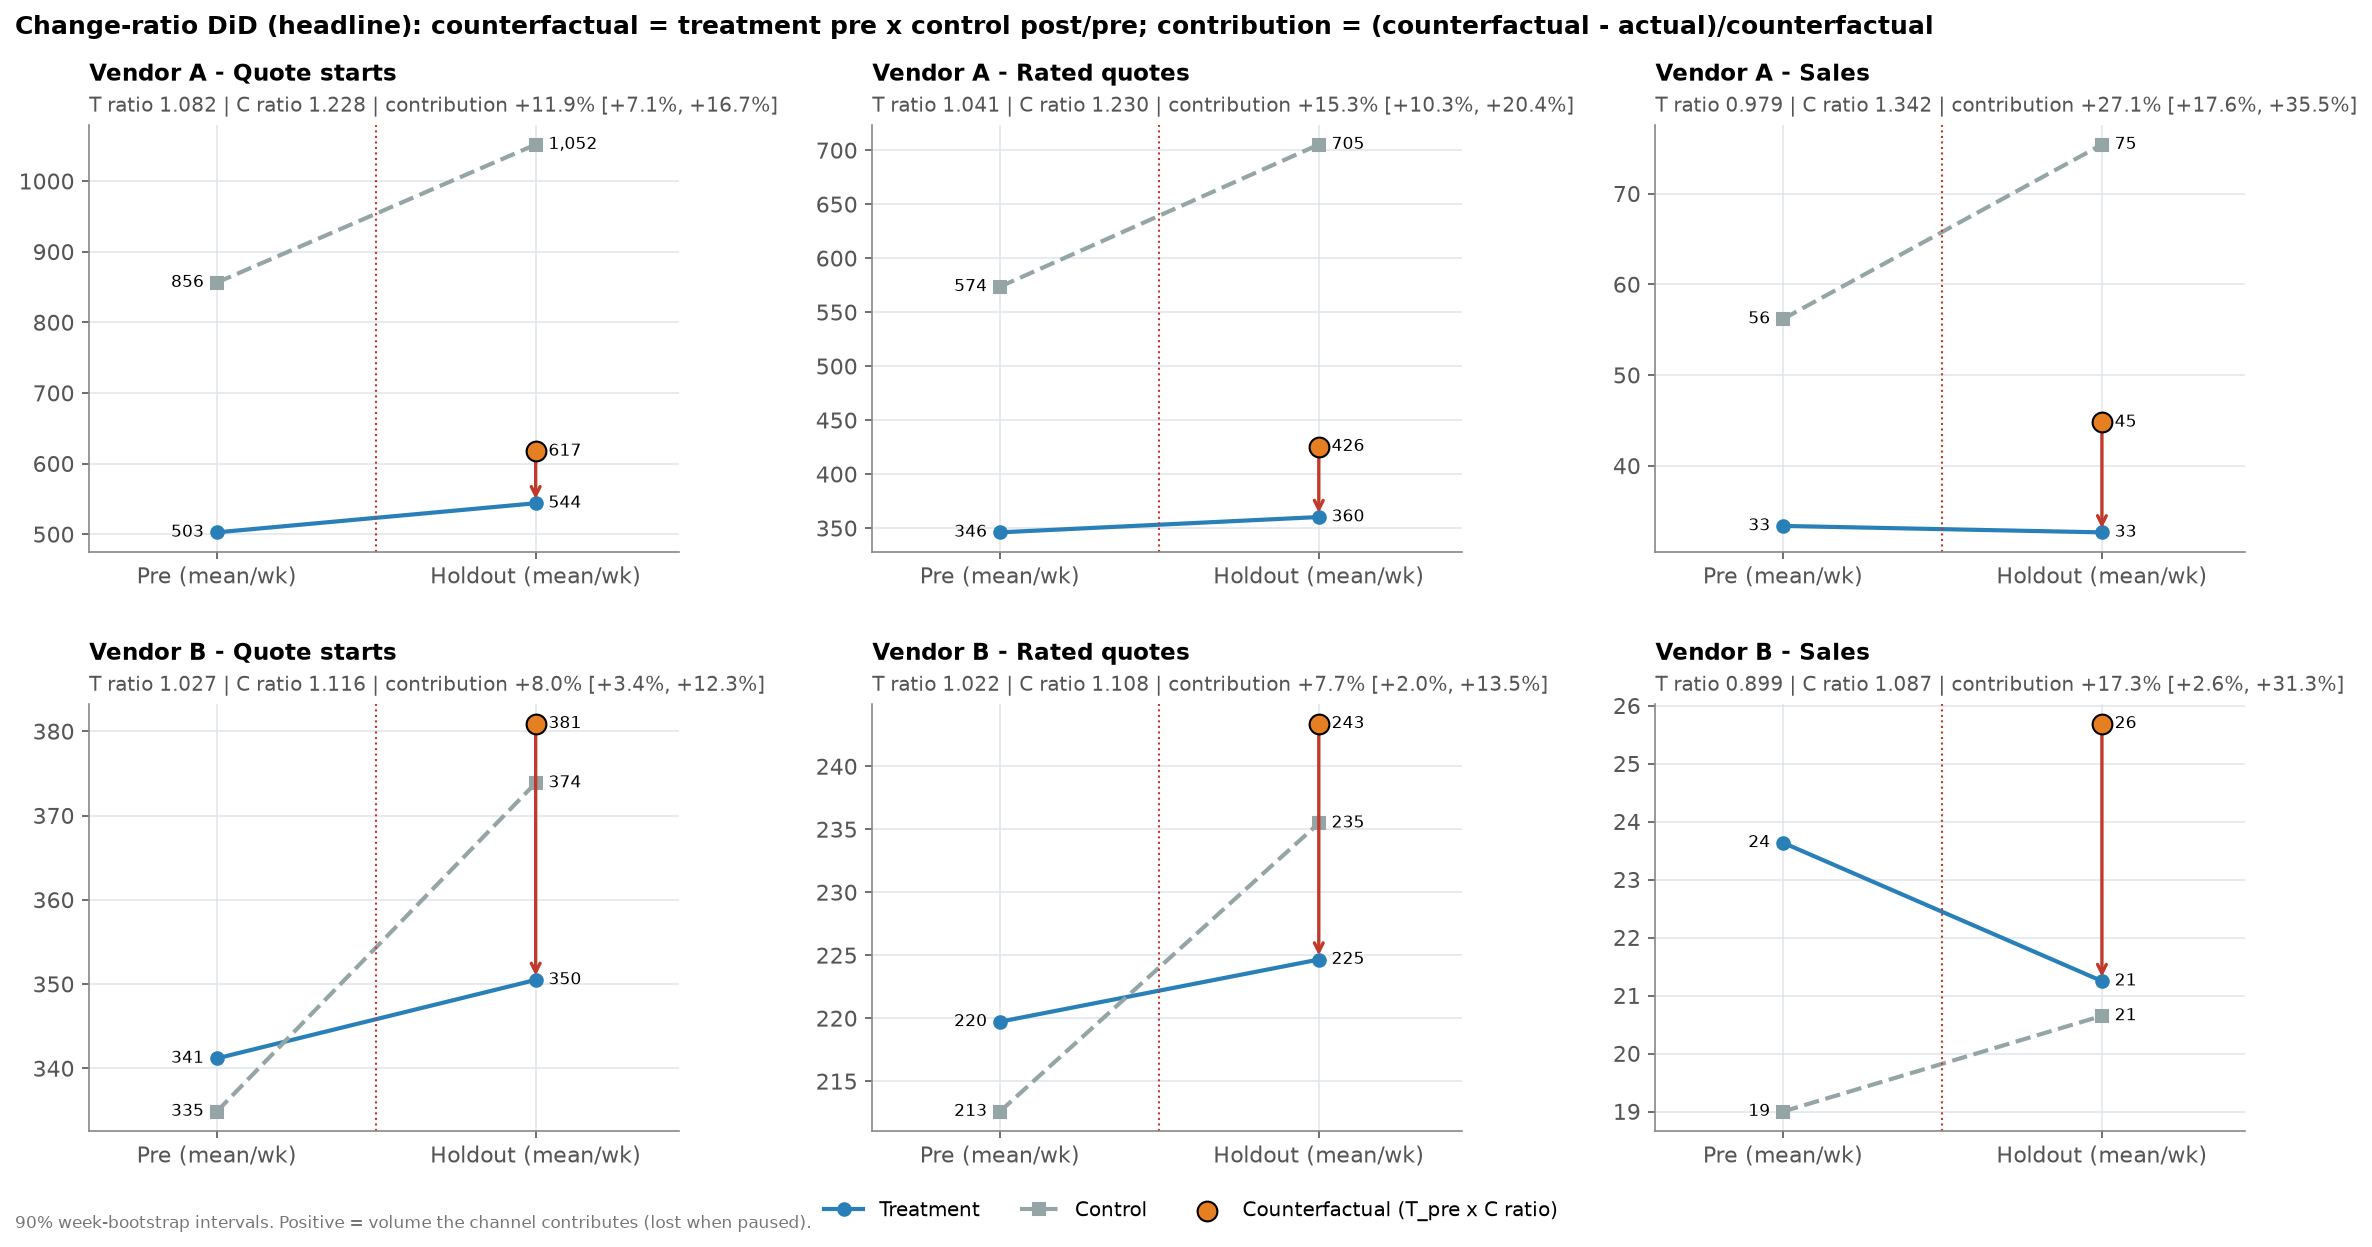

In [32]:
show('20_readout_did_dumbbell', 1000)

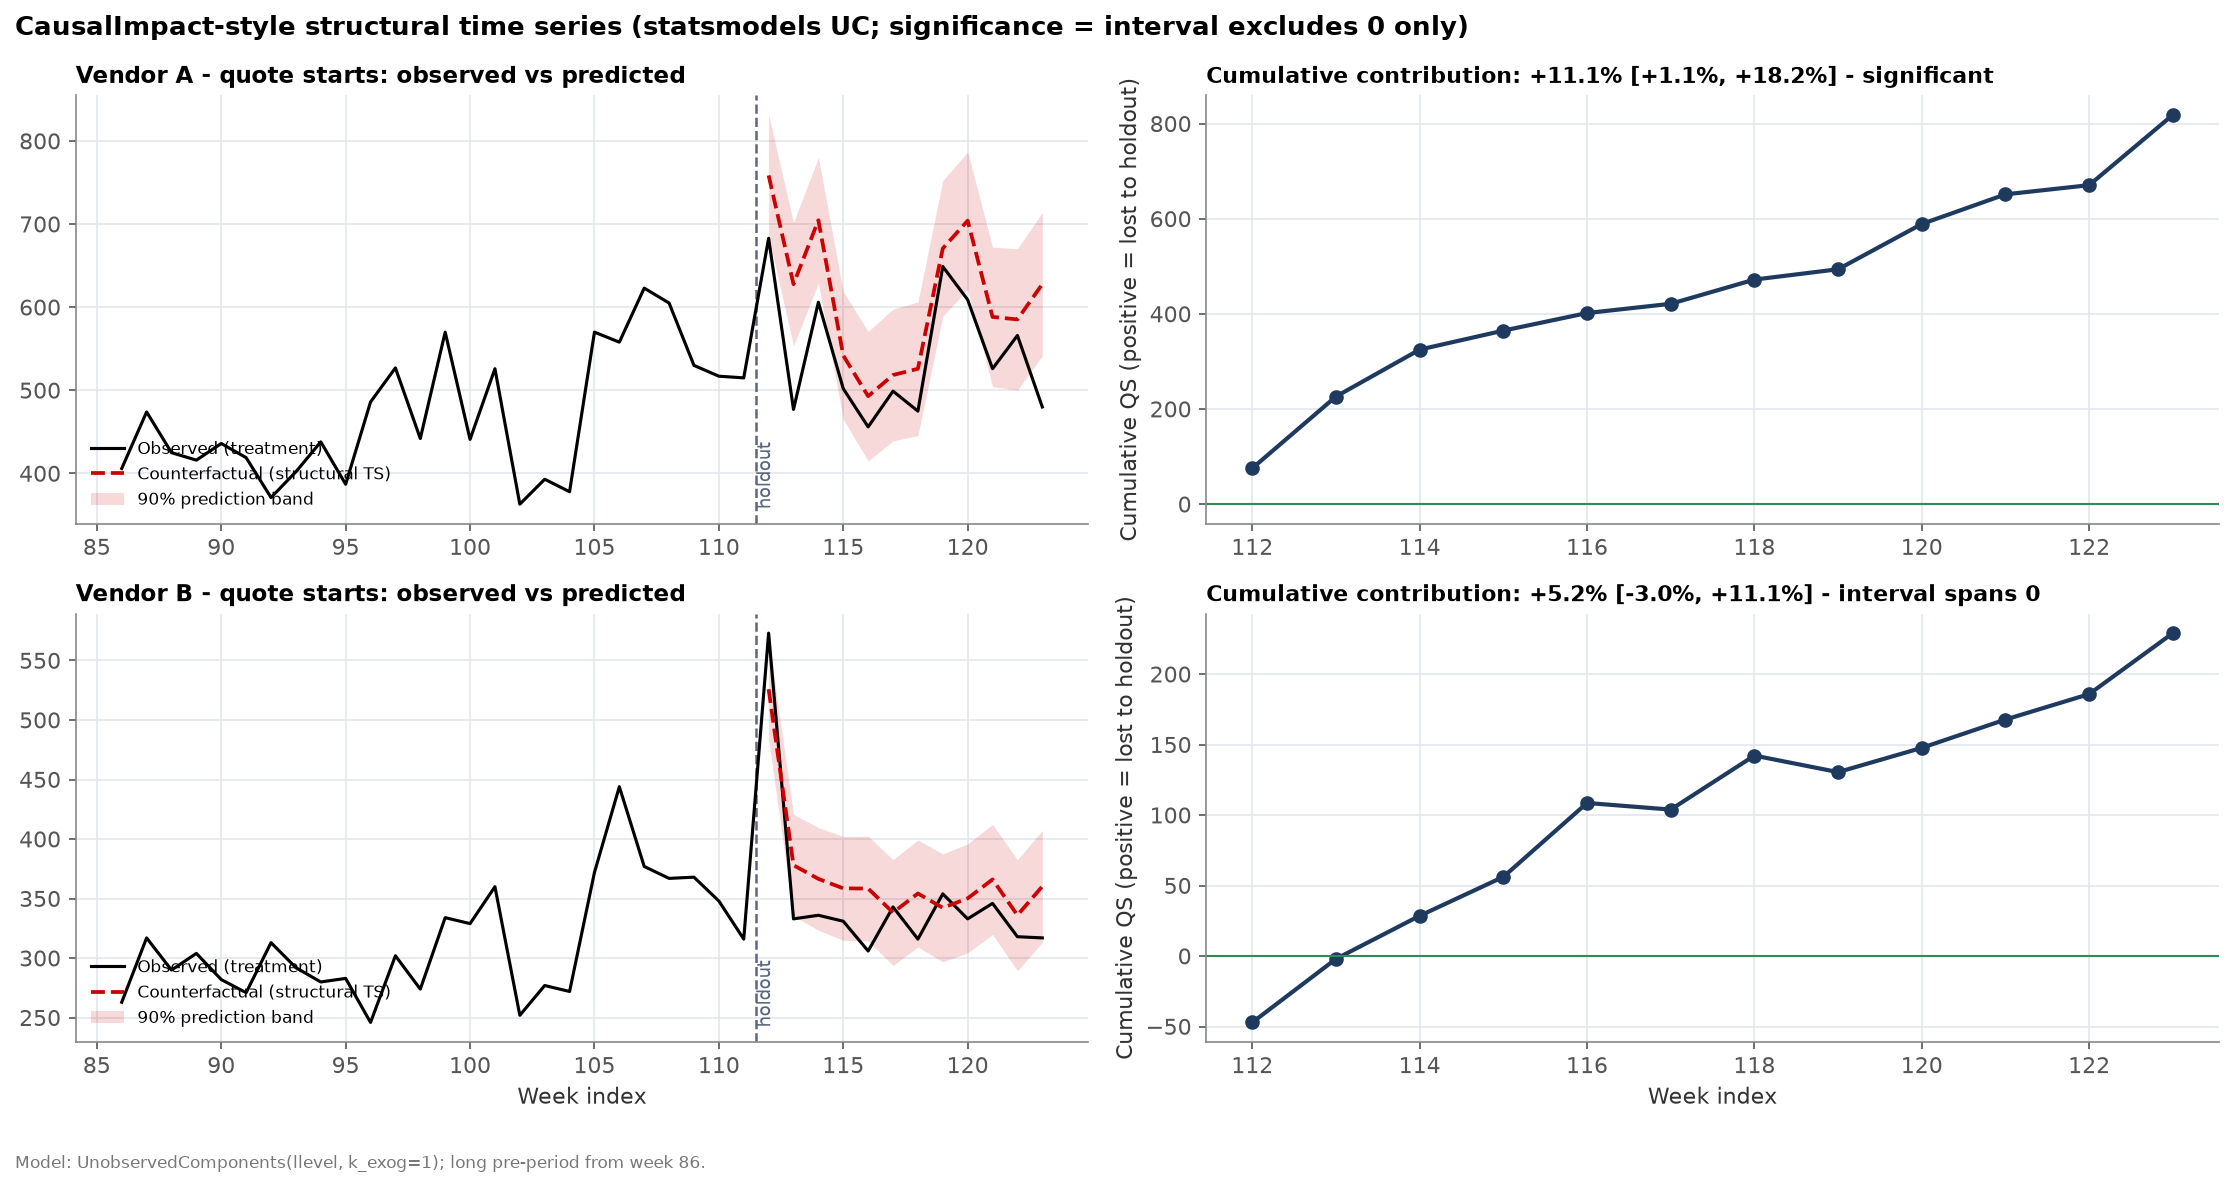

In [33]:
show('21_readout_bsts', 1000)

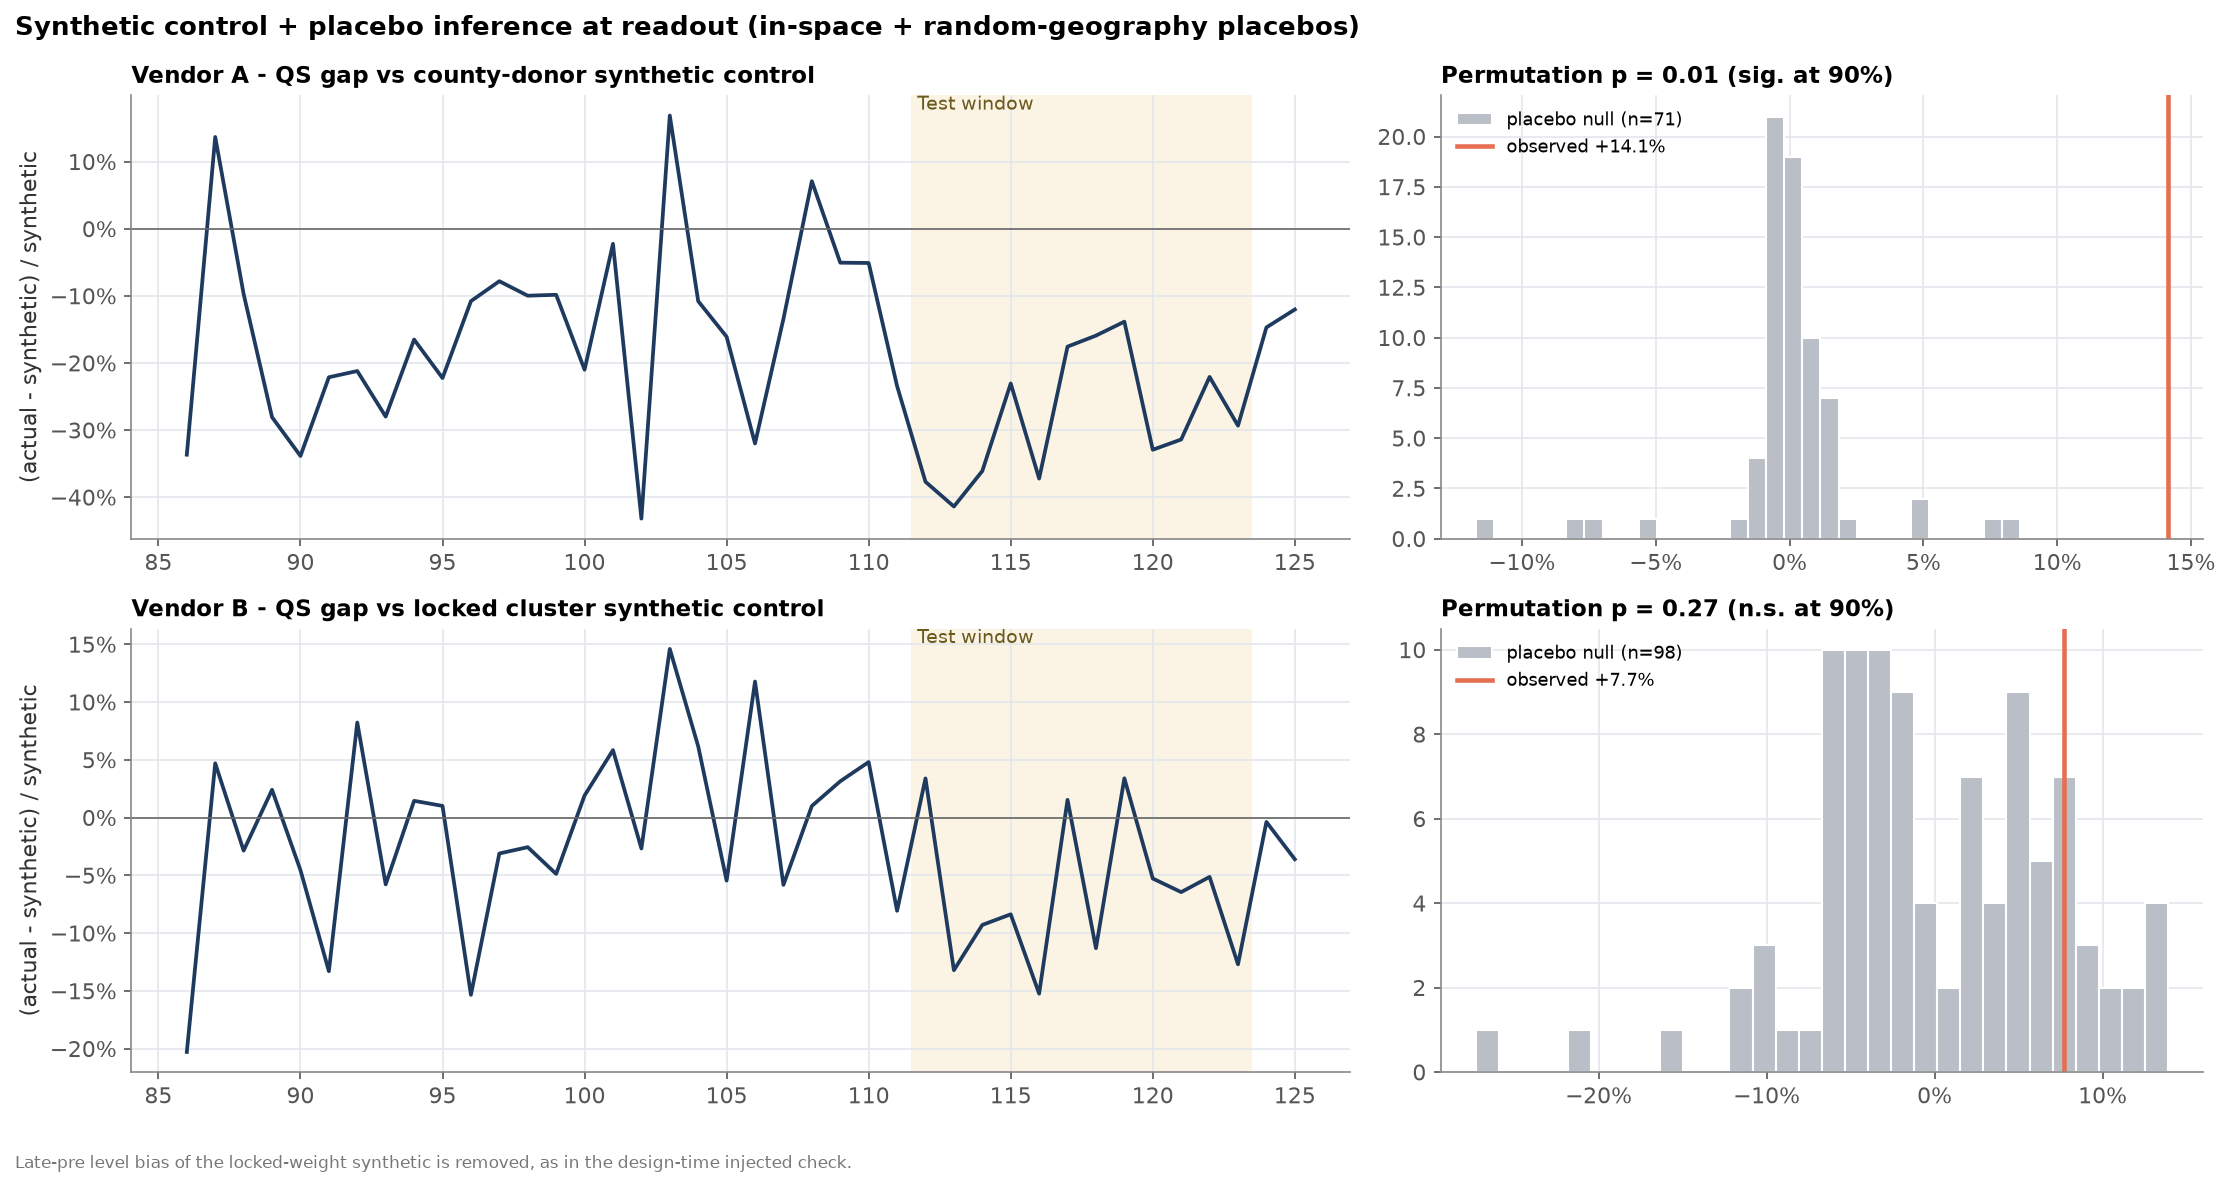

In [34]:
show('22_readout_sc_placebo', 1000)

In [35]:
from incrlab.dsp.readout import truth_table
tri = truth_table(R)
print("interval covers truth:", f"{tri['covers_truth'].mean():.0%} of {len(tri)} estimates")
tri[["vendor", "metric", "method_label", "estimate", "ci_low", "ci_high", "significant", "truth", "error_pp", "covers_truth"]].round(3)

interval covers truth: 76% of 33 estimates


,vendor,metric,method_label,estimate,ci_low,ci_high,significant,truth,error_pp,covers_truth
0,A,qs,Change-ratio DiD,0.119,0.071,0.167,True,0.080,3.904,True
1,A,qs,Welch t (weekly gaps),0.119,0.066,0.172,True,0.080,3.904,True
2,A,qs,Two-way FE regression,0.220,0.161,0.278,True,0.080,13.962,False
3,A,qs,Structural TS (CausalImpact-style),0.111,0.011,0.182,True,0.080,3.144,True
4,A,qs,Synthetic control + placebos,0.141,0.107,0.178,True,0.080,6.142,False
5,A,rated,Change-ratio DiD,0.153,0.103,0.204,True,0.108,4.496,True
6,A,rated,Welch t (weekly gaps),0.153,0.095,0.212,True,0.108,4.496,True
7,A,rated,Two-way FE regression,0.245,0.180,0.309,True,0.108,13.632,False
8,A,rated,Structural TS (CausalImpact-style),0.151,0.058,0.226,True,0.108,4.246,True
9,A,rated,Synthetic control + placebos,0.156,0.140,0.178,True,0.108,4.789,False


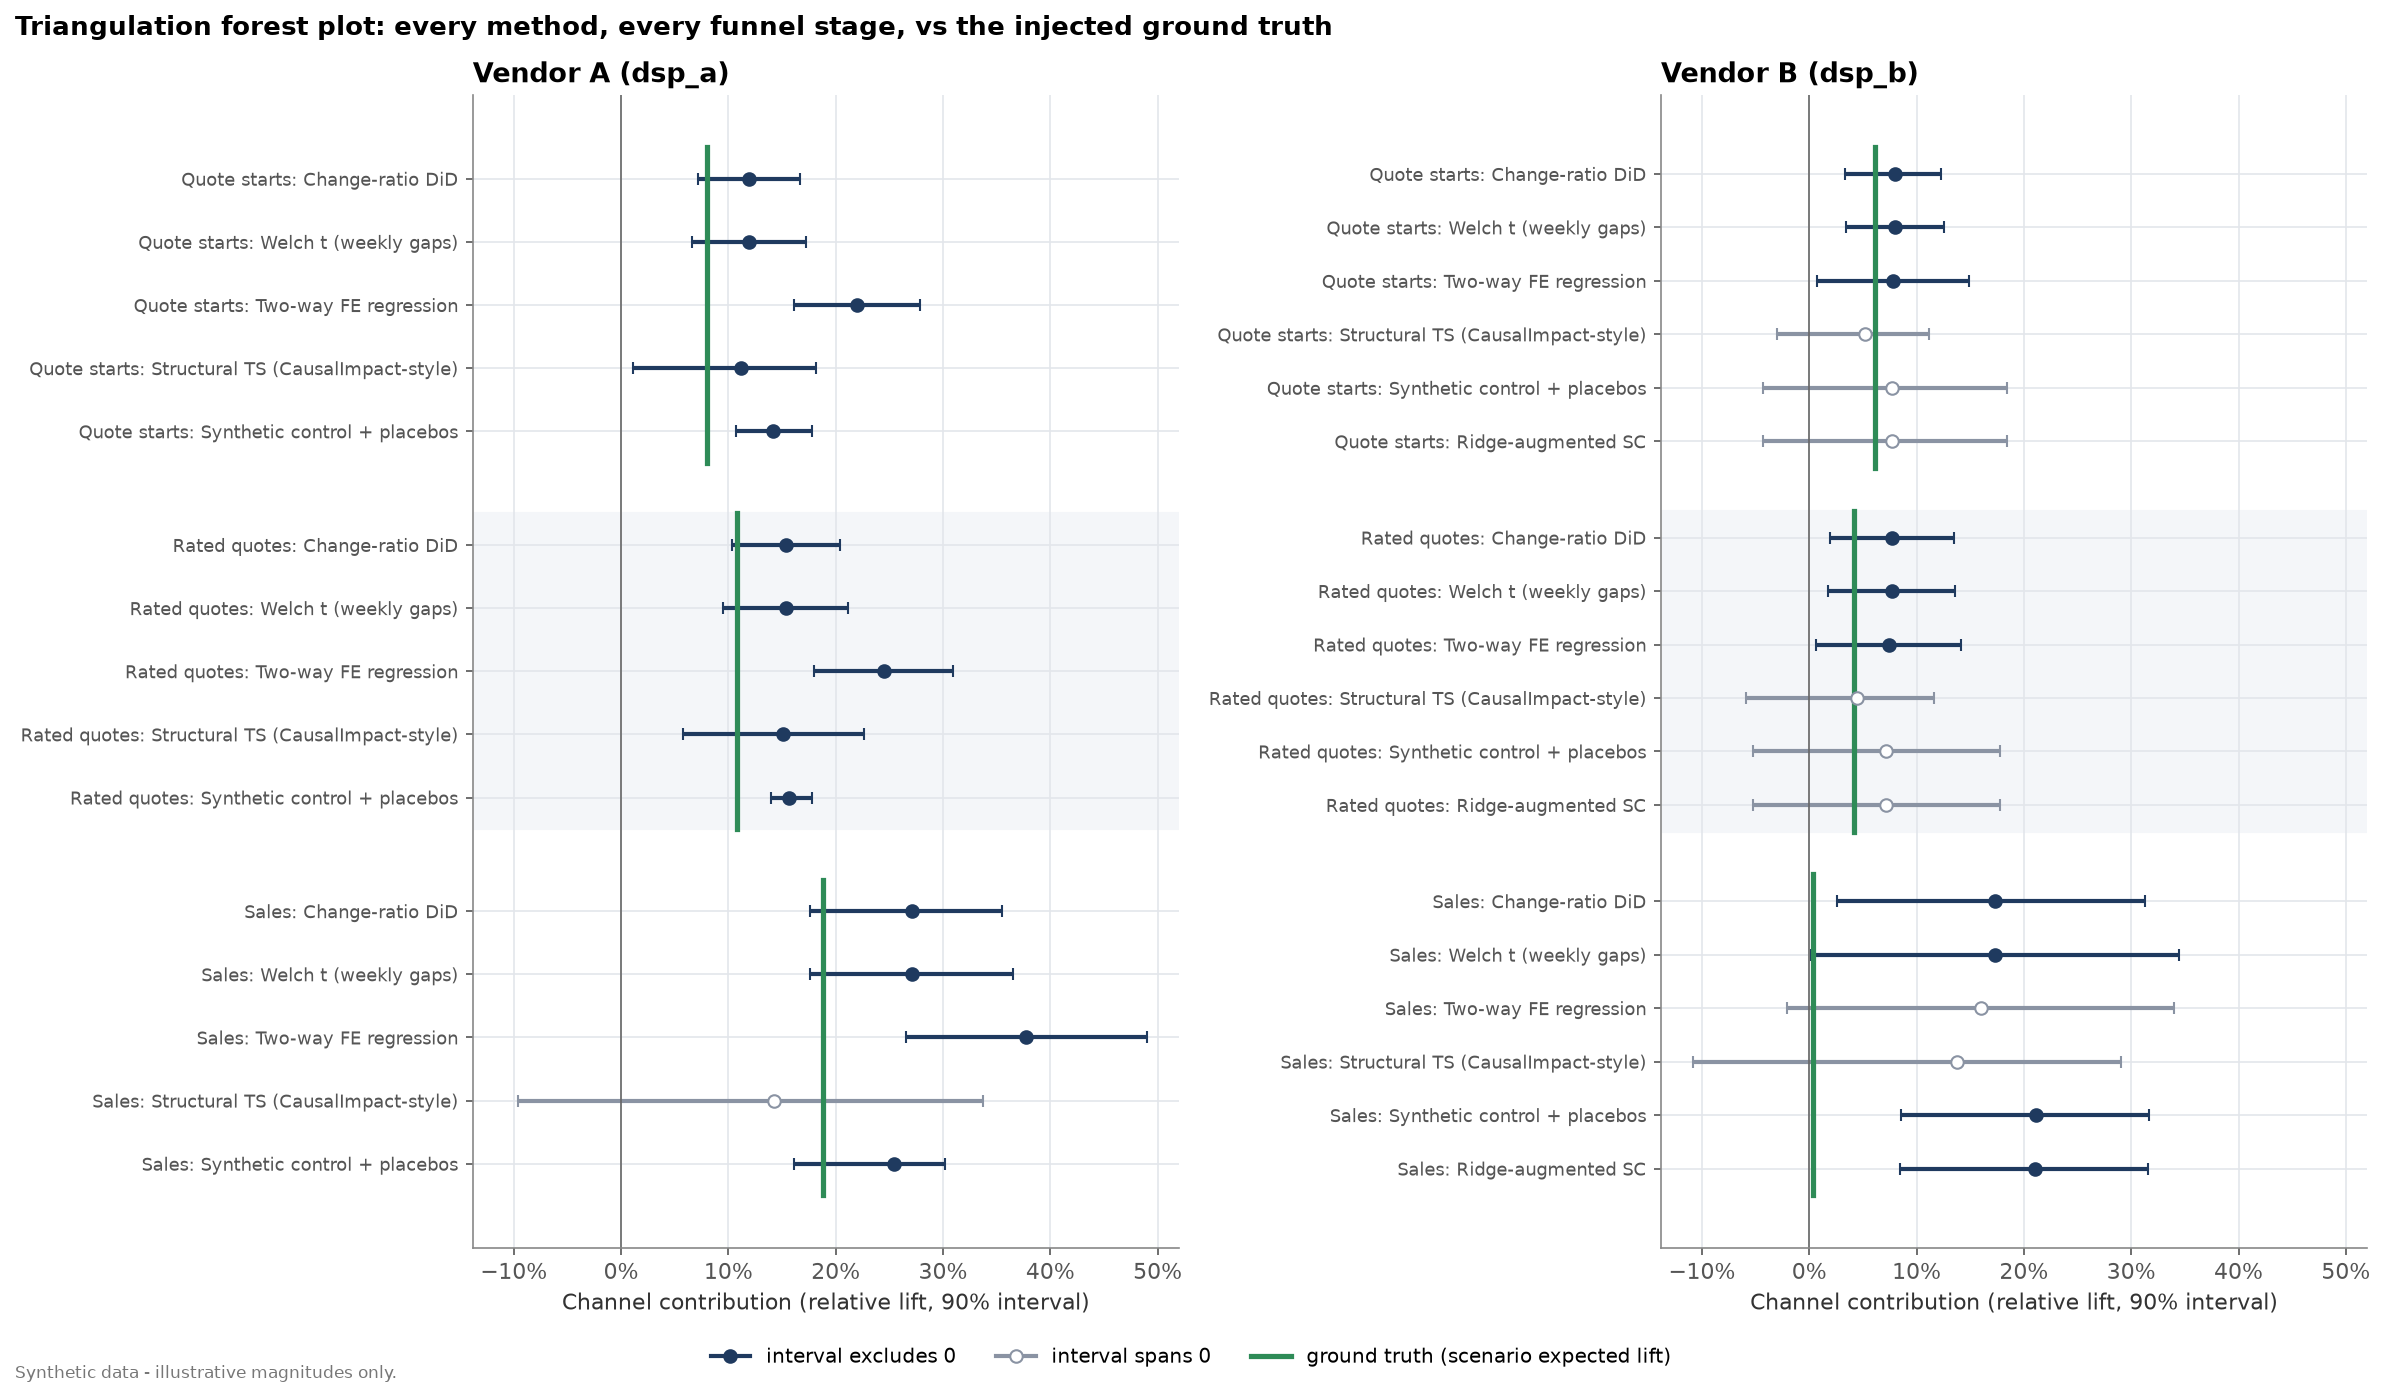

In [36]:
show('23_readout_triangulation_forest', 1000)

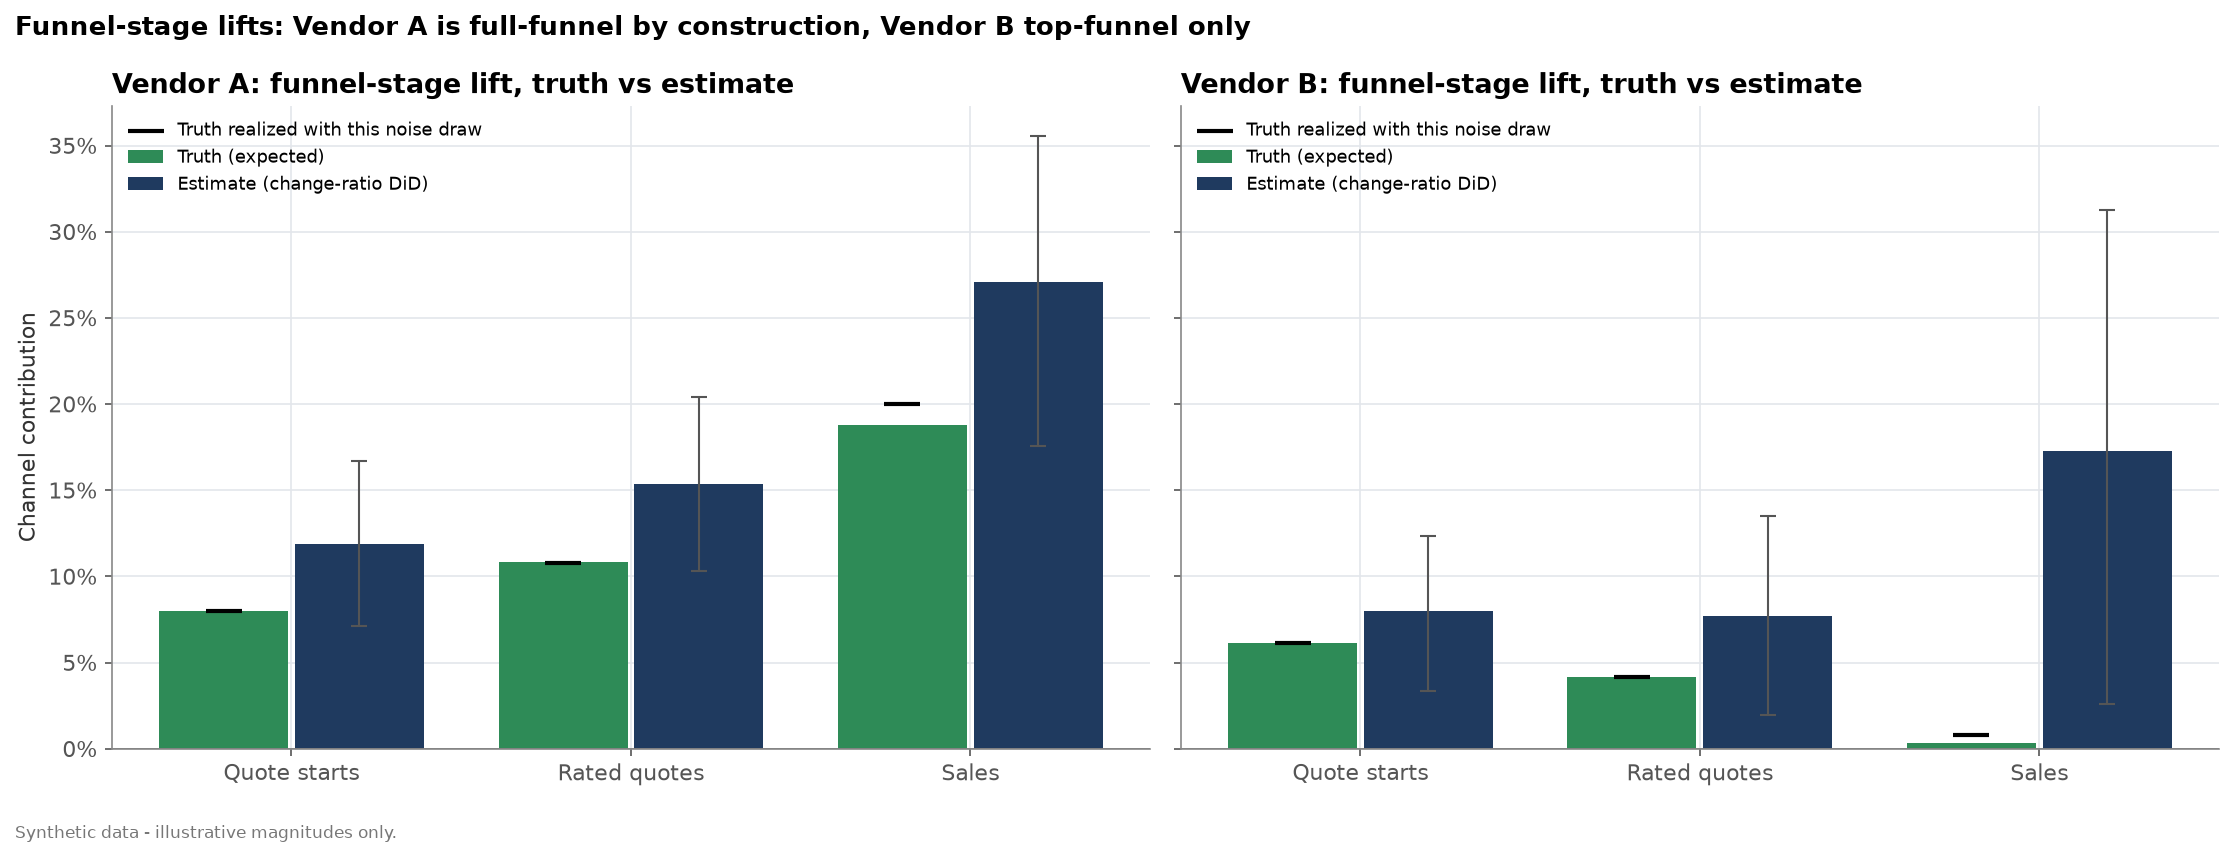

In [37]:
show('24_readout_funnel_truth_vs_estimate', 1000)

## 9. Business translation, spillover, decision
Incremental cost per QS, rated quote and sale are set against vendor-reported and last-touch cost-pers. The buffer
check compares served zips just outside the treatment to the control: it shows how far an *adjacent* control would
have mis-read the effect.

**Decision rule (fixed before launch, hinges on sales).** GO needs a significant sales-stage lift *from a design powered
for sales* and P(window ROI > 1) ≥ 80%. NO-GO when P(ROI > 1) ≤ 20%, or a sales-powered design rules out the
break-even lift. A design that is not powered for sales can at most return **HOLD - RE-TEST POWERED ON SALES**:
quote-start lift alone, or a "significant" sales read from an under-powered design (exaggerated by construction,
the type-M / winner's-curse problem), never funds a GO.

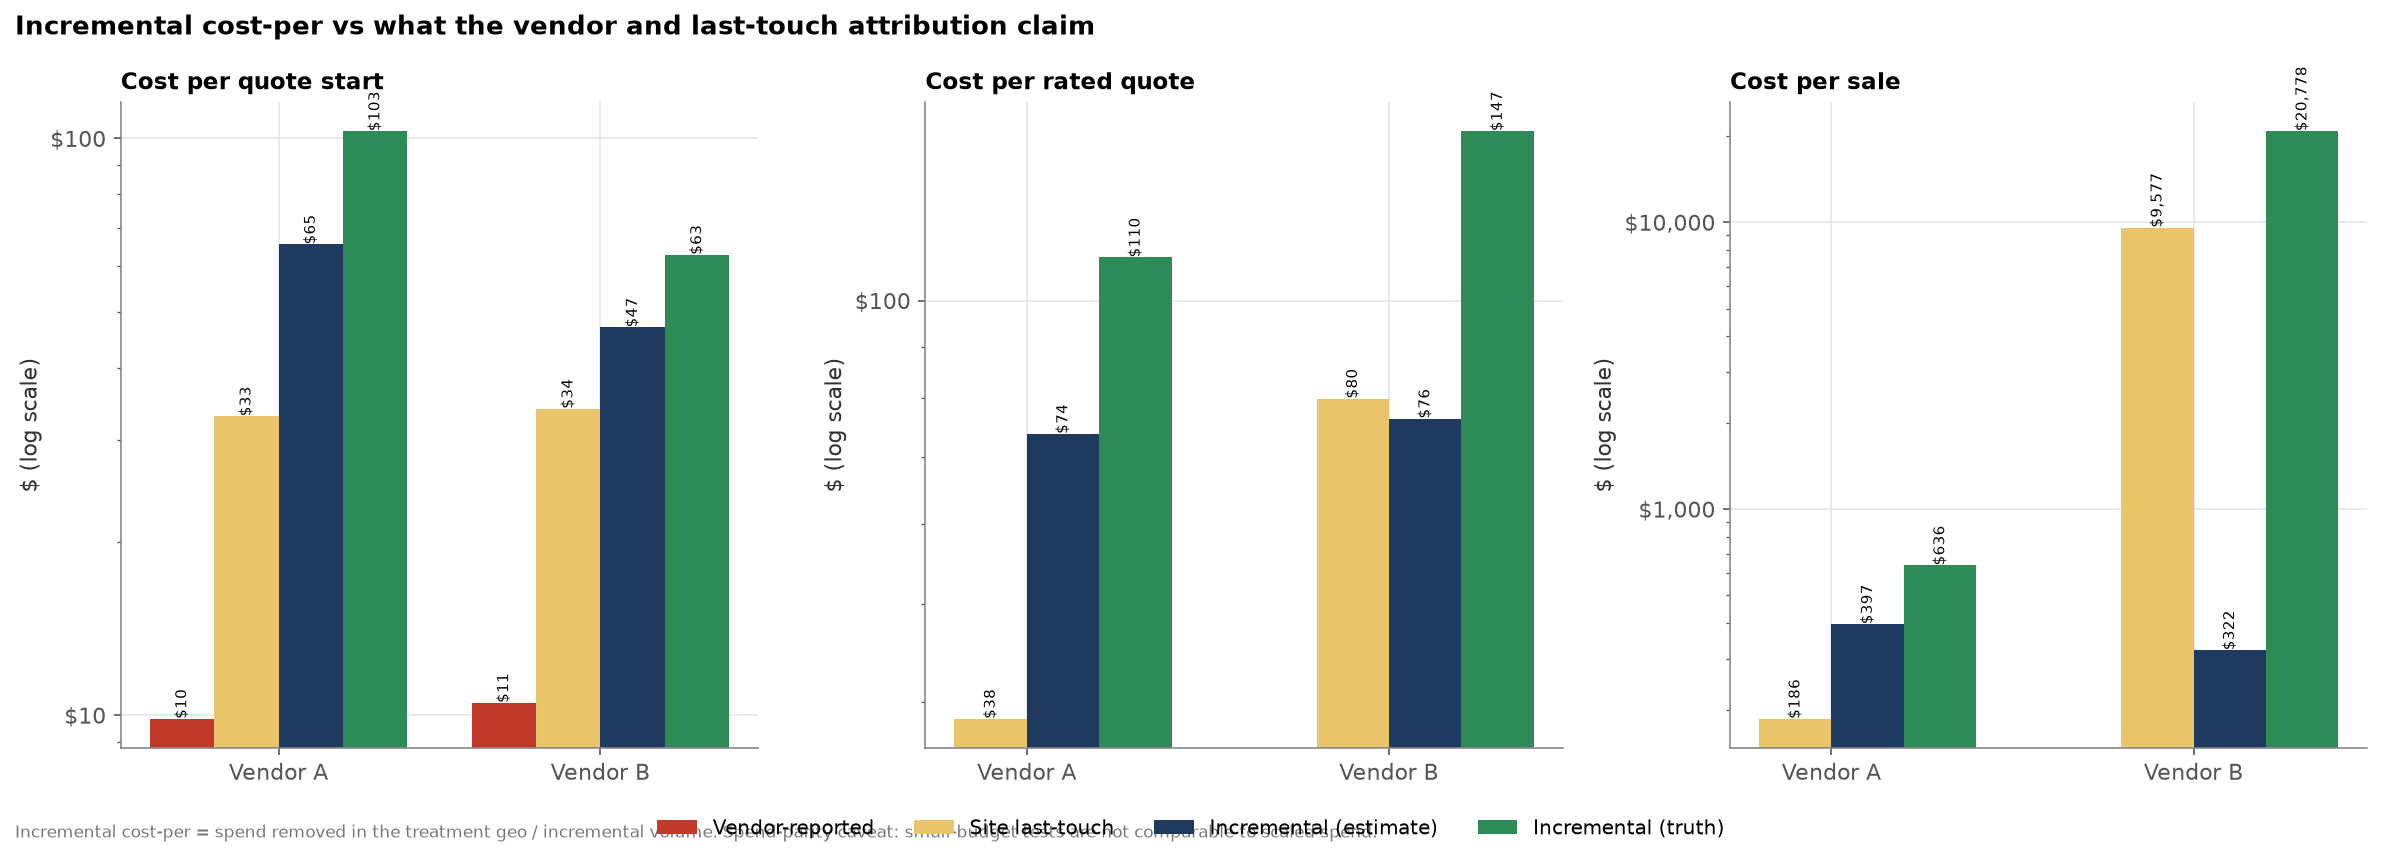

In [38]:
show('25_readout_cost_per', 1000)

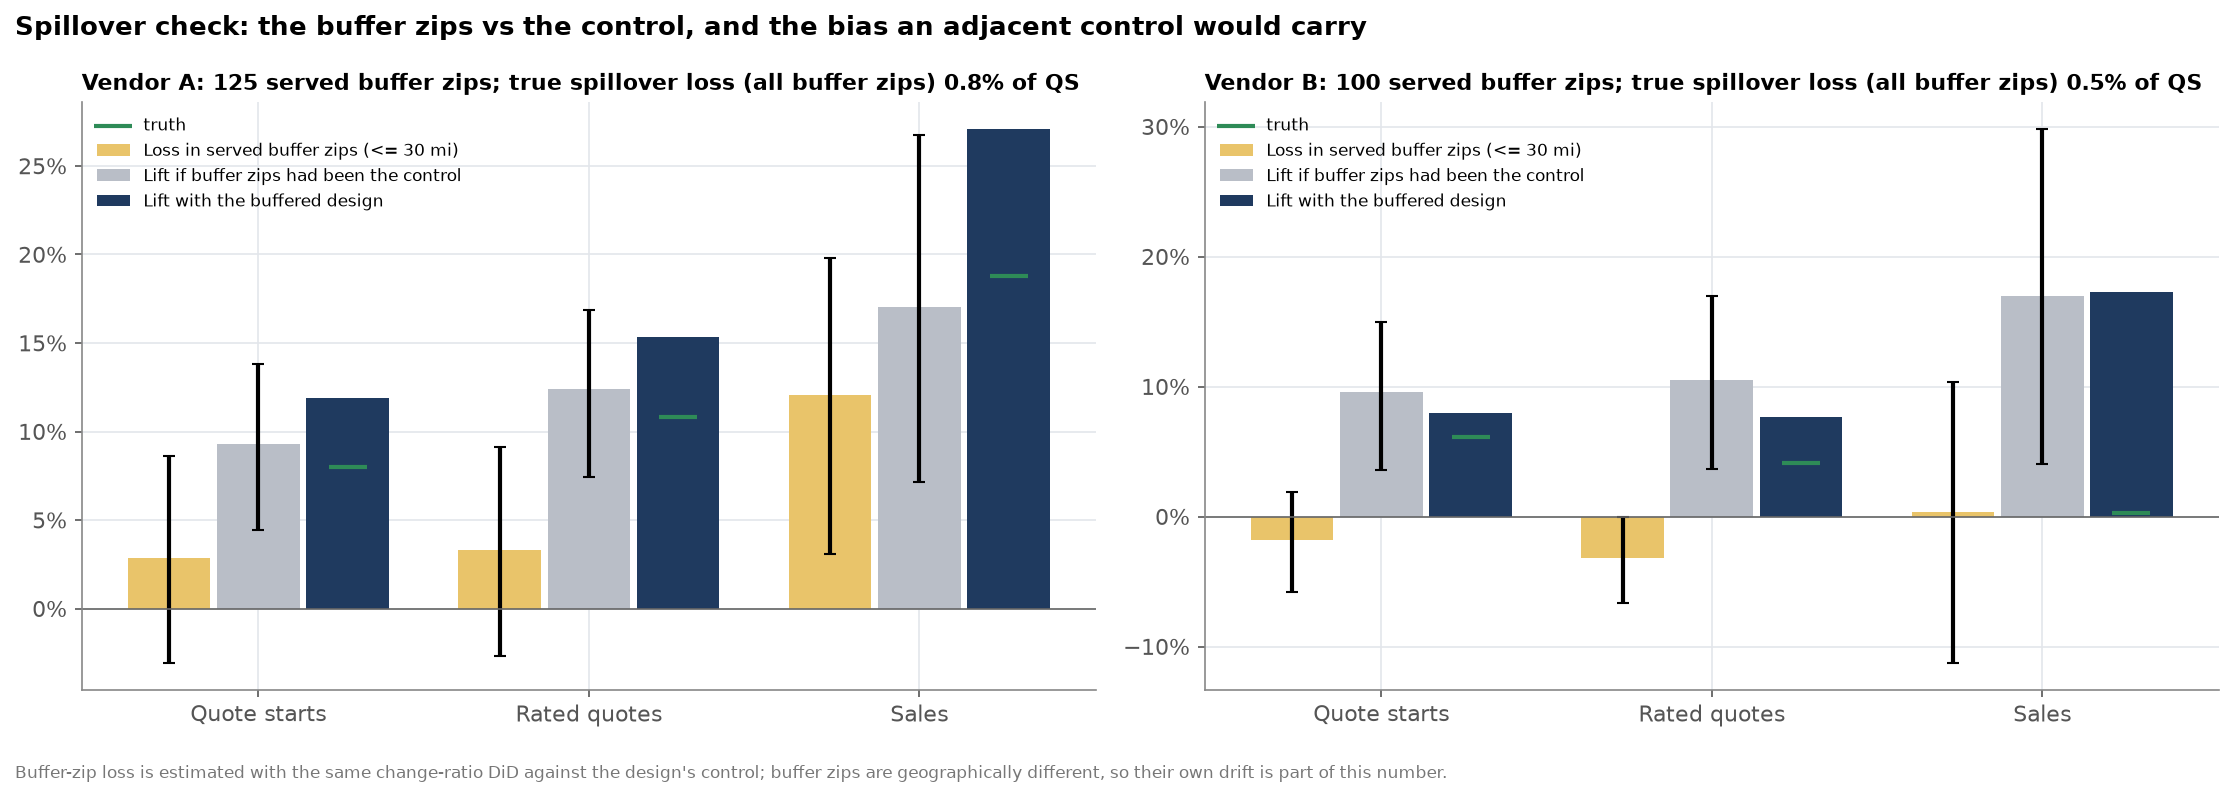

In [39]:
show('27_readout_spillover_check', 1000)

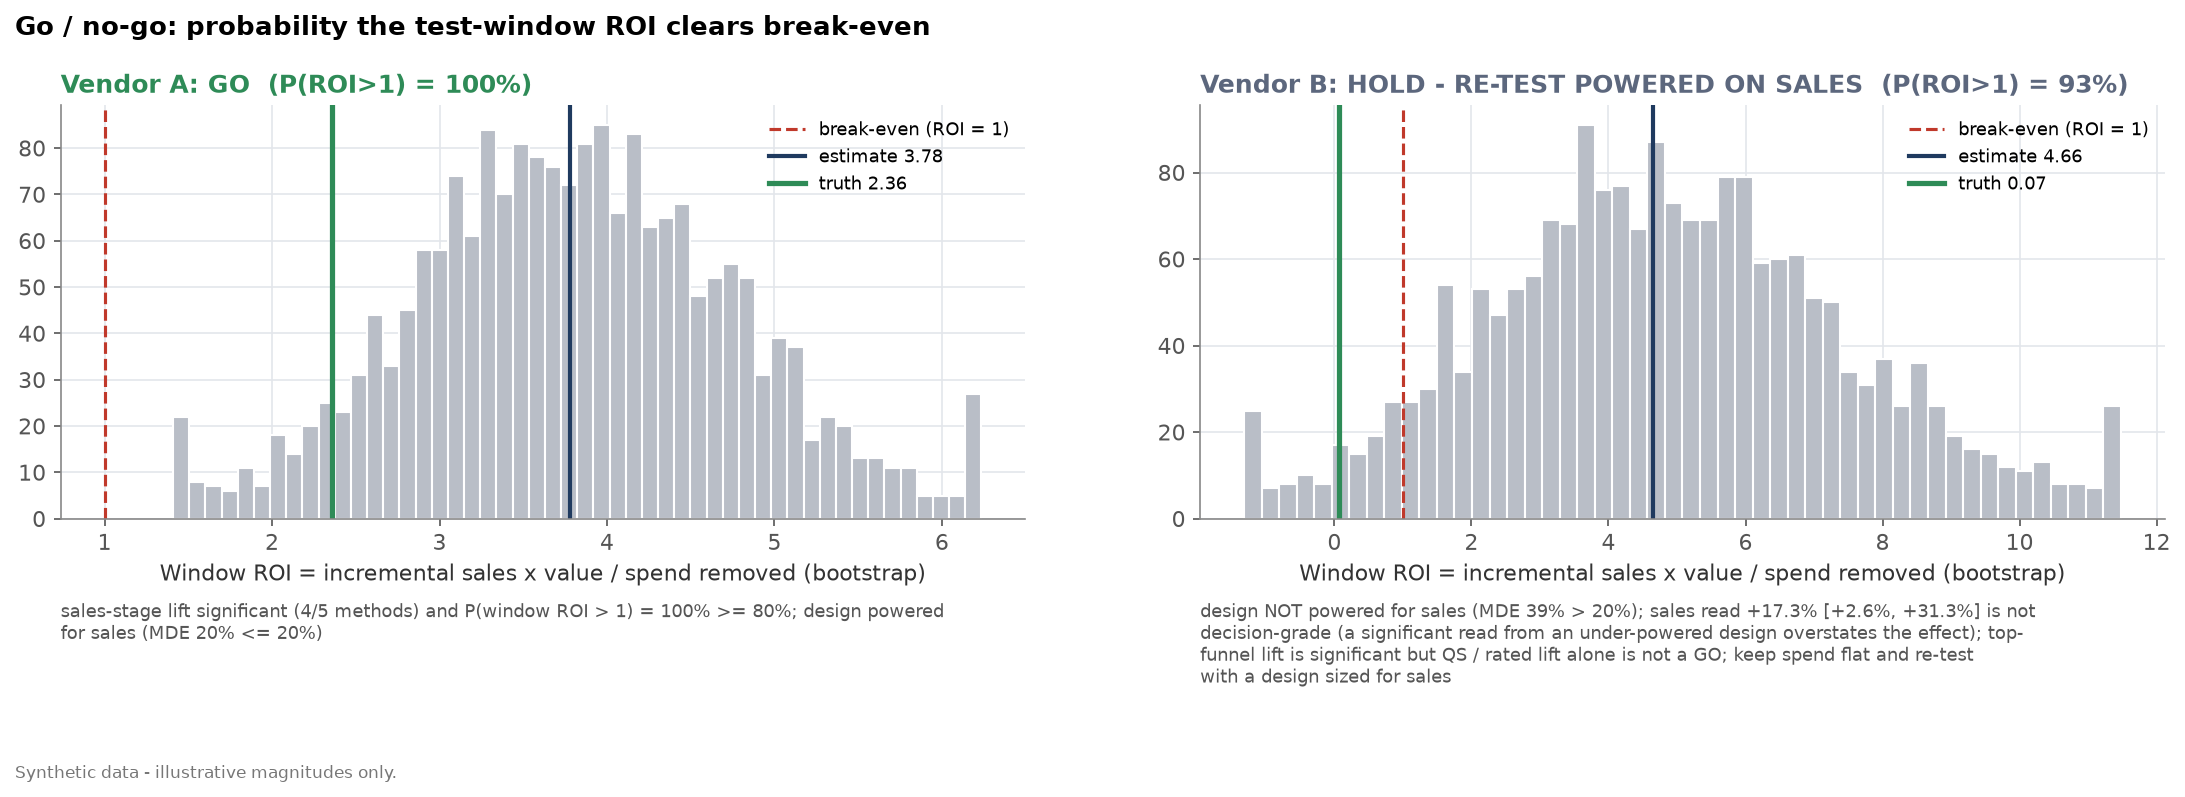

In [40]:
show('28_readout_roi_decision', 1000)

In [41]:
for v, d in R.decisions.items():
    print(f"{v}: {d['decision']} — {d['rationale']}")
res = json.load(open(ROOT / "reports/results/dsp.json"))
pd.DataFrame(res["extra"]["incremental_per_dollar"]).T[["spend", "sales", "se", "qs", "qs_se", "truth_sales_per_dollar"]]

A: GO — sales-stage lift significant (4/5 methods) and P(window ROI > 1) = 100% >= 80%; design powered for sales (MDE 20% <= 20%)
B: HOLD - RE-TEST POWERED ON SALES — design NOT powered for sales (MDE 39% > 20%); sales read +17.3% [+2.6%, +31.3%] is not decision-grade (a significant read from an under-powered design overstates the effect); top-funnel lift is significant but QS / rated lift alone is not a GO; keep spend flat and re-test with a design sized for sales


,spend,sales,se,qs,qs_se,truth_sales_per_dollar
dsp_a,57759.291001,0.00252,0.000865,0.01527,0.004159,0.001571
dsp_b,17158.376925,0.003105,0.003299,0.021264,0.007264,0.000048


## 10. Takeaways (synthetic world)
* **Vendor A (designed for sales).** The power ladder sized the holdout so a 20% sales contribution is detectable at
  80% power over 12 weeks, with a strict-gate twin. The readout detects the full-funnel effect at every stage and
  the decision is **GO**. The point estimates sit above the truth (one noise draw; see the truth table), and the
  truth lies inside or near the 90% intervals; the decision does not depend on the overshoot.
* **Vendor B (top-funnel vendor).** QS lift is real and well measured. The sales design MDE is far above the 20% bar,
  so even though the sales point estimate looks large, the pre-registered rule returns **HOLD - re-test powered on
  sales**. That is exactly right here: the true sales effect is ~0, and the "significant" sales read is noise
  amplified by an under-powered design.
* Vendor-reported cost per QS is several times cheaper than the incremental cost per QS for both vendors.
* `extra.incremental_per_dollar` feeds the MMM calibration with SE = max(bootstrap SE, design SE), so an
  under-powered read cannot dominate the likelihood.

Full methodology: `docs/dsp_pipeline.md`. Executive readout: `reports/readouts/dsp.md`.

In [42]:
display(Markdown(open(ROOT / 'reports/readouts/dsp.md').read()))

# Programmatic DSP geo-incrementality - executive readout (synthetic)

> Synthetic data with known ground truth; every number below is generated by `python -m incrlab.dsp` and stored in `reports/results/dsp.json`. Magnitudes are illustrative and design-dependent.

## Pre-registered design rule

- **Vendor A was designed to detect a 20% contribution to SALES at 80% power** (one-sided alpha = 0.1, 12-week holdout, change-ratio DiD). The holdout size was chosen by the module's own pre-period power analysis: the size ladder 500k, 750k, 1000k, 1250k was evaluated on design-window data only and the smallest strict-gate design meeting the target was kept -> **POWERED**, 998,063 pop, design sales MDE 19.7%.
- Sizing table (design-window data only; no post-launch data or ground truth is used):

| Holdout target | Gate tier | Strict pairs | QS MDE | Rated MDE | Sales MDE | Meets rule |
|---|---|---|---|---|---|---|
| 500k | relaxed | 0 | 12.8% | 15.5% | 21.7% | no |
| 750k | strict | 6 | 9.9% | 8.5% | 21.9% | no |
| 1000k | strict | 2 | 7.3% | 7.1% | 19.7% | yes |
| 1250k | strict | 5 | 6.7% | 6.3% | 17.8% | yes |

- The original plan (0.5M pop, 6 weeks) had a sales MDE near 30% and only a relaxed-tier twin; it would have read a 15% true sales contribution as noise. Hence the longer window and larger holdout.
- Vendor B (same 12-week calendar): design sales MDE 39.0%. Decision rule for both vendors (fixed before launch): **GO** requires a significant SALES lift from a design powered for sales (design MDE <= 20%) and P(ROI > 1) >= 80%. **NO-GO** when P(ROI > 1) <= 20%, or when a sales-powered design's interval rules out the break-even lift. A design that is not powered for sales can at most return **HOLD - RE-TEST POWERED ON SALES**: QS / rated lift alone, or a 'significant' sales read from an under-powered design (exaggerated by construction), never funds a GO.

## Bottom line

- **Vendor A - GO.** Contribution (change-ratio DiD, 90% CI): QS +11.9% [+7.1%, +16.7%], rated +15.3%, sales +27.1% [+17.6%, +35.5%]. Truth: +8.0% / +10.8% / +18.8%. Estimated window ROI 3.78 (true 2.36). sales-stage lift significant (4/5 methods) and P(window ROI > 1) = 100% >= 80%; design powered for sales (MDE 20% <= 20%).
- **Vendor B - HOLD - RE-TEST POWERED ON SALES.** Contribution (change-ratio DiD, 90% CI): QS +8.0% [+3.4%, +12.3%], rated +7.7%, sales +17.3% [+2.6%, +31.3%]. Truth: +6.1% / +4.1% / +0.3%. Estimated window ROI 4.66 (true 0.07). design NOT powered for sales (MDE 39% > 20%); sales read +17.3% [+2.6%, +31.3%] is not decision-grade (a significant read from an under-powered design overstates the effect); top-funnel lift is significant but QS / rated lift alone is not a GO; keep spend flat and re-test with a design sized for sales.

## What was tested

| | Vendor A | Vendor B |
|---|---|---|
| Design | Contiguous zip patch vs Mahalanobis-matched twin patch | Geo-weighted K-means cluster vs synthetic control of other clusters |
| Treatment | 21 zips, 998,063 pop (NV-C11:North) | 29 zips, cluster 1 (highest composite score among feasible clusters (score rank 3 of 11)) |
| Control | 62 zips, 1,003,845 pop (anchored in Kingsmere County) | weights C8=0.68, C9=0.08, C6=0.07, C11=0.07, C5=0.06, C4=0.05 |
| Spillover buffer | 30 mi (192 zips not used) | 30 mi (100 donor zips removed) |
| Test window | weeks 112-123 (12 wk) | weeks 112-123 (12 wk) |
| Spend removed | $57,759 (compliance: 3.0% of BAU still served) | $17,158 (3.0% still served) |
| Design MDE (QS, 80% power, one-sided a=0.10) | 7.3% | 6.6% |

## Lift table (change-ratio DiD = headline)

| Vendor | Stage | Ctrl ratio | Test ratio | Counterfactual / wk | Incremental (test period) | Contribution [90% CI] | Truth |
|---|---|---|---|---|---|---|---|
| A | Quote starts | 1.228 | 1.082 | 617 | +882 [+499, +1,311] | +11.9% [+7.1%, +16.7%] | +8.0% |
| A | Rated quotes | 1.230 | 1.041 | 426 | +783 [+498, +1,102] | +15.3% [+10.3%, +20.4%] | +10.8% |
| A | Sales | 1.342 | 0.979 | 45 | +146 [+86, +208] | +27.1% [+17.6%, +35.5%] | +18.8% |
| B | Quote starts | 1.116 | 1.027 | 381 | +365 [+155, +568] | +8.0% [+3.4%, +12.3%] | +6.1% |
| B | Rated quotes | 1.108 | 1.022 | 243 | +225 [+57, +396] | +7.7% [+2.0%, +13.5%] | +4.1% |
| B | Sales | 1.087 | 0.899 | 26 | +53 [+7, +108] | +17.3% [+2.6%, +31.3%] | +0.3% |

## Triangulation (all methods, 90% intervals; significant = interval excludes 0)

| Vendor | Stage | Method | Estimate | 90% interval | p | Sig. | Truth | Error (pp) |
|---|---|---|---|---|---|---|---|---|
| A | Quote starts | Change-ratio DiD | +11.9% | [+7.1%, +16.7%] | 0.00 | yes | +8.0% | +3.9 |
| A | Quote starts | Welch t (weekly gaps) | +11.9% | [+6.6%, +17.2%] | 0.00 | yes | +8.0% | +3.9 |
| A | Quote starts | Two-way FE regression | +22.0% | [+16.1%, +27.8%] | 0.00 | yes | +8.0% | +14.0 |
| A | Quote starts | Structural TS (CausalImpact-style) | +11.1% | [+1.1%, +18.2%] | 0.07 | yes | +8.0% | +3.1 |
| A | Quote starts | Synthetic control + placebos | +14.1% | [+10.7%, +17.8%] | 0.01 | yes | +8.0% | +6.1 |
| A | Rated quotes | Change-ratio DiD | +15.3% | [+10.3%, +20.4%] | 0.00 | yes | +10.8% | +4.5 |
| A | Rated quotes | Welch t (weekly gaps) | +15.3% | [+9.5%, +21.2%] | 0.00 | yes | +10.8% | +4.5 |
| A | Rated quotes | Two-way FE regression | +24.5% | [+18.0%, +30.9%] | 0.00 | yes | +10.8% | +13.6 |
| A | Rated quotes | Structural TS (CausalImpact-style) | +15.1% | [+5.8%, +22.6%] | 0.01 | yes | +10.8% | +4.2 |
| A | Rated quotes | Synthetic control + placebos | +15.6% | [+14.0%, +17.8%] | 0.01 | yes | +10.8% | +4.8 |
| A | Sales | Change-ratio DiD | +27.1% | [+17.6%, +35.5%] | 0.00 | yes | +18.8% | +8.3 |
| A | Sales | Welch t (weekly gaps) | +27.1% | [+17.6%, +36.5%] | 0.00 | yes | +18.8% | +8.3 |
| A | Sales | Two-way FE regression | +37.8% | [+26.5%, +49.0%] | 0.00 | yes | +18.8% | +19.0 |
| A | Sales | Structural TS (CausalImpact-style) | +14.3% | [-9.6%, +33.7%] | 0.25 | no | +18.8% | -4.5 |
| A | Sales | Synthetic control + placebos | +25.4% | [+16.1%, +30.2%] | 0.03 | yes | +18.8% | +6.7 |
| B | Quote starts | Change-ratio DiD | +8.0% | [+3.4%, +12.3%] | 0.00 | yes | +6.1% | +1.9 |
| B | Quote starts | Welch t (weekly gaps) | +8.0% | [+3.4%, +12.6%] | 0.01 | yes | +6.1% | +1.9 |
| B | Quote starts | Two-way FE regression | +7.8% | [+0.8%, +14.8%] | 0.07 | yes | +6.1% | +1.7 |
| B | Quote starts | Structural TS (CausalImpact-style) | +5.2% | [-3.0%, +11.1%] | 0.25 | no | +6.1% | -1.0 |
| B | Quote starts | Synthetic control + placebos | +7.7% | [-4.3%, +18.4%] | 0.27 | no | +6.1% | +1.6 |
| B | Quote starts | Ridge-augmented SC | +7.7% | [-4.3%, +18.4%] | 0.27 | no | +6.1% | +1.6 |
| B | Rated quotes | Change-ratio DiD | +7.7% | [+2.0%, +13.5%] | 0.02 | yes | +4.1% | +3.6 |
| B | Rated quotes | Welch t (weekly gaps) | +7.7% | [+1.8%, +13.6%] | 0.04 | yes | +4.1% | +3.6 |
| B | Rated quotes | Two-way FE regression | +7.4% | [+0.6%, +14.2%] | 0.07 | yes | +4.1% | +3.3 |
| B | Rated quotes | Structural TS (CausalImpact-style) | +4.5% | [-5.9%, +11.7%] | 0.42 | no | +4.1% | +0.3 |
| B | Rated quotes | Synthetic control + placebos | +7.1% | [-5.3%, +17.7%] | 0.30 | no | +4.1% | +3.0 |
| B | Rated quotes | Ridge-augmented SC | +7.1% | [-5.3%, +17.7%] | 0.30 | no | +4.1% | +3.0 |
| B | Sales | Change-ratio DiD | +17.3% | [+2.6%, +31.3%] | 0.06 | yes | +0.3% | +17.0 |
| B | Sales | Welch t (weekly gaps) | +17.3% | [+0.1%, +34.4%] | 0.10 | yes | +0.3% | +17.0 |
| B | Sales | Two-way FE regression | +16.0% | [-2.0%, +34.0%] | 0.14 | no | +0.3% | +15.7 |
| B | Sales | Structural TS (CausalImpact-style) | +13.7% | [-10.8%, +29.1%] | 0.28 | no | +0.3% | +13.4 |
| B | Sales | Synthetic control + placebos | +21.1% | [+8.5%, +31.6%] | 0.03 | yes | +0.3% | +20.8 |
| B | Sales | Ridge-augmented SC | +21.0% | [+8.4%, +31.5%] | 0.03 | yes | +0.3% | +20.7 |

Interval coverage of the truth: Vendor A 10/15, Vendor B 15/18.

## Business translation

| | Vendor A est. | Vendor A truth | Vendor B est. | Vendor B truth |
|---|---|---|---|---|
| Incremental cost per quote start | $65 | $103 | $47 | $63 |
| Incremental cost per rated quote | $74 | $110 | $76 | $147 |
| Incremental cost per sale | $397 | $636 | $322 | $20,778 |
| Vendor-reported cost per QS | $10 | | $11 | |
| Site last-touch cost per QS | $33 | | $34 | |
| Window ROI (value/sale $1,500) | 3.78 [2.22, 5.41] | 2.36 | 4.66 [0.65, 9.41] | 0.07 |

## Spillover

- Vendor A: 125 served zips within 30 mi of the treatment. Estimated QS change there vs the design control +2.9% [-3.1%, +8.6%]; true spillover loss 0.8%. Using those adjacent zips as the control would have read QS +9.3%.
- Vendor B: 100 served zips within 30 mi of the treatment. Estimated QS change there vs the design control -1.8% [-5.8%, +1.9%]; true spillover loss 0.5%. Using those adjacent zips as the control would have read QS +9.6%.

The buffer-zip comparison mixes real spillover with geographic drift between the buffer and the control; it is a sanity check, not a spillover estimate. Spillover truth is small here, and the buffer keeps it out of the control by construction.

## Design validation (before launch)

- Vendor A: 4 treatment patches; 8 candidate pairs validated; 2 passed the strict pre-trend gates and 3 passed only the explicitly logged relaxed tier. Selected pair tier: **strict** (pass). Nothing is force-passed.
- Vendor A selected pair: in-time placebo drift over the last 6 design weeks +6.5% (a pair that drifts with no intervention biases the readout by about that much); WoW corr 0.84.
- Vendor A injected-lift check (QS): 5% -> 5.3%, 10% -> 10.7%, 15% -> 16.0%, 20% -> 21.3%.
- Vendor A balance: |SMD| >= 0.25 on 8/9 features (largest: Bachelor's share 2.25). Change-ratio DiD differences out level gaps; imbalance matters only via differential trends.
- Vendor B: vendor switch shifts the vendor-reported share by -29.7% (Welch p = 0.00813) -> SC dependent is QS per capita. K = 11 (K = best silhouette among K with mean cluster pop <= 750,000 (business granularity); unconstrained best K = 3). Tournament: 4/11 clusters feasible.
- Vendor B final SC: rel. RMSE 7.3%, 6 active donors; injected +10% recovered as +10.5%. Cluster placebo p = 0.80 (min attainable 0.10); 106 random-geography placebos give a 90% null band [-6.6%, +10.1%].

## Recommendations

1. Power every holdout on the decision metric (sales), not on quote starts: readout-period sales MDE is 20% (A) / 30% (B) at 12 weeks; a 6-week, 0.5M-pop design would have been ~30%.
2. Never use vendor-reported conversions for budget decisions; the vendor over-claims incremental QS by ~10x (A, truth) and ~6x (B, truth) in cost-per terms.
3. Feed `extra.incremental_per_dollar` (with SE) into the MMM as calibration likelihood terms, not as point priors; the wide Vendor A interval should carry little weight.
4. Re-test at scaled spend (spend-parity caveat): cost-pers from small-budget tests do not transfer to budgets several times larger.

## Assumptions and limitations

- Synthetic world; the true effect follows a Hill + adstock response, so carry-over continues after the window and is not counted in the window lift.
- Change-ratio DiD assumes parallel relative trends; the Vendor A pair passed the **strict** pre-trend gates, which support but cannot prove that assumption.
- Test windows were lengthened (A: 6 -> 12 weeks, B: 8 -> 12 weeks) after the pre-period power analysis showed the original plan could not resolve sales; the true effects were not changed.
- Placebo-based SC intervals rely on exchangeability of the placebo geographies.
- Significance in every table is decided only by whether the 90% interval excludes 0.

Figures: `reports/figures/dsp/`. Methodology: `docs/dsp_pipeline.md`.
